# IPL Data Analytics & Match Winner Prediction
## A Practical Learning Handbook for Beginners

**Author:** Rakesh Madival
**Tools:** Python, Google Colab, pandas, NumPy, Matplotlib, Seaborn, scikit-learn, joblib
*(The companion Power BI dashboard is not part of this notebook.)*

This notebook is written for a BCA fresher or anyone learning data analytics and machine learning from scratch. Each module explains the purpose of a step, the code that performs it, what the output means, and what a learner should take away.

### How to use this notebook
- Read the explanation first, then run the code cell below it.
- Work through the modules in order. Later cells use variables created in earlier cells.
- Module 9 prepares you for interviews. Module 10 is a revision checklist.

### Table of contents

| Module | Title | What you will learn |
|---|---|---|
| 0 | Project Introduction | Goals, business questions, tools, how to run in Colab |
| 1 | Understanding the Dataset | What one row means, column meanings, data types, first inspection |
| 2 | Data Cleaning and Quality | Missing values, duplicates, team-name standardisation, validation |
| 3 | Exploratory Data Analysis | Answering business questions with counts, rates and crosstabs |
| 4 | Data Visualisation | Choosing charts and turning them into insights |
| 5 | Feature Engineering and Preparation | Features, encoding, chronological split, data leakage |
| 6 | Building the Machine-Learning Model | Random Forest pipeline and training |
| 7 | Model Evaluation | Accuracy, precision, recall, F1, confusion matrix |
| 8 | Final Insights and Conclusion | Findings, achievements, limitations, known issues |
| 9 | Fresher Interview Preparation | Project pitches, 20 interview questions, honest limitations |
| 10 | Revision and Learning Checklist | Concepts, functions, common mistakes, checklists |
| Appendix | Reference material | Cleaning mindset, cleaning code patterns, EDA mindset |

### Verification status (please read)
- In this revision the notebook was **re-run** on the files supplied with it: the cleaned matches file (`matches_cleaned.csv`) and the raw deliveries file (`deliveries.csv`). The original raw `matches.csv` was not supplied. So the cleaning steps that start from the raw matches file (sections 2.1 to 2.19) were not re-run, and their saved outputs come from the original run. Everything from section 2.20 onwards, Modules 3 to 8, and all deliveries analysis were executed in this revision.
- Every number in the explanations was checked against the outputs of the run. Where a number is derived by simple arithmetic, the text shows the calculation.
- The saved outputs in this notebook are from the author's original run. If you run the notebook yourself, your outputs should match only if you use the same data files.
- Remaining known issues are listed in Module 8, section 8.6. The label issues found earlier (city, venue, season format) have been fixed in this revision.


# Module 0 — Project Introduction

This module explains what the project is for, which questions it answers, what tools it uses, and how to run the notebook in Google Colab. Read it before running any code.


## 0.1 Project Overview

The Indian Premier League (IPL) generates rich match-level and ball-by-ball data across seasons. This project uses historical IPL data to understand team performance, match outcomes, toss decisions, venues, scoring patterns, and other match characteristics.

The work follows a practical data-analytics workflow: inspect and clean the data, explore patterns, create visualizations, engineer features, and train and evaluate a machine-learning model. The analysis is intended to demonstrate how raw sports data can be transformed into understandable insights.

The project includes both descriptive analysis (what happened in past matches) and an experimental predictive task (estimating the winning team from selected match information).

## 0.2 Problem Statement

IPL generates a large amount of historical data: teams, venues, toss decisions, scores and results across many seasons. Reading this data by hand is slow, and comparing teams fairly across different numbers of matches is easy to get wrong.

This project asks three practical questions:
1. What do the historical records show about teams, venues, toss decisions and victory margins?
2. Can we use information available after the toss to predict the winning team?
3. How well does a simple machine-learning model perform, and what are its limits?


## 0.3 Why IPL Data Is Useful for Analytics

- **It is structured.** Each match is one row with the same fields, so the data is easy to group and count.
- **It covers many seasons.** Trends over time can be compared.
- **It has clear categories.** Teams, venues, toss decisions and result types are good examples for learning grouping and counting.
- **Outcomes are known.** Historical results let us train a model and then check its predictions against what actually happened.


## 0.4 Business Objectives and Questions

The project aims to answer the following analytical questions:

1. How has IPL match activity changed across seasons?
2. Which teams have recorded the most wins and strongest win percentages?
3. How are matches distributed across venues and cities?
4. How are matches won — by runs or wickets — and how do victory margins vary?
5. Is there an observable relationship between toss decisions and match outcomes?
6. Which players receive the most Player of the Match awards?
7. What patterns can be explored in target scores and other match statistics?
8. Can a baseline machine-learning model learn patterns associated with match winners from selected historical features?

The goal is to communicate findings through Python analysis and a Power BI dashboard, while evaluating the predictive model honestly rather than assuming it will be accurate.

## 0.5 Tools and Technologies

| Tool | What it is used for in this project |
|---|---|
| Python | The programming language for all steps |
| pandas | Loading, cleaning, grouping and summarising tables |
| NumPy | Numerical operations |
| Matplotlib and Seaborn | Charts (bar, histogram, box plot, heatmap) |
| scikit-learn | Encoding, the Random Forest model, and evaluation metrics |
| joblib | Saving the trained model to a file |
| Google Colab | Free notebook environment, connected to Google Drive |
| Power BI | Companion dashboard (outside this notebook) |


## 0.6 Expected Deliverables

1. This notebook, run from top to bottom.
2. A cleaned matches file, `matches_cleaned.csv`, saved to Google Drive in Module 2.
3. A saved model file, `ipl_winner_model.pkl`, created in Module 8.
4. A short set of findings (Module 8) that can be used in a GitHub portfolio or in an interview.
5. Optional: the companion Power BI dashboard, which is not included here.


## 0.7 Project Workflow

Each module depends on the one before it:

```text
Raw CSV files (matches.csv, deliveries.csv)
        │
        ▼
Module 1  Understand the data      shape, columns, types, first look
        │
        ▼
Module 2  Clean and validate       missing values, duplicates, team names, dates
        │
        ▼
Module 3  Explore (EDA)            answer business questions with counts and rates
        │
        ▼
Module 4  Visualise                choose charts and read them
        │
        ▼
Module 5  Feature engineering      build inputs, encode, split, check for leakage
        │
        ▼
Module 6  Train the model          Random Forest pipeline
        │
        ▼
Module 7  Evaluate                 accuracy, precision, recall, confusion matrix
        │
        ▼
Module 8  Save and conclude        model file, findings, limitations
```


## 0.8 Prerequisites

- A Google account, for Google Colab and Google Drive.
- Basic Python: variables, lists, dictionaries, functions. You do not need prior pandas or machine-learning experience.
- The two dataset files, `matches.csv` and `deliveries.csv`.


## 0.9 How to Run the Notebook in Google Colab

1. Open the notebook in Colab: **File → Upload notebook**, or open it from GitHub.
2. In Google Drive, create the folder `MyDrive/IPL_Data_Analytics/Data/raw/` and place `matches.csv` and `deliveries.csv` inside it. Section 1.5 reads from this path.
3. Run the cells in order. Use **Runtime → Run all**, or run one cell at a time with **Shift + Enter**.
4. When Colab asks for permission to connect to Google Drive, approve it. Section 0.11 explains what this does.
5. If you restart the runtime, run the notebook again from the top.
6. Module 2 saves `matches_cleaned.csv` and `deliveries_cleaned.csv` to `MyDrive/IPL_Data_Analytics/Data/`. Module 3 reloads those files, so keep the folder structure unchanged. The deliveries file has about 260,000 rows, so it is the largest table in the project.

**Important:** do not skip cells. If you run a later cell before the earlier ones, you will see errors such as `NameError: name 'matches_df' is not defined`. The fix is to run the notebook again from the top.


## 0.10 Setup: Import Libraries

### Why do we import libraries?

Python provides only basic built-in functionality. For data analytics, we require specialized libraries that simplify data manipulation, numerical computation, and visualization.

In this project, we will use:

- Pandas: Data loading, cleaning, manipulation, and analysis.
- NumPy: Numerical computations and array operations.
- Matplotlib: Basic data visualization.
- Seaborn: Statistical and advanced visualizations.
- Warnings: Suppresses unnecessary warning messages for cleaner notebook output.

These libraries form the foundation of most Python-based data analytics workflows.

In [1]:

# Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

## 0.11 Connecting to Google Drive

The next cell mounts your Google Drive so the notebook can read the dataset and save the cleaned file.

Mounting gives this Colab session access to the files in your Drive, so only run it in a notebook you trust. If you would rather not connect Drive, you can upload the two CSV files with Colab's Files panel, change `DATA_PATH` in section 1.5 to `/content`, and change the save path in section 2.23 to `/content/matches_cleaned.csv`.


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

print(os.listdir("/content/drive/MyDrive/IPL_Data_Analytics"))

['Data', 'Notebooks', 'Dashboards', 'Reports']


# Module 1 — Understanding the Dataset

Before we analyse anything, we need to know what each table represents, what each row means, and how the columns are stored. Skipping this step is a common cause of wrong conclusions.

**What this module covers:** what each dataset represents, the meaning of each column, loading the files, dataset size, column names, sample rows, data types, and descriptive statistics.


## 1.1 Why Inspect the Dataset Before Analysis

### Why do we inspect the dataset?

Before performing any analysis, a data analyst must understand the structure, size, columns, data types, missing values, duplicate records, and overall quality of the dataset.

Initial inspection helps us identify potential data-quality problems before they affect our analysis and ensures that we understand what each dataset represents.

## 1.2 What Each Dataset Represents

This project uses two IPL datasets: `matches.csv` and `deliveries.csv`.

### Matches dataset
Each row represents one IPL match. It contains match-level information such as season, date, city, venue, participating teams, toss winner, toss decision, match winner, result type, victory margin, and Player of the Match. It is used for season-wise, team-wise, venue-wise, toss, and match-outcome analysis.

### Deliveries dataset
Each row represents a ball-level event within a match. It contains information such as match and innings identifiers, batting and bowling teams, over and ball details, batter, bowler, runs, extras, and dismissal information. It supports ball-by-ball and innings-level analysis.

### Important distinction
`target_runs` in the matches dataset represents the chase target recorded for a match; it is not a direct measure of every innings' actual final score. Use the deliveries dataset to calculate actual innings totals.

The notebook inspects the datasets, checks data quality, and prepares relevant information for analysis. The exact number of usable records can change after cleaning and filtering, so counts reported later refer to the specific processing stage described there.

## 1.3 Data Map: Which Columns Answer Which Questions

Use this map to connect each column to a business question before writing code.

```text
MATCHES DATASET
├── season                  → season trends
├── city / venue            → venue and city analysis
├── team1 / team2           → team analysis
├── toss_winner / toss_decision → toss impact
├── winner                  → winning trends
├── player_of_match         → player awards
├── result / result_margin  → how and by how much matches are won
└── target_runs / target_overs → chase and target analysis

DELIVERIES DATASET
├── batter / bowler        → batting and bowling analysis
├── batsman_runs / total_runs → scoring analysis
├── extras_type            → extras analysis
└── player_dismissed / dismissal_kind → wicket analysis
```

**Note:** the matches file is used for the match-level analysis. The deliveries file is cleaned in Module 2 (section 2.25 onwards) and analysed in Module 3 (section 3.11 onwards).


## 1.4 Column Dictionary

A column dictionary is a plain-language table of what each column means. Keep one for every project; it saves time when you explain the data to someone else.

**matches.csv: one row per IPL match (1,095 rows, 20 columns)**

| Column | Meaning | Notes |
|---|---|---|
| `id` | Unique match identifier | An identifier, not a quantity to analyse |
| `season` | IPL season label | 17 labels, such as `2007/08` (section 2.13) |
| `city` | Host city | 51 values were missing and were recovered from `venue` (section 2.8). `Bengaluru` and `Bangalore` were merged (section 2.20). |
| `date` | Match date | Stored as text at first, converted to datetime in section 2.12 |
| `match_type` | Stage of the tournament: League, Qualifier 1, Eliminator, Final, and so on | 1,029 of 1,095 matches are League matches |
| `player_of_match` | Player who received the award | 5 missing (no-result matches) |
| `venue` | Stadium name | Standardised in section 2.21. The raw label is kept in `venue_original`. |
| `team1`, `team2` | The two teams in the match | Before 2018 the order is only a label. From 2018 onwards `team1` is always the side that batted first (section 2.30b). |
| `toss_winner` | Team that won the toss | |
| `toss_decision` | The toss winner's choice: `bat` or `field` | |
| `winner` | Team that won the match | 5 missing (no result) |
| `result` | How the result was decided: `wickets`, `runs`, `tie`, `no result` | Describes *how*, not *who* |
| `result_margin` | Size of the victory, in runs or wickets depending on `result` | Missing for ties and no-results |
| `target_runs` | Runs the chasing team had to score | Missing for no-results |
| `target_overs` | Overs available to the chasing team | Usually 20. Lower values mean a shortened match. |
| `super_over` | `Y` if the match was decided by a Super Over | 14 matches |
| `method` | `D/L` if the Duckworth-Lewis method was applied | Usually blank, because it does not apply |
| `umpire1`, `umpire2` | The two on-field umpires | |

**deliveries.csv: one row per ball bowled (260,920 rows, 17 columns)**

| Column | Meaning | Notes |
|---|---|---|
| `match_id` | Match identifier | Uses the same ID scheme as `matches.id` |
| `inning` | Innings number | Values go up to 6 (see the note in section 1.10) |
| `batting_team`, `bowling_team` | Teams for that delivery | |
| `over` | Over number | Runs from 0 to 19 in this file |
| `ball` | Delivery number within the over | Runs from 1 to 11. Values above 6 occur because extra deliveries such as wides and no-balls are recorded as separate rows. |
| `batter`, `non_striker`, `bowler` | Players involved in the delivery | |
| `batsman_runs` | Runs scored off the bat | |
| `extra_runs` | Runs from extras (wides, no-balls, byes, leg byes) | |
| `total_runs` | `batsman_runs` + `extra_runs` | |
| `extras_type` | Type of extra, if any | Blank for most deliveries |
| `is_wicket` | `1` if a wicket fell on this delivery, otherwise `0` | |
| `player_dismissed`, `dismissal_kind`, `fielder` | Dismissal details | Blank for deliveries without a wicket |

**Important distinction:** `target_runs` in `matches.csv` is the chase target recorded for a match. It is not the final score of each innings. To calculate actual innings totals, you would use `deliveries.csv`.


## 1.5 Loading the Datasets

The project contains two datasets:

- `matches.csv` — contains match-level information, where each row represents one IPL match.
- `deliveries.csv` — contains ball-by-ball information, where each row represents one delivery.

Both datasets will be loaded into Pandas DataFrames so that they can be explored, cleaned, transformed, and analyzed using Python.

In [2]:
DATA_PATH = "/content/drive/MyDrive/IPL_Data_Analytics/Data/raw"

matches_df = pd.read_csv(os.path.join(DATA_PATH, "matches.csv"))
deliveries_df = pd.read_csv(os.path.join(DATA_PATH, "deliveries.csv"))

print("Matches:", matches_df.shape)
print("Deliveries:", deliveries_df.shape)

Matches: (1095, 20)
Deliveries: (260920, 17)


### What the shapes tell us

- `matches` has **1,095 rows and 20 columns**: one row per match.
- `deliveries` has **260,920 rows and 17 columns**: one row per ball bowled. It is about 240 times larger than the matches file.

When a table is large, always know its grain (what one row represents) before counting anything. Counting rows in `deliveries` gives *balls*, not *matches*.


## 1.6 Column Names: What Information Do We Have?

Before analyzing the data, a senior analyst asks:

What information does this dataset actually contain?

We answer that by looking at the column names.

🧠 What is a column?

A column represents one attribute/feature of the data.

For example:

match_id | season | team1 | team2 | winner
---------|--------|-------|-------|--------
1        | 2008   | KKR   | RCB   | KKR

Here:

match_id → identifies the match
season → IPL season
team1 → first team
team2 → second team
winner → winning team

In [ ]:
print("matches columns")
print(matches_df.columns)
print("\ndeliveries columns")
print(deliveries_df.columns)


print("\nNumber of match columns:", len(matches_df.columns))
print("Number of delivery columns:", len(deliveries_df.columns))

matches columns
Index(['id', 'season', 'city', 'date', 'match_type', 'player_of_match',
       'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner',
       'result', 'result_margin', 'target_runs', 'target_overs', 'super_over',
       'method', 'umpire1', 'umpire2'],
      dtype='object')

deliveries columns
Index(['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball',
       'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs',
       'total_runs', 'extras_type', 'is_wicket', 'player_dismissed',
       'dismissal_kind', 'fielder'],
      dtype='object')

Number of match columns: 20
Number of delivery columns: 17


## 1.7 Preview the Actual Records

### Why inspect the first few rows?

Column names tell us what information is available, but they do not show us how the information is actually stored.

The `head()` method displays the first few records of a DataFrame. It helps us understand the values, formats, relationships between columns, and whether the data appears reasonable at first glance.

In [ ]:
print("First 5 rows of matches Dataset")
print(matches_df.head())


First 5 rows of matches Dataset
       id   season        city        date match_type player_of_match  \
0  335982  2007/08   Bangalore  2008-04-18     League     BB McCullum   
1  335983  2007/08  Chandigarh  2008-04-19     League      MEK Hussey   
2  335984  2007/08       Delhi  2008-04-19     League     MF Maharoof   
3  335985  2007/08      Mumbai  2008-04-20     League      MV Boucher   
4  335986  2007/08     Kolkata  2008-04-20     League       DJ Hussey   

                                        venue                        team1  \
0                       M Chinnaswamy Stadium  Royal Challengers Bangalore   
1  Punjab Cricket Association Stadium, Mohali              Kings XI Punjab   
2                            Feroz Shah Kotla             Delhi Daredevils   
3                            Wankhede Stadium               Mumbai Indians   
4                                Eden Gardens        Kolkata Knight Riders   

                         team2                  toss_winner 

In [ ]:
print("First 5 rows of deliveries Dataset")
print(deliveries_df.head())

First 5 rows of deliveries Dataset
   match_id  inning           batting_team                 bowling_team  over  \
0    335982       1  Kolkata Knight Riders  Royal Challengers Bangalore     0   
1    335982       1  Kolkata Knight Riders  Royal Challengers Bangalore     0   
2    335982       1  Kolkata Knight Riders  Royal Challengers Bangalore     0   
3    335982       1  Kolkata Knight Riders  Royal Challengers Bangalore     0   
4    335982       1  Kolkata Knight Riders  Royal Challengers Bangalore     0   

   ball       batter   bowler  non_striker  batsman_runs  extra_runs  \
0     1   SC Ganguly  P Kumar  BB McCullum             0           1   
1     2  BB McCullum  P Kumar   SC Ganguly             0           0   
2     3  BB McCullum  P Kumar   SC Ganguly             0           1   
3     4  BB McCullum  P Kumar   SC Ganguly             0           0   
4     5  BB McCullum  P Kumar   SC Ganguly             0           0   

   total_runs extras_type  is_wicket player_d

## 1.8 Data Types and Structure (info)

### Why inspect data types?

A dataset may contain numbers, text, dates, and missing values. Pandas assigns a data type to each column based on how the values are stored.

Understanding data types is important because different analytical operations require different data types. For example, date-based analysis requires dates to be represented appropriately, while numerical calculations require numeric data types.

In [ ]:
matches_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1095 non-null   int64  
 1   season           1095 non-null   object 
 2   city             1044 non-null   object 
 3   date             1095 non-null   object 
 4   match_type       1095 non-null   object 
 5   player_of_match  1090 non-null   object 
 6   venue            1095 non-null   object 
 7   team1            1095 non-null   object 
 8   team2            1095 non-null   object 
 9   toss_winner      1095 non-null   object 
 10  toss_decision    1095 non-null   object 
 11  winner           1090 non-null   object 
 12  result           1095 non-null   object 
 13  result_margin    1076 non-null   float64
 14  target_runs      1092 non-null   float64
 15  target_overs     1092 non-null   float64
 16  super_over       1095 non-null   object 
 17  method        

In [ ]:
deliveries_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260920 entries, 0 to 260919
Data columns (total 17 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   match_id          260920 non-null  int64 
 1   inning            260920 non-null  int64 
 2   batting_team      260920 non-null  object
 3   bowling_team      260920 non-null  object
 4   over              260920 non-null  int64 
 5   ball              260920 non-null  int64 
 6   batter            260920 non-null  object
 7   bowler            260920 non-null  object
 8   non_striker       260920 non-null  object
 9   batsman_runs      260920 non-null  int64 
 10  extra_runs        260920 non-null  int64 
 11  total_runs        260920 non-null  int64 
 12  extras_type       14125 non-null   object
 13  is_wicket         260920 non-null  int64 
 14  player_dismissed  12950 non-null   object
 15  dismissal_kind    12950 non-null   object
 16  fielder           9354 non-null    obj

## 1.9 Descriptive Statistics with describe()

### Descriptive Statistics

Descriptive statistics summarizes the characteristics of numerical data using measures such as count, mean, standard deviation, minimum, quartiles, and maximum.

Descriptive statistics help us understand the central tendency, spread, and range of numerical variables before performing deeper analysis.

Important principle:

Do not rely only on the mean. Always consider the distribution, spread, median, and extreme values when interpreting numerical data.



### Statistical Thinking

Statistics should be selected based on the business question, not simply because a column is numerical.

Business Question → Relevant Variable → Appropriate Statistic → Analysis → Insight

Common purposes:

- Count → How many?
- Mean → What is the average?
- Median → What is the typical middle value?
- Min/Max → What are the extremes?
- Standard Deviation → How much does the data vary?
- Quartiles/IQR → How is the data distributed and are there potential outliers?

Always consider the meaning and distribution of the data before interpreting a statistic.

In [ ]:
matches_df.describe()

,id,result_margin,target_runs,target_overs
count,1.095000e+03,1076.000000,1092.000000,1092.000000
mean,9.048283e+05,17.259294,165.684066,19.759341
std,3.677402e+05,21.787444,33.427048,1.581108
min,3.359820e+05,1.000000,43.000000,5.000000
25%,5.483315e+05,6.000000,146.000000,20.000000
50%,9.809610e+05,8.000000,166.000000,20.000000
75%,1.254062e+06,20.000000,187.000000,20.000000
max,1.426312e+06,146.000000,288.000000,20.000000


In [ ]:
deliveries_df.describe()

,match_id,inning,over,ball,batsman_runs,extra_runs,total_runs,is_wicket
count,2.609200e+05,260920.000000,260920.000000,260920.000000,260920.000000,260920.000000,260920.000000,260920.000000
mean,9.070665e+05,1.483531,9.197677,3.624486,1.265001,0.067806,1.332807,0.049632
std,3.679913e+05,0.502643,5.683484,1.814920,1.639298,0.343265,1.626416,0.217184
min,3.359820e+05,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,5.483340e+05,1.000000,4.000000,2.000000,0.000000,0.000000,0.000000,0.000000
50%,9.809670e+05,1.000000,9.000000,4.000000,1.000000,0.000000,1.000000,0.000000
75%,1.254066e+06,2.000000,14.000000,5.000000,1.000000,0.000000,1.000000,0.000000
max,1.426312e+06,6.000000,19.000000,11.000000,6.000000,7.000000,7.000000,1.000000


## 1.10 Module 1 Summary

- The matches table has 1,095 rows and 20 columns. The deliveries table has 260,920 rows and 17 columns.
- The `date` column is stored as text (`object`). We will convert it in Module 2.
- Several match-level columns have missing values, but each has an explanation (Module 2).
- In `deliveries`, most dismissal and extras columns are blank. This is normal, because those fields apply only to some balls.
- The maximum `inning` value is 6. A normal match has two innings. Section 2.30 checks this: the 14 innings numbered 3 or higher belong exactly to the 14 matches with a Super Over.


# Module 2 — Data Cleaning and Quality

Cleaning does **not** mean deleting data or replacing every missing value. The goal is to make the data reliable for analysis without destroying meaningful information.

**Principle:** Inspect → Understand → Validate → Transform.

Every change in this module follows three rules:
1. Find the problem.
2. Decide whether it is a real data error or a meaningful value (for example, a missing value that means "not applicable").
3. Check the result after making the change.

Module 2 covers: missing values, duplicates, data types, categories, team-name standardisation, missing cities, outliers, validation, and saving the cleaned file.


## 2.1 Missing-Value Analysis

### Why check for missing values?

Missing values are cells where information is unavailable or not recorded. Missing data can affect calculations, visualizations, statistical analysis, and machine learning models.

Before deciding how to handle missing values, we first need to measure how many missing values exist in each column and understand why they are missing.

We should never blindly replace missing values. The correct treatment depends on the meaning and business context of the column.

In [ ]:
matches_df.isnull().sum()

,0
id,0
season,0
city,51
date,0
match_type,0
player_of_match,5
venue,0
team1,0
team2,0
toss_winner,0


In [ ]:
deliveries_df.isnull().sum()

,0
match_id,0
inning,0
batting_team,0
bowling_team,0
over,0
ball,0
batter,0
bowler,0
non_striker,0
batsman_runs,0


### Missing-value percentage

Missing-value counts alone do not provide enough context. We also calculate the percentage of missing values relative to the total number of records to understand the severity of missing data in each column.

In [ ]:
missing_summary = matches_df.isnull().sum()
missing_percentage = (missing_summary / len(matches_df)) * 100
missing_percentage.sort_values(ascending=False)

,0
method,98.082192
city,4.657534
result_margin,1.735160
player_of_match,0.456621
winner,0.456621
target_runs,0.273973
target_overs,0.273973
id,0.000000
date,0.000000
season,0.000000


In [ ]:
delivery_missing = deliveries_df.isnull().sum()

delivery_missing_percentage = (delivery_missing / len(deliveries_df)) * 100

delivery_missing_percentage.sort_values(ascending=False)

,0
fielder,96.414993
dismissal_kind,95.036793
player_dismissed,95.036793
extras_type,94.586463
match_id,0.000000
inning,0.000000
batting_team,0.000000
bowling_team,0.000000
over,0.000000
non_striker,0.000000


### What the missing values mean

| Column | Missing | Meaning | Action |
|---|---|---|---|
| `method` | 1,074 (98.1%) | Duckworth-Lewis was not applied | Keep as missing |
| `city` | 51 (4.7%) | City not recorded | Recover from `venue` (section 2.8) |
| `result_margin` | 19 (1.7%) | Matches the 14 ties and 5 no-results | Keep as missing |
| `player_of_match` | 5 | No-result matches | Keep as missing |
| `winner` | 5 | No-result matches | Keep as missing |
| `target_runs`, `target_overs` | 3 each | No-result matches | Keep as missing |

**Why the deliveries missing values are not a problem:** in the deliveries file, about 95% of rows have no dismissal details, because most balls do not produce a wicket. A blank value there means "not applicable", not "lost data".


## 2.2 Duplicate Check

### Why check for duplicate records?

Duplicate records can cause the same event to be counted more than once, which can distort aggregations, statistics, visualizations, and business conclusions.

Before removing duplicates, we first identify how many exist and investigate whether they are genuine duplicates or legitimate repeated records.

In [ ]:
print("Duplicated Rows in Matches", matches_df.duplicated().sum())
print("Duplicated Rows in Deliveries", deliveries_df.duplicated().sum())

Duplicated Rows in Matches 0
Duplicated Rows in Deliveries 0


### Duplicate check result

Both files show **0 duplicate rows**. This does not prove that every match is unique, but it does mean no row is an exact copy of another. We still check repeatedly after cleaning, because later steps can introduce errors.


## 2.3 Data Types

### Why inspect data types?

Data types determine how Python and Pandas interpret and process each column. Correct data types are essential for calculations, filtering, date analysis, grouping, sorting, and visualization.

For example, numerical columns should be represented as numeric types, while date columns should use a datetime type when we need to perform time-based analysis.

We inspect the current data types before making any transformations.

### Data type principle

A column's stored data type determines which operations can be performed reliably.

A value may look like a number or date to a human but still be stored as text in the dataset.

Therefore:

Inspect → Understand → Validate → Transform

Do not change data types automatically without understanding the column and its intended use.

In [ ]:
matches_df.dtypes

,0
id,int64
season,object
city,object
date,object
match_type,object
player_of_match,object
venue,object
team1,object
team2,object
toss_winner,object


In [ ]:
deliveries_df.dtypes

,0
match_id,int64
inning,int64
batting_team,object
bowling_team,object
over,int64
ball,int64
batter,object
bowler,object
non_striker,object
batsman_runs,int64


### Why data types matter

A column's data type decides which operations are reliable. For example, `date` stored as text cannot be sorted by time or grouped by year. We convert only the columns that need it, and only after we understand them.


## 2.4 Unique Values and Category Frequency

### Why inspect unique values?

Unique values help us understand the categories represented in a column and identify unexpected values, spelling inconsistencies, obsolete team names, or other data-quality issues.

This is particularly important for categorical columns used in grouping, filtering, and visualization.

In [ ]:
matches_df['match_type'].unique()

array(['League', 'Semi Final', 'Final', '3rd Place Play-Off',
       'Qualifier 1', 'Elimination Final', 'Qualifier 2', 'Eliminator'],
      dtype=object)

In [ ]:
matches_df['toss_decision'].unique()

array(['field', 'bat'], dtype=object)

### Frequency of categorical values

### Frequency Analysis

Frequency analysis measures how often each distinct category occurs in a column.

`value_counts()` is useful for understanding the distribution of categorical variables and identifying dominant categories, rare categories, unexpected values, or potential data-quality issues.

In [ ]:
matches_df['match_type'].value_counts()

,count
match_type,
League,1029
Final,17
Qualifier 2,14
Qualifier 1,14
Eliminator,11
Semi Final,6
Elimination Final,3
3rd Place Play-Off,1


In [ ]:
matches_df['toss_decision'].value_counts()

,count
toss_decision,
field,704
bat,391


In [ ]:
matches_df['super_over'].value_counts()

,count
super_over,
N,1081
Y,14


## 2.5 Categorical Inspection and Team Names

Numerical statistics such as mean and standard deviation are not useful for
categorical columns such as team names, cities, toss decisions, and results.

Therefore, we inspect the unique values and their frequencies to understand
the categories present in the dataset.

This helps us identify:
- Different team names and naming variations
- Missing or unusual categories
- Possible data inconsistencies
- The distribution of important categorical variables

In [ ]:
# Inspect important categorical columns

categorical_columns = [
    'season',
    'city',
    'match_type',
    'toss_decision',
    'result',
    'super_over'
]

for column in categorical_columns:
    print(f"\n{'='*50}")
    print(f"{column.upper()}")
    print(f"{'='*50}")
    print(matches_df[column].value_counts(dropna=False))


SEASON
season
2013       76
2022       74
2012       74
2023       74
2011       73
2024       71
2019       60
2016       60
2009/10    60
2021       60
2020/21    60
2014       60
2018       60
2017       59
2015       59
2007/08    58
2009       57
Name: count, dtype: int64

CITY
city
Mumbai            173
Kolkata            93
Delhi              90
Chennai            85
Hyderabad          77
Bangalore          65
Chandigarh         61
Jaipur             57
Pune               51
NaN                51
Abu Dhabi          37
Ahmedabad          36
Bengaluru          29
Durban             15
Visakhapatnam      15
Lucknow            14
Dubai              13
Dharamsala         13
Centurion          12
Rajkot             10
Sharjah            10
Indore              9
Navi Mumbai         9
Johannesburg        8
Ranchi              7
Port Elizabeth      7
Cuttack             7
Cape Town           7
Raipur              6
Kochi               5
Mohali              5
Kanpur              4
East L

### Team name inspection

Team names are important for team-wise analysis.

Before performing analysis, we inspect the unique team names in both
team1 and team2 columns.

This helps us identify different team names and possible naming
inconsistencies that may need standardization later.

In [ ]:
team1_names = matches_df['team1'].unique()
team2_names = matches_df['team2'].unique()

print("Teams appearing in Team 1:")
print(team1_names)

print("\nTeams appearing in Team 2:")
print(team2_names)

Teams appearing in Team 1:
['Royal Challengers Bangalore' 'Kings XI Punjab' 'Delhi Daredevils'
 'Mumbai Indians' 'Kolkata Knight Riders' 'Rajasthan Royals'
 'Deccan Chargers' 'Chennai Super Kings' 'Kochi Tuskers Kerala'
 'Pune Warriors' 'Sunrisers Hyderabad' 'Gujarat Lions'
 'Rising Pune Supergiants' 'Rising Pune Supergiant' 'Delhi Capitals'
 'Punjab Kings' 'Lucknow Super Giants' 'Gujarat Titans'
 'Royal Challengers Bengaluru']

Teams appearing in Team 2:
['Kolkata Knight Riders' 'Chennai Super Kings' 'Rajasthan Royals'
 'Royal Challengers Bangalore' 'Deccan Chargers' 'Kings XI Punjab'
 'Delhi Daredevils' 'Mumbai Indians' 'Kochi Tuskers Kerala'
 'Pune Warriors' 'Sunrisers Hyderabad' 'Rising Pune Supergiants'
 'Gujarat Lions' 'Rising Pune Supergiant' 'Delhi Capitals' 'Punjab Kings'
 'Gujarat Titans' 'Lucknow Super Giants' 'Royal Challengers Bengaluru']


In [ ]:
all_teams = sorted(
    set(matches_df['team1'].dropna()) |
    set(matches_df['team2'].dropna())
)

print("Total unique teams:", len(all_teams))
print("\nAll teams:")
print(all_teams)

Total unique teams: 19

All teams:
['Chennai Super Kings', 'Deccan Chargers', 'Delhi Capitals', 'Delhi Daredevils', 'Gujarat Lions', 'Gujarat Titans', 'Kings XI Punjab', 'Kochi Tuskers Kerala', 'Kolkata Knight Riders', 'Lucknow Super Giants', 'Mumbai Indians', 'Pune Warriors', 'Punjab Kings', 'Rajasthan Royals', 'Rising Pune Supergiant', 'Rising Pune Supergiants', 'Royal Challengers Bangalore', 'Royal Challengers Bengaluru', 'Sunrisers Hyderabad']


## 2.6 Team Name Standardisation: Principle

### Data Cleaning Principle — Standardization

Historical datasets may contain multiple names for the same real-world entity.

Before analysis:
1. Identify inconsistent names.
2. Determine whether they represent the same entity.
3. Create a standard naming convention.
4. Apply it consistently across all relevant columns.
5. Validate the result.

Never modify data simply because two values look different. Understand the business/domain meaning first.



Data Analyst Tip — Category Standardization

Before doing analysis, check categorical columns for inconsistent names.

Example: Royal Challengers Bangalore and Royal Challengers Bengaluru represent the same team.

If we don't standardize them, one team can appear as multiple teams and produce incorrect analysis.

Rule: Clean inconsistent category names before calculating team-level statistics.

In [ ]:
team_columns = ['team1','team2','toss_winner','winner']

for column in team_columns:
    print(f"\n{'='*60}")
    print(column.upper())
    print(f"{'='*60}")
    print(matches_df[column].value_counts())


TEAM1
team1
Royal Challengers Bangalore    135
Chennai Super Kings            128
Mumbai Indians                 123
Kolkata Knight Riders          121
Rajasthan Royals               101
Kings XI Punjab                 92
Sunrisers Hyderabad             86
Delhi Daredevils                85
Delhi Capitals                  41
Deccan Chargers                 39
Punjab Kings                    31
Lucknow Super Giants            23
Pune Warriors                   23
Gujarat Titans                  21
Gujarat Lions                   16
Royal Challengers Bengaluru      9
Kochi Tuskers Kerala             7
Rising Pune Supergiant           7
Rising Pune Supergiants          7
Name: count, dtype: int64

TEAM2
team2
Mumbai Indians                 138
Kolkata Knight Riders          130
Rajasthan Royals               120
Chennai Super Kings            110
Royal Challengers Bangalore    105
Kings XI Punjab                 98
Sunrisers Hyderabad             96
Delhi Daredevils                76
Del

### Mapping decisions and reasons

Some franchises changed name over time. Analysing them under both names would split one team's record into two, which would distort every team-level statistic.

| Label in the data | Standard label used | Why |
|---|---|---|
| Royal Challengers Bengaluru | Royal Challengers Bangalore | Same franchise. It was renamed Royal Challengers Bengaluru in 2024. The notebook uses the earlier name, which matches most seasons in the data. |
| Delhi Daredevils | Delhi Capitals | Same franchise, renamed in 2019 |
| Kings XI Punjab | Punjab Kings | Same franchise, renamed in 2021 |
| Rising Pune Supergiants | Rising Pune Supergiant | Same franchise; only the spelling differs |

**Not merged, on purpose:** Deccan Chargers and Sunrisers Hyderabad are different franchises (Sunrisers replaced Deccan Chargers). Gujarat Lions and Gujarat Titans are different franchises, and so are Pune Warriors and Rising Pune Supergiant. Similar names do not always mean the same team, so check the history before merging.

**Note on consistency:** the team name uses "Bangalore", but the city name is still recorded as "Bengaluru" in some rows. Section 8.6 lists this as a known issue.


In [ ]:
team_name_mapping = {
    'Royal Challengers Bengaluru': 'Royal Challengers Bangalore',
    'Delhi Daredevils': 'Delhi Capitals',
    'Kings XI Punjab': 'Punjab Kings',
    'Rising Pune Supergiants': 'Rising Pune Supergiant'
}

for column in ['team1', 'team2', 'toss_winner', 'winner']:
    matches_df[column] = matches_df[column].replace(team_name_mapping)

In [ ]:
matches_df['team1'].value_counts()

,count
team1,
Royal Challengers Bangalore,144
Chennai Super Kings,128
Delhi Capitals,126
Mumbai Indians,123
Punjab Kings,123
Kolkata Knight Riders,121
Rajasthan Royals,101
Sunrisers Hyderabad,86
Deccan Chargers,39


## 2.7 Validation: Team Totals After Standardisation

After the mapping, there are **15 team labels**. This follows from the 19 original labels minus the 4 renamed labels that were merged. The output of the check above shows 15 teams in the `team1` column, which confirms it.

Team-level totals are recalculated below. If a franchise were still split, its totals would be too low and it would appear twice in the list.


### Matches played after standardisation

A team can appear in either team1 or team2.
Therefore, combine both columns before counting total matches.

pd.concat() combines the two columns.

value_counts() counts how many times each team appears.

In [ ]:
matches_played = pd.concat([
    matches_df['team1'],
    matches_df['team2']
]).value_counts()

matches_played

,count
Mumbai Indians,261
Royal Challengers Bangalore,255
Delhi Capitals,252
Kolkata Knight Riders,251
Punjab Kings,246
Chennai Super Kings,238
Rajasthan Royals,221
Sunrisers Hyderabad,182
Deccan Chargers,75
Pune Warriors,46


### Total wins

winner.value_counts() → counts how many matches each team won.

In [ ]:
wins = matches_df['winner'].value_counts()

wins

,count
winner,
Mumbai Indians,144
Chennai Super Kings,138
Kolkata Knight Riders,131
Royal Challengers Bangalore,123
Delhi Capitals,115
Punjab Kings,112
Rajasthan Royals,112
Sunrisers Hyderabad,88
Deccan Chargers,29


### Win percentage

Win % tells us how often a team won out of the matches it played.

Formula: (Wins / Matches Played) × 100

Higher Win % = better overall performance.

In [ ]:
win_percentage = (wins / matches_played * 100).round(2)

win_percentage.sort_values(ascending=False)

,count
Gujarat Titans,62.22
Chennai Super Kings,57.98
Mumbai Indians,55.17
Lucknow Super Giants,54.55
Kolkata Knight Riders,52.19
Rajasthan Royals,50.68
Rising Pune Supergiant,50.00
Sunrisers Hyderabad,48.35
Royal Challengers Bangalore,48.24
Delhi Capitals,45.63


### Missing values after standardisation

This summary lists only columns with missing values. It is taken before any fix, so `city` still shows 51.

In [ ]:
missing_values = matches_df.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

missing_values

,0
method,1074
city,51
result_margin,19
winner,5
player_of_match,5
target_runs,3
target_overs,3


## 2.8 Recovering Missing City Values

51 matches have no city. The `venue` column is complete, and each stadium name points to a specific city. We can use venue to recover the missing city.

**Method:**
1. Look at the venues where `city` is missing.
2. Check that the venue is always in the same city.
3. Fill the missing cities from the venue.

From the output below, all 51 missing cities belong to two venues in the UAE: Dubai International Cricket Stadium (33 matches) and Sharjah Cricket Stadium (18 matches).


In [ ]:
matches_df[matches_df['city'].isna()][['venue', 'city']].head(20)

,venue,city
399,Sharjah Cricket Stadium,NaN
402,Dubai International Cricket Stadium,NaN
403,Dubai International Cricket Stadium,NaN
404,Sharjah Cricket Stadium,NaN
406,Sharjah Cricket Stadium,NaN
407,Dubai International Cricket Stadium,NaN
408,Sharjah Cricket Stadium,NaN
409,Dubai International Cricket Stadium,NaN
410,Dubai International Cricket Stadium,NaN
413,Sharjah Cricket Stadium,NaN


In [ ]:
matches_df[matches_df['city'].isna()]['venue'].value_counts()

,count
venue,
Dubai International Cricket Stadium,33
Sharjah Cricket Stadium,18


### Applying the fix

The `.loc` filter selects rows where `venue` equals the stadium name, and assigns the city to those rows only. This applies the rule described above.

In [ ]:
matches_df.loc[
    matches_df['venue'] == 'Dubai International Cricket Stadium',
    'city'
] = 'Dubai'

matches_df.loc[
    matches_df['venue'] == 'Sharjah Cricket Stadium',
    'city'
] = 'Sharjah'

In [ ]:
matches_df['city'].isna().sum()

np.int64(0)

### Missing city values: conclusion

- Before the fix, 51 cities were missing. After the fix, 0 are missing.
- We filled the values rather than deleting 51 matches, so every match stays in the analysis.
- The fix is specific to these two stadiums. It is a manual rule, which is acceptable here because only two venues are involved. In a larger project, you would check every venue.


## 2.9 Missing Winners and Other No-Result Fields

Five matches have no winner, and they are the same five matches with no player of the match. They are no-result matches, so they had no winner to record.

These missing values have a clear reason, so we keep them as `NaN`. We do not replace them with a team name or with 0. A winner of `0` would be a team called "0", which means nothing.

The model in Module 6 needs a winner for every training row. We exclude these five matches **for modelling only**. They stay in the cleaned dataset.


In [ ]:
matches_df[matches_df['result_margin'].isna()][
    ['winner', 'result', 'result_margin', 'target_runs', 'target_overs']
]

,winner,result,result_margin,target_runs,target_overs
66,Rajasthan Royals,tie,NaN,151.0,20.0
130,Punjab Kings,tie,NaN,137.0,20.0
241,NaN,no result,NaN,NaN,NaN
328,Sunrisers Hyderabad,tie,NaN,131.0,20.0
342,Royal Challengers Bangalore,tie,NaN,153.0,20.0
416,Rajasthan Royals,tie,NaN,153.0,20.0
475,Punjab Kings,tie,NaN,192.0,20.0
485,NaN,no result,NaN,NaN,NaN
511,NaN,no result,NaN,188.0,20.0
610,Mumbai Indians,tie,NaN,154.0,20.0


In [ ]:
matches_df[matches_df['winner'].isna()][
    ['team1', 'team2', 'winner', 'result', 'result_margin']
]

,team1,team2,winner,result,result_margin
241,Delhi Capitals,Pune Warriors,NaN,no result,NaN
485,Royal Challengers Bangalore,Rajasthan Royals,NaN,no result,NaN
511,Royal Challengers Bangalore,Delhi Capitals,NaN,no result,NaN
744,Royal Challengers Bangalore,Rajasthan Royals,NaN,no result,NaN
994,Lucknow Super Giants,Chennai Super Kings,NaN,no result,NaN


In [ ]:
matches_df[matches_df['player_of_match'].isna()][
    ['team1', 'team2', 'winner', 'result', 'player_of_match']
]

,team1,team2,winner,result,player_of_match
241,Delhi Capitals,Pune Warriors,NaN,no result,NaN
485,Royal Challengers Bangalore,Rajasthan Royals,NaN,no result,NaN
511,Royal Challengers Bangalore,Delhi Capitals,NaN,no result,NaN
744,Royal Challengers Bangalore,Rajasthan Royals,NaN,no result,NaN
994,Lucknow Super Giants,Chennai Super Kings,NaN,no result,NaN


## 2.10 Repeat Duplicate Check

Duplicate records can cause the same match to be counted more than once.

Before removing anything, we first check whether completely duplicate rows exist.

If duplicates are found, we will investigate them before deciding whether to remove them.

In [ ]:
matches_df.duplicated().sum()

np.int64(0)

## 2.11 Data Types After Cleaning

Different columns should have appropriate data types.

For example:
- Dates should be datetime.
- Numbers should be numeric.
- Team names and other text should be strings.

We check the current data types before making any changes.

In [ ]:
matches_df.dtypes

,0
id,int64
season,object
city,object
date,object
match_type,object
player_of_match,object
venue,object
team1,object
team2,object
toss_winner,object


## 2.12 Convert Date to Datetime

The `date` column is currently stored as `object` (text).

For analysis, dates should be stored as datetime values.

This will allow us to:
- sort matches by date
- extract year/month/day
- perform time-based analysis

We will convert the `date` column to datetime.

In [ ]:
matches_df['date'] = pd.to_datetime(matches_df['date'])

In [ ]:
matches_df['date'].dtype

dtype('<M8[ns]')

### Date conclusion

The `date` column was originally stored as text (`object`).

We converted it to datetime format.

This is useful because we can now perform time-based analysis such as:
- extracting year or month
- sorting matches by date
- analyzing trends over time

No further cleaning is required for the date data type.

## 2.13 Categorical Value Checks

Categorical columns contain a limited set of possible values.

We will inspect important categorical columns to find unexpected values, spelling differences, or inconsistent entries.

We will inspect first and clean only when there is a genuine data-quality issue.

In [ ]:
matches_df['toss_decision'].value_counts()

,count
toss_decision,
field,704
bat,391


### Toss decision: conclusion

The `toss_decision` column contains only two valid values:

- `field` — 704 matches
- `bat` — 391 matches

No inconsistent or unexpected values were found.

Therefore, no cleaning is required for this column.

In [ ]:
matches_df['result'].value_counts()

,count
result,
wickets,578
runs,498
tie,14
no result,5


### Result column

The `result` column describes how the winning result was determined.

- `runs` → team won by a number of runs
- `wickets` → team won by wickets remaining
- `tie` → both teams had the same score
- `no result` → match did not produce a winner

The `result_margin` column stores the corresponding margin when applicable.

In [ ]:
matches_df['super_over'].value_counts()

,count
super_over,
N,1081
Y,14


### Super over: conclusion

The `super_over` column contains only two valid values:

- `N` — 1081 matches did not have a Super Over
- `Y` — 14 matches had a Super Over

No inconsistent or unexpected values were found.

Therefore, no cleaning is required for this column.

In [ ]:
matches_df['match_type'].value_counts()

,count
match_type,
League,1029
Final,17
Qualifier 2,14
Qualifier 1,14
Eliminator,11
Semi Final,6
Elimination Final,3
3rd Place Play-Off,1


### Match type: conclusion

The `match_type` column contains valid IPL match stages such as League,
Final, Qualifiers, Eliminator and other playoff stages.

No obvious inconsistent or unexpected values were found.

Therefore, no cleaning is required for this column.

In [ ]:
matches_df['season'].value_counts().sort_index()

,count
season,
2007/08,58
2009,57
2009/10,60
2011,73
2012,74
2013,76
2014,60
2015,59
2016,60


### Season labels: conclusion

The `season` column has 17 labels, from `2007/08` to `2024`. Some labels show one year (for example `2011`), and others show two years (`2009/10` and `2020/21`). Section 2.22 adds `season_year`, a single year for each season, and checks it against the match dates. The model keeps the original labels, which carry the same information.


In [ ]:
matches_df['method'].value_counts(dropna=False)

,count
method,
NaN,1074
D/L,21


### Method: conclusion

The `method` column contains:

- `D/L` → 21 matches used the Duckworth-Lewis method.
- `NaN` → 1074 matches did not have a special method recorded/applicable.

The missing values are meaningful rather than bad data.

Therefore, we keep the `NaN` values unchanged.

### Analyst Principle
A missing value does not always mean bad data. It can mean that a particular attribute was not applicable to the record.

## 2.14 Missing Target Information

`target_runs` represents the number of runs a team needed to chase.

`target_overs` represents the number of overs available for that chase.

We found 3 missing values in both columns.

Before filling or removing them, we will inspect the affected matches and understand why the target information is missing.

In [ ]:
matches_df[
    matches_df['target_runs'].isna() | matches_df['target_overs'].isna()
][
    ['team1', 'team2', 'winner', 'result', 'target_runs', 'target_overs']
]

,team1,team2,winner,result,target_runs,target_overs
241,Delhi Capitals,Pune Warriors,NaN,no result,NaN,NaN
485,Royal Challengers Bangalore,Rajasthan Royals,NaN,no result,NaN,NaN
994,Lucknow Super Giants,Chennai Super Kings,NaN,no result,NaN,NaN


### Missing target: conclusion

All 3 missing `target_runs` and `target_overs` values belong to matches with `no result`.

Since these matches did not produce a completed result, target information is not applicable.

Therefore, the missing values are retained as `NaN`.

### Analyst Principle
Do not replace a meaningful missing value with 0.
Zero means an actual numerical value, while NaN can mean the value does not apply.

## 2.15 Final Missing-Value Check

In [ ]:
matches_df.isnull().sum()

,0
id,0
season,0
city,0
date,0
match_type,0
player_of_match,5
venue,0
team1,0
team2,0
toss_winner,0


### Missing values: final conclusion

The missing-value investigation and cleaning is complete.

The 51 missing `city` values were recovered using the `venue` column.

The remaining missing values are legitimate because the information was not applicable:
- `winner` → no result
- `player_of_match` → no result
- `result_margin` → tie/no result
- `target_runs` and `target_overs` → no result
- `method` → no special method recorded/applicable

We did not replace legitimate missing values with arbitrary values such as 0 or "Unknown".

## 2.16 Final Duplicate Check

In [ ]:
matches_df.duplicated().sum()

np.int64(0)

### Duplicate records: conclusion

We checked the matches dataset for completely duplicated rows.

Result:
- Duplicate rows = 0

Therefore, no duplicate records need to be removed.

## 2.17 Validate Numeric Values

Numeric columns should contain realistic values.

We will check the minimum and maximum values to identify any impossible or suspicious values before starting analysis.

In [ ]:
matches_df[['result_margin', 'target_runs', 'target_overs']].describe()

,result_margin,target_runs,target_overs
count,1076.000000,1092.000000,1092.000000
mean,17.259294,165.684066,19.759341
std,21.787444,33.427048,1.581108
min,1.000000,43.000000,5.000000
25%,6.000000,146.000000,20.000000
50%,8.000000,166.000000,20.000000
75%,20.000000,187.000000,20.000000
max,146.000000,288.000000,20.000000


### Numeric values: conclusion

We checked the minimum and maximum values of the main numeric columns.

- `result_margin`: 1 to 146
- `target_runs`: 43 to 288
- `target_overs`: 5 to 20

No obviously impossible or suspicious values were found.

Therefore, no numeric-value correction is required.

## 2.18 Outlier Investigation

An outlier is a value that is far from the rest of the data. A very large value is not automatically wrong. First check whether it is a real event, then decide what to do.

| Column | Range in the data | What we check | Decision |
|---|---|---|---|
| `result_margin` | 1 to 146 | Median is 8, but the maximum is 146 runs. Extreme wins are rare but plausible. | Keep. Verified against the ball-by-ball totals: 212 − 66 = 146 (section 2.30). |
| `target_runs` | 43 to 288 | Very low and very high targets appear in the distribution (Module 4). | Keep. Both ends are plausible for a 20-over innings. |
| `target_overs` | 5 to 20 | Values below 20 mean a shortened match, usually because of rain | Keep. This is meaningful, not an error. |

**Analyst rule:** do not delete outliers without a reason. Investigate first. If a value is an entry error, correct it with evidence. If it is a real event, keep it and explain it.


## 2.19 Final Data-Quality Check

Before saving, we confirm that cleaning did not damage the data. We check the shape, duplicates, missing values and data types together. If any of these had changed unexpectedly, we would investigate before saving.


In [ ]:
print("Shape:", matches_df.shape)
print("Duplicate rows:", matches_df.duplicated().sum())
print("\nMissing values:")
print(matches_df.isnull().sum())
print("\nData types:")
print(matches_df.dtypes)

Shape: (1095, 20)
Duplicate rows: 0

Missing values:
id                    0
season                0
city                  0
date                  0
match_type            0
player_of_match       5
venue                 0
team1                 0
team2                 0
toss_winner           0
toss_decision         0
winner                5
result                0
result_margin        19
target_runs           3
target_overs          3
super_over            0
method             1074
umpire1               0
umpire2               0
dtype: int64

Data types:
id                          int64
season                     object
city                       object
date               datetime64[ns]
match_type                 object
player_of_match            object
venue                      object
team1                      object
team2                      object
toss_winner                object
toss_decision              object
winner                     object
result                     object

### Final conclusion for the matches table

The matches dataset has been successfully cleaned and validated.

Final dataset:
- Rows: 1,095
- Columns: 20
- Duplicate rows: 0
- Date converted to datetime
- Inconsistent team names standardized
- Missing values investigated and handled appropriately
- No obvious invalid numeric values found

Important:
Not all missing values were removed because some represent information that is genuinely not applicable, such as `method` for matches without a D/L method.

The cleaned dataset is ready for analysis.

## 2.20 Standardise the City Labels

Two spellings refer to one city. The team name in this project is `Royal Challengers Bangalore`, so we use `Bangalore` for the city too. The rows labelled `Bengaluru` are changed to `Bangalore`.

**Before:** `Bangalore` 65 matches and `Bengaluru` 29 matches. **After:** `Bangalore` 94 matches and `Bengaluru` 0. No city is missing.


In [3]:
# 2.20 City labels: one spelling for one city
# The team name uses 'Bangalore', so the city uses the same spelling.
city_mapping = {'Bengaluru': 'Bangalore'}

before_counts = matches_df['city'].value_counts()
print("Before:", {c: int(before_counts.get(c, 0)) for c in ['Bangalore', 'Bengaluru']})

matches_df['city'] = matches_df['city'].replace(city_mapping)

after_counts = matches_df['city'].value_counts()
print("After: ", {c: int(after_counts.get(c, 0)) for c in ['Bangalore', 'Bengaluru']})
print("Cities still missing:", matches_df['city'].isna().sum())


Before: {'Bangalore': 65, 'Bengaluru': 29}
After:  {'Bangalore': 94, 'Bengaluru': 0}
Cities still missing: 0


## 2.21 Standardise the Venue Labels

The venue column had 58 labels for about 40 grounds. Two patterns caused the extra labels.

1. **A `, city` suffix.** For example `Eden Gardens` and `Eden Gardens, Kolkata` are the same ground. The code keeps the text before the first comma.
2. **Renamed grounds.** Three stadiums changed name, so their matches appear under two names:
   - `Feroz Shah Kotla` became `Arun Jaitley Stadium` (Delhi).
   - `Punjab Cricket Association Stadium` became `Punjab Cricket Association IS Bindra Stadium` (Mohali).
   - `Sardar Patel Stadium` became `Narendra Modi Stadium` (Ahmedabad).

The rename mapping is a judgement based on knowledge of the grounds. The data does not show it directly, so the code lists it explicitly. The raw label is kept in `venue_original` so the change can be audited.

**Result:** 58 labels become 39 grounds. 475 rows change label. 14 grounds absorbed more than one spelling. The check printed in the cell lists each one. For example, Wankhede Stadium now has 118 matches (73 + 45), which was previously split across two names.


In [4]:
# 2.21 Venue labels: one name per ground
# Step 1: remove the ', City' suffix that some rows carry (for example 'Eden Gardens, Kolkata').
# Step 2: merge three stadiums that were renamed. Same ground, different name over time.
matches_df['venue_original'] = matches_df['venue']          # keep the raw label for audit

venue_renames = {
    'Feroz Shah Kotla': 'Arun Jaitley Stadium',                             # Delhi, renamed 2017
    'Punjab Cricket Association Stadium': 'Punjab Cricket Association IS Bindra Stadium',  # Mohali
    'Sardar Patel Stadium': 'Narendra Modi Stadium',                        # Ahmedabad, renamed 2021
}

matches_df['venue'] = (matches_df['venue_original']
                       .str.split(',').str[0].str.strip()
                       .replace(venue_renames))

print("Venue labels before:", matches_df['venue_original'].nunique())
print("Venue labels after: ", matches_df['venue'].nunique())
print("Rows whose venue label changed:", (matches_df['venue_original'] != matches_df['venue']).sum())

# Check: list every ground that now has more than one original spelling
groups = matches_df.groupby('venue')['venue_original'].agg(lambda s: sorted(s.unique()))
multi = groups[groups.map(len) > 1]
print(f"\nGrounds that absorbed more than one spelling: {len(multi)}")
for name, spellings in multi.items():
    print(f"  {name}")
    for s in spellings:
        print(f"      <- {s}  ({int((matches_df['venue_original'] == s).sum())} matches)")


Venue labels before: 58
Venue labels after:  39
Rows whose venue label changed: 475

Grounds that absorbed more than one spelling: 14
  Arun Jaitley Stadium
      <- Arun Jaitley Stadium  (14 matches)
      <- Arun Jaitley Stadium, Delhi  (16 matches)
      <- Feroz Shah Kotla  (60 matches)
  Brabourne Stadium
      <- Brabourne Stadium  (10 matches)
      <- Brabourne Stadium, Mumbai  (17 matches)
  Dr DY Patil Sports Academy
      <- Dr DY Patil Sports Academy  (17 matches)
      <- Dr DY Patil Sports Academy, Mumbai  (20 matches)
  Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium
      <- Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium  (13 matches)
      <- Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium, Visakhapatnam  (2 matches)
  Eden Gardens
      <- Eden Gardens  (77 matches)
      <- Eden Gardens, Kolkata  (16 matches)
  Himachal Pradesh Cricket Association Stadium
      <- Himachal Pradesh Cricket Association Stadium  (9 matches)
      <- Himachal Pradesh Cricket

## 2.22 Add a Single-Year Season Column

The `season` column mixes formats. Most labels are one year (`2011`), but three are two-year labels: `2007/08`, `2009/10` and `2020/21`. Those labels describe the 2008, 2010 and 2020 tournaments.

We add `season_year`, a single integer, and keep the original `season` column. The mapping is checked against the calendar year of each match date. **Result: 0 matches disagree.** All 17 seasons now have a single year from 2008 to 2024.

The model in Module 6 still uses the original `season` column. Its information is the same, because each label maps to exactly one year.


In [5]:
# 2.22 Season labels: add a single-year column next to the original label
# The original labels mix formats: '2007/08', '2009/10' and '2020/21' are two-year labels.
season_to_year = {'2007/08': 2008, '2009/10': 2010, '2020/21': 2020}
matches_df['season_year'] = matches_df['season'].map(
    lambda s: season_to_year[s] if s in season_to_year else int(s))

# Check: the single year must match the calendar year of each match date
date_year = pd.to_datetime(matches_df['date']).dt.year
print("Matches whose date year disagrees with season_year:", int((matches_df['season_year'] != date_year).sum()))
print(matches_df.groupby(['season', 'season_year']).size().to_string())


Matches whose date year disagrees with season_year: 0
season   season_year
2007/08  2008           58
2009     2009           57
2009/10  2010           60
2011     2011           73
2012     2012           74
2013     2013           76
2014     2014           60
2015     2015           59
2016     2016           60
2017     2017           59
2018     2018           60
2019     2019           60
2020/21  2020           60
2021     2021           60
2022     2022           74
2023     2023           74
2024     2024           71


## 2.23 Saving the Cleaned Dataset

`to_csv()` saves a Pandas DataFrame as a CSV file.

`index=False` prevents the DataFrame index from being saved as an unnecessary column.

Pattern:
`dataframe.to_csv(file_path, index=False)`

In [6]:
CLEANED_PATH = "/content/drive/MyDrive/IPL_Data_Analytics/Data/matches_cleaned.csv"

matches_df.to_csv(CLEANED_PATH, index=False)

print("Cleaned matches dataset saved successfully.")

Cleaned matches dataset saved successfully.


## 2.24 Before-and-After Cleaning Summary

| Check | Before (original run) | After (this revision) |
|---|---|---|
| Matches (rows × columns) | 1,095 × 20 | 1,095 × 22 (adds `venue_original` and `season_year`) |
| Missing `city` values | 51 (recovered in 2.8) | 0 |
| City labels | 36 | 35 (`Bengaluru` merged into `Bangalore`) |
| Venue labels | 58 | 39 |
| Season labels | 17 mixed-format labels | 17 labels, plus one single year for each (`season_year`) |
| Team labels | 19 | 15 |
| Duplicate rows | 0 | 0 |
| Date type | Text, then datetime | Datetime |
| Missing `winner` | 5 (no result), kept | 5, kept on purpose |
| Missing `method` | 1,074 (not applicable), kept | 1,074, kept on purpose |

### Why each cleaning operation is needed, and when to use it in other projects

| Operation | Why it is needed here | When to use it in another project |
|---|---|---|
| Check missing values | Missing values can silently change counts and averages | Always, at the start |
| Decide what missing means | A blank can mean "not applicable" or "not recorded" | Whenever a column is blank |
| Fill from a related column (venue to city) | The information exists in another column | When a related column reliably contains the same fact |
| Standardise names | One entity split under two names gives wrong totals | Any categorical field with renames, suffixes or spelling variants |
| Merge renamed entities | A ground or team renamed over time is still one entity | When history matters and the rename is verified |
| Check duplicates | A duplicated record counts twice | Whenever each row should be unique |
| Convert dates | Text dates cannot be sorted or grouped by time | Any table with a date column |
| Add a single-year column | Mixed formats make comparisons across years difficult | When one label covers more than one calendar year |
| Check numeric ranges | Impossible values reveal entry errors | Any numeric field |
| Cross-check between tables | The deliveries and matches files should agree | Whenever two linked tables exist |
| Re-check after changes | Cleaning can introduce new errors | After every transformation |


## Part B — Cleaning the Deliveries Dataset

The deliveries file has one row per ball bowled (260,920 rows). It is the largest table in the project, so cleaning it is a separate step. The checks below are the same kind as for the matches file, plus checks specific to ball-by-ball data:

- Structure and duplicates (section 2.25).
- Team names, so that the labels match the matches file (2.26).
- Missing values, and whether they mean "not applicable" (2.27).
- Derived columns that make the analysis possible: legal balls, wickets, and phase of the innings (2.28).
- A link to the season year (2.29).
- A cross-check against the matches file, which also tests the largest run margin (2.30).


### 2.25 Structure and Quality Checks

**Expected:** no duplicate rows, and no repeated ball key. A ball key is the combination of match, innings, over and ball number. Every match should have innings 1 and 2. Innings 3 and above should appear only for Super Overs.

**Result:** 0 duplicate rows and 0 duplicate ball keys. All 1,095 matches are covered. Innings 1 and 2 hold almost all the rows. Innings 3 to 6 have 161 rows in total, which belong to Super Overs (checked in 2.30). Overs run from 0 to 19 and balls from 1 to 11. Balls can be above 6 because extra deliveries such as wides and no-balls are recorded as separate rows.


In [7]:
# 2.25 Deliveries: structure and quality checks
print("Deliveries shape:", deliveries_df.shape)
print("Duplicate rows:", deliveries_df.duplicated().sum())
print("Duplicate ball keys (match_id, inning, over, ball):",
      deliveries_df.duplicated(['match_id', 'inning', 'over', 'ball']).sum())
print("Matches covered:", deliveries_df['match_id'].nunique())
print("Innings values:", deliveries_df['inning'].value_counts().sort_index().to_dict())
print("Over range:", deliveries_df['over'].min(), "to", deliveries_df['over'].max())
print("Ball range:", deliveries_df['ball'].min(), "to", deliveries_df['ball'].max())


Deliveries shape: (260920, 17)
Duplicate rows: 0
Duplicate ball keys (match_id, inning, over, ball): 0
Matches covered: 1095
Innings values: {1: 135018, 2: 125741, 3: 77, 4: 72, 5: 8, 6: 4}
Over range: 0 to 19
Ball range: 1 to 11


### 2.26 Team Names

The deliveries file uses the same old team names as the raw matches file, so the same four renames are applied: `Delhi Daredevils` to `Delhi Capitals`, `Kings XI Punjab` to `Punjab Kings`, `Rising Pune Supergiants` to `Rising Pune Supergiant` and `Royal Challengers Bengaluru` to `Royal Challengers Bangalore`.

**Result:** 15 team labels. No label in the deliveries file is missing from the matches file, so the two tables can be joined.


In [8]:
# 2.26 Deliveries: team names
# The deliveries file uses the same old team names as the raw matches file, so we apply the same mapping.
team_mapping = {
    'Delhi Daredevils': 'Delhi Capitals',
    'Kings XI Punjab': 'Punjab Kings',
    'Rising Pune Supergiants': 'Rising Pune Supergiant',
    'Royal Challengers Bengaluru': 'Royal Challengers Bangalore',
}
for col in ['batting_team', 'bowling_team']:
    deliveries_df[col] = deliveries_df[col].replace(team_mapping)

known_teams = set(matches_df['team1']) | set(matches_df['team2'])
print("Team labels in deliveries:", deliveries_df['batting_team'].nunique())
print("Labels in deliveries but not in matches:", sorted(set(deliveries_df['batting_team']) - known_teams))


Team labels in deliveries: 15
Labels in deliveries but not in matches: []


### 2.27 Missing Values

Most missing values in the deliveries file are expected. They apply to only some balls: `extras_type` is blank when there is no extra, and the dismissal fields are blank when no wicket falls.

| Column | Missing | Share | Meaning |
|---|---|---|---|
| `extras_type` | 246,795 | 94.59% | No extra on that ball |
| `player_dismissed` | 247,970 | 95.04% | No wicket on that ball |
| `dismissal_kind` | 247,970 | 95.04% | No wicket on that ball |
| `fielder` | 251,566 | 96.41% | No fielder involved (for example, a bowled dismissal) |

These blanks are kept as they are. Filling them with a value would invent information.


In [9]:
# 2.27 Deliveries: missing values
null_counts = deliveries_df.isnull().sum()
null_pct = (null_counts / len(deliveries_df) * 100).round(2)
print(pd.DataFrame({'missing': null_counts, 'percent': null_pct})[null_counts > 0].to_string())


                  missing  percent
extras_type        246795    94.59
player_dismissed   247970    95.04
dismissal_kind     247970    95.04
fielder            251566    96.41


### 2.28 Derived Columns and the Legal-Ball Check

Four columns are added to make the analysis correct.

- **`legal_ball`**: a delivery counts towards the six balls of an over unless it is a wide or a no-ball. Run rates and balls faced use this column.
- **`counts_as_wicket`**: a dismissal counts against the batting side, except when a batter retires hurt or retires out. Those 18 records are flagged `is_wicket = 1` in the file, but they are not wickets lost. Excluding them makes the wicket margins in the matches file reconcile (section 2.30).
- **`phase`**: the powerplay (overs 1 to 6), middle (overs 7 to 15) and death (overs 16 to 20).

**Check on legal balls.** A full 20-over innings has 120 legal balls. In the data, 1,420 innings have exactly 120. Shorter counts are expected for innings that end early (all out, or a chase that finishes early).

**Anomaly found:** 19 innings have 121 legal balls, and 29 overs contain seven legal deliveries. In each case the recorded ball numbers show an extra legal delivery in an over that should have six. This looks like a recording issue in the source. We keep these rows as recorded. Run totals are not affected, because they come from `total_runs`. The effect on run rates is very small: 29 overs out of about 42,210 in the data.

**Wicket flag check:** 12,932 dismissals count against a side. The file has 12,950 flagged dismissals, and the difference of 18 is the retirements.


In [10]:
# 2.28 Deliveries: derived columns
# A 'legal ball' is one that counts towards the six balls of an over. Wides and no-balls do not count.
deliveries_df['legal_ball'] = ~deliveries_df['extras_type'].isin(['wides', 'noballs'])

# A dismissal counts against the batting side unless it is a player retiring hurt or retiring out.
deliveries_df['counts_as_wicket'] = (
    deliveries_df['is_wicket'].astype(bool) &
    ~deliveries_df['dismissal_kind'].isin(['retired hurt', 'retired out']))

# Phase of the innings. Overs are numbered 0 to 19 in this file, so over 0 = first over.
deliveries_df['phase'] = np.select(
    [deliveries_df['over'] <= 5, deliveries_df['over'] <= 14],
    ['Powerplay (overs 1-6)', 'Middle (overs 7-15)'],
    default='Death (overs 16-20)')

# Check: a full 20-over innings has 120 legal balls. Innings that end early (all out, a finished chase, D/L) have fewer.
legal_per_innings = (deliveries_df[deliveries_df['legal_ball']]
                     .groupby(['match_id', 'inning']).size())
print("Legal balls per innings (most common counts):")
print(legal_per_innings.value_counts().head(6).to_string())
print("Innings with more than 120 legal balls:", int((legal_per_innings > 120).sum()))
print("\nWicket flag check:", int(deliveries_df['counts_as_wicket'].sum()), "dismissals count against a side")


Legal balls per innings (most common counts):
120    1420
119      62
118      61
115      47
114      46
116      46
Innings with more than 120 legal balls: 19

Wicket flag check: 12932 dismissals count against a side


### 2.29 Season Year

Each ball gets the season year of its match, through the match identifier. **Result:** every delivery was matched, with 0 deliveries without a season year.


In [11]:
# 2.29 Deliveries: attach the season year from the matches table
season_lookup = matches_df.set_index('id')['season_year']
deliveries_df['season_year'] = deliveries_df['match_id'].map(season_lookup)
print("Deliveries without a season year:", int(deliveries_df['season_year'].isna().sum()))


Deliveries without a season year: 0


### 2.30 Cross-Check Against the Matches Table

The ball-by-ball file can check the match-level file. For each match, we add up the runs in each innings and compare the totals with the match columns. Five checks are made, and the sixth tests the largest margin in the data.

**Result of the checks**

| Check | What it tests | Result |
|---|---|---|
| (a) | `target_runs` = first-innings total + 1 | 1,071 of 1,092 matches. All 21 mismatches are Duckworth-Lewis matches. |
| (b) | Run margin = first-innings total − second-innings total | 486 of 498 run wins. All 12 mismatches are Duckworth-Lewis matches. |
| (c) | Wicket margin = 10 − wickets lost by the chasing side | 578 of 578 wicket wins |
| (d) | In a run win, the side that batted first won | 492 of 498. The 6 exceptions are all Duckworth-Lewis matches. |
| (e) | Innings 3 and above appear only in Super Over matches | 14 matches in both lists, and the two sets are identical |
| (f) | The largest run margin in the data | 146 runs. First innings 212, second innings 66, difference 146. **Verified.** |

**Why the Duckworth-Lewis matches differ:** the method recalculates the target when rain shortens the match, so the margin and the target no longer equal the simple difference of the totals. Every mismatch comes from these matches, so the remaining data agrees with the ball-by-ball totals.


In [12]:
# 2.30 Cross-check deliveries against the matches table
# Innings totals from the ball-by-ball data should agree with the match-level columns.
innings = (deliveries_df.groupby(['match_id', 'inning'])
           .agg(total=('total_runs', 'sum'),
                wickets_lost=('counts_as_wicket', 'sum'),
                batting_team=('batting_team', 'first'))
           .reset_index())

first = innings[innings['inning'] == 1].set_index('match_id')
second = innings[innings['inning'] == 2].set_index('match_id')
check = matches_df.set_index('id')[['result', 'result_margin', 'target_runs', 'winner', 'method']].copy()
check['first_total'] = first['total']
check['first_batting_team'] = first['batting_team']
check['second_total'] = second['total']
check['second_wickets_lost'] = second['wickets_lost']

# (a) target_runs should be the first innings total + 1
t = check.dropna(subset=['target_runs'])
t_ok = t['target_runs'] == t['first_total'] + 1
print(f"(a) target_runs = first innings + 1: {int(t_ok.sum())} of {len(t)} matches")
print("    mismatches by method:", t[~t_ok]['method'].value_counts(dropna=False).to_dict())

# (b) run victories: margin = first innings total - second innings total
r = check[check['result'] == 'runs']
r_ok = (r['first_total'] - r['second_total']) == r['result_margin']
print(f"(b) run margin = first - second innings: {int(r_ok.sum())} of {len(r)} run victories")
print("    mismatches by method:", r[~r_ok]['method'].value_counts(dropna=False).to_dict())

# (c) wicket victories: margin = 10 - wickets lost by the chasing side
w = check[check['result'] == 'wickets']
w_ok = (10 - w['second_wickets_lost']) == w['result_margin']
print(f"(c) wicket margin = 10 - wickets lost: {int(w_ok.sum())} of {len(w)} wicket victories")

# (d) the winning side in a run victory should be the side that batted first
print(f"(d) run victories won by the side batting first: {int((r['winner'] == r['first_batting_team']).sum())} of {len(r)}")

# (e) super overs: innings numbers above 2 should appear only in matches with a super over
so_from_deliveries = set(deliveries_df.loc[deliveries_df['inning'] > 2, 'match_id'])
so_from_matches = set(matches_df.loc[matches_df['super_over'] == 'Y', 'id'])
print(f"(e) matches with innings 3+ : {len(so_from_deliveries)};  super_over = Y : {len(so_from_matches)};  identical sets: {so_from_deliveries == so_from_matches}")

# (f) the largest run margin in the data, checked against the ball-by-ball totals
big_id = check['result_margin'].idxmax()
print(f"\n(f) largest run margin: match {big_id}, {check.loc[big_id, 'result_margin']:.0f} runs")
print(f"    first innings {int(check.loc[big_id, 'first_total'])}, second innings {int(check.loc[big_id, 'second_total'])}, "
      f"difference {int(check.loc[big_id, 'first_total'] - check.loc[big_id, 'second_total'])}")


(a) target_runs = first innings + 1: 1071 of 1092 matches
    mismatches by method: {'D/L': 21}
(b) run margin = first - second innings: 486 of 498 run victories
    mismatches by method: {'D/L': 12}
(c) wicket margin = 10 - wickets lost: 578 of 578 wicket victories
(d) run victories won by the side batting first: 492 of 498
(e) matches with innings 3+ : 14;  super_over = Y : 14;  identical sets: True

(f) largest run margin: match 1082635, 146 runs
    first innings 212, second innings 66, difference 146


### 2.30b The `team1` Label Over Time

Section 1.4 said the order of `team1` and `team2` is a label. That is true for the early seasons, but the code shows a change. The check below compares `team1` with the side that batted first in the ball-by-ball data.

**Result:** before 2018, `team1` batted first in between about 43% and 63% of matches each season. From 2018 onwards, `team1` batted first in **every** match (100%).

**What this means:** the batting order is recorded through `team1` in recent seasons. The model feature `team1_batting_first` is therefore always 1 from 2018 onwards. In the test set (2022 to 2024) it has no variation at all, which is why permutation importance gives it zero (section 7.4). This is a limitation of the data convention, not a prediction error.


In [13]:
# 2.30b The team1 label: does it mean 'batted first'?
# Compare team1 with the team that batted first in the ball-by-ball data, season by season.
first_bat = deliveries_df[deliveries_df['inning'] == 1].groupby('match_id')['batting_team'].first()
conv = matches_df.set_index('id')[['team1', 'season_year']].join(first_bat.rename('batted_first'), how='inner')
conv['team1_batted_first'] = conv['team1'] == conv['batted_first']
by_season = conv.groupby('season_year')['team1_batted_first'].agg(['size', 'mean'])
by_season['mean'] = (by_season['mean'] * 100).round(1)
print(by_season.rename(columns={'size': 'matches', 'mean': 'team1 batted first (%)'}).to_string())
recent = conv.loc[conv['season_year'] >= 2018, 'team1_batted_first']
print("\nFrom 2018 onwards, team1 batted first in", round(recent.mean() * 100, 1), "% of", len(recent), "matches")


             matches  team1 batted first (%)
season_year                                 
2008              58                    55.2
2009              57                    47.4
2010              60                    51.7
2011              73                    60.3
2012              74                    50.0
2013              76                    43.4
2014              60                    55.0
2015              59                    62.7
2016              60                    58.3
2017              59                    45.8
2018              60                   100.0
2019              60                   100.0
2020              60                   100.0
2021              60                   100.0
2022              74                   100.0
2023              74                   100.0
2024              71                   100.0

From 2018 onwards, team1 batted first in 100.0 % of 459 matches


### 2.31 Save the Cleaned Deliveries File

The cleaned file keeps the original columns and adds the derived ones. It is saved next to the cleaned matches file so that Module 3 can reload it.


In [14]:
# 2.31 Save the cleaned deliveries file
DELIVERIES_CLEAN_PATH = "/content/drive/MyDrive/IPL_Data_Analytics/Data/deliveries_cleaned.csv"
deliveries_df.to_csv(DELIVERIES_CLEAN_PATH, index=False)
print("Saved deliveries_cleaned.csv:", deliveries_df.shape)


Saved deliveries_cleaned.csv: (260920, 21)


### Deliveries cleaning summary

| Step | Result |
|---|---|
| Rows checked | 260,920 balls from 1,095 matches. No duplicate rows or ball keys. |
| Team names | 4 renames applied. 15 team labels, all matching the matches file. |
| Missing values | Kept. They mark balls where the event does not apply. |
| Derived columns | `legal_ball`, `counts_as_wicket`, `phase` and `season_year` added. Total columns: 21. |
| Anomalies kept as recorded | 29 overs with seven legal deliveries, and 19 innings with 121 legal balls. Run totals unaffected. |
| Cross-check with matches | Totals agree with the match table in every case except Duckworth-Lewis matches. The 146-run margin is verified. |


# Module 3 — Exploratory Data Analysis (EDA)

## Goal

Explore the cleaned dataset to discover:
- Patterns
- Trends
- Relationships
- Important insights

EDA process:

Understand → Ask questions → Analyze → Visualize → Interpret

Important:
EDA is NOT just making graphs.
Every analysis should answer a question.

1. Load cleaned CSV        ← START HERE
2. Basic overview
3. Univariate analysis
4. Team performance
5. Toss analysis
6. Venue/city analysis
7. Match results
8. Time/season trends
9. Visualizations
10. Business-style insights

### Business questions at a glance

| Business question | Columns used | Method | Section |
|---|---|---|---|
| Which teams won the most matches, and at what rate? | `winner`, `team1`, `team2` | Counts and win percentage | 3.2 |
| Does the toss winner tend to win? | `toss_winner`, `winner` | Column comparison | 3.3 |
| Does the toss decision matter? | `toss_decision`, `winner` | Crosstab and percentage | 3.3 |
| Which venues and cities host the most matches? | `venue`, `city` | `value_counts()` on the standardised labels | 3.4 |
| How are matches decided, and by how much? | `result`, `result_margin` | Group and describe | 3.5 |
| How did match counts and result types change by season? | `season`, `result`, `match_type` | Counts and crosstabs | 3.6 |
| Who receives the Player of the Match award most? | `player_of_match`, `umpire1`, `umpire2` | Counts | 3.7 |
| How does the toss decision relate to the result type? | `toss_decision`, `result` | Crosstab | 3.8 |
| How common are Super Overs and the D/L method? | `super_over`, `method` | Percentages | 3.9 |
| What targets were set? | `target_runs`, `target_overs` | Describe | 3.10 |
| How did scoring change over the seasons? | Deliveries file | Innings totals, run rates, boundaries | 3.13 to 3.15 |
| Who scored the most runs and took the most wickets? | Deliveries file | Totals and rates | 3.16 to 3.17 |
| Does the side that chases win more often? | `result`, `season_year` | Share by season | 3.18 |


## 3.1 Load the Cleaned Dataset

We reload the cleaned file saved in Module 2. Starting EDA from the saved file means the analysis uses the cleaned data, and the notebook does not depend on the cleaning code having run in the same session. Dates are converted back to datetime, because a CSV file stores dates as text.

**Expected output:** 1,095 × 22 columns (the two new ones are `venue_original` and `season_year`), zero duplicate rows, and the same missing-value counts as before.


In [15]:
# ==========================================
# LOAD CLEANED DATASET FOR EDA
# ==========================================

matches_df = pd.read_csv(CLEANED_PATH)

# Convert date column to datetime
matches_df['date'] = pd.to_datetime(matches_df['date'])

print("EDA dataset loaded successfully.")
print("Shape:", matches_df.shape)

EDA dataset loaded successfully.
Shape: (1095, 22)


In [16]:
print("Shape:", matches_df.shape)
print("Duplicate rows:", matches_df.duplicated().sum())
print("Missing values:")
print(matches_df.isnull().sum())

Shape: (1095, 22)
Duplicate rows: 0
Missing values:
id                    0
season                0
city                  0
date                  0
match_type            0
player_of_match       5
venue                 0
team1                 0
team2                 0
toss_winner           0
toss_decision         0
winner                5
result                0
result_margin        19
target_runs           3
target_overs          3
super_over            0
method             1074
umpire1               0
umpire2               0
venue_original        0
season_year           0
dtype: int64


In [17]:
matches_df.head()

       id   season  ...                              venue_original season_year0  335982  2007/08  ...                       M Chinnaswamy Stadium        20081  335983  2007/08  ...  Punjab Cricket Association Stadium, Mohali        20082  335984  2007/08  ...                            Feroz Shah Kotla        20083  335985  2007/08  ...                            Wankhede Stadium        20084  335986  2007/08  ...                                Eden Gardens        2008[5 rows x 22 columns]

## 3.2 Team Performance (Q1–Q3)

### Q1 — Which teams have won the most matches?

Question:
Which teams have won the most IPL matches?

Why?
To compare the historical match-winning performance of teams.

Column required:
`winner`

Analysis:
Count how many times each team appears in the `winner` column.

In [18]:
matches_df['winner'].value_counts()

winnerMumbai Indians                 144Chennai Super Kings            138Kolkata Knight Riders          131Royal Challengers Bangalore    123Delhi Capitals                 115Rajasthan Royals               112Punjab Kings                   112Sunrisers Hyderabad             88Deccan Chargers                 29Gujarat Titans                  28Lucknow Super Giants            24Rising Pune Supergiant          15Gujarat Lions                   13Pune Warriors                   12Kochi Tuskers Kerala             6Name: count, dtype: int64

### Q1b — How many matches did each team play?

Question:
How many matches did each team play?

Thinking:
A team can appear in either team1 or team2.
Therefore:
Matches Played = team1 appearances + team2 appearances

Insight:
Teams have different numbers of matches because some teams
participated for many seasons while others existed only briefly.

Important:
More matches ≠ better team.
For fair comparison, later calculate win percentage.

In [19]:
# Q1: Matches played by each team

team1_count = matches_df['team1'].value_counts()
team2_count = matches_df['team2'].value_counts()

matches_played = team1_count.add(team2_count, fill_value=0).sort_values(ascending=False)

matches_played

team1Mumbai Indians                 261Royal Challengers Bangalore    255Delhi Capitals                 252Kolkata Knight Riders          251Punjab Kings                   246Chennai Super Kings            238Rajasthan Royals               221Sunrisers Hyderabad            182Deccan Chargers                 75Pune Warriors                   46Gujarat Titans                  45Lucknow Super Giants            44Gujarat Lions                   30Rising Pune Supergiant          30Kochi Tuskers Kerala            14Name: count, dtype: int64

### Q2 — How many matches did each team win?

Question:
How many matches did each team win?

Column:
winner

Code:
matches_df['winner'].value_counts()

Insight:
Mumbai Indians have the highest total wins (144),
followed by Chennai Super Kings (138) and Kolkata Knight Riders (131).

Important:
Total wins is affected by the number of matches played.
Therefore, wins alone cannot fairly compare teams.

In [20]:
# Q2: Number of matches won by each team

wins = matches_df['winner'].value_counts()

wins

winnerMumbai Indians                 144Chennai Super Kings            138Kolkata Knight Riders          131Royal Challengers Bangalore    123Delhi Capitals                 115Rajasthan Royals               112Punjab Kings                   112Sunrisers Hyderabad             88Deccan Chargers                 29Gujarat Titans                  28Lucknow Super Giants            24Rising Pune Supergiant          15Gujarat Lions                   13Pune Warriors                   12Kochi Tuskers Kerala             6Name: count, dtype: int64

### Q3 — Which teams have the highest win percentage?

Question:
Which teams have the highest win percentage?

Formula:
Win % = (Matches Won / Matches Played) × 100

Insight:
Gujarat Titans have the highest win percentage (62.22%),
followed by Chennai Super Kings (57.98%) and Mumbai Indians (55.17%).

Important:
Win percentage is more useful than total wins for comparison,
but the number of matches played must also be considered.

Analyst rule:
Never judge performance using only one metric.
Always check the context behind the number.

Teams have played different numbers of matches, so compare rates when group sizes differ.

In [21]:
# Q3: Calculate win percentage

win_percentage = (wins / matches_played) * 100

win_percentage.sort_values(ascending=False)

winnerGujarat Titans                 62.222222Chennai Super Kings            57.983193Mumbai Indians                 55.172414Lucknow Super Giants           54.545455Kolkata Knight Riders          52.191235Rajasthan Royals               50.678733Rising Pune Supergiant         50.000000Sunrisers Hyderabad            48.351648Royal Challengers Bangalore    48.235294Delhi Capitals                 45.634921Punjab Kings                   45.528455Gujarat Lions                  43.333333Kochi Tuskers Kerala           42.857143Deccan Chargers                38.666667Pune Warriors                  26.086957Name: count, dtype: float64

## 3.3 Toss Analysis (Q4–Q5)

### Q4 — Does winning the toss relate to winning the match?

Question:
Does winning the toss help a team win the match?

Columns:
toss_winner
winner

Method:
Compare toss_winner with winner.

Result:
Toss winner also won → 554 matches
Toss winner lost → 541 matches

Toss-to-win percentage ≈ 50.6%

Insight:
Winning the toss alone does not appear to provide a large overall
advantage in this dataset.

Analyst rule:
Association does not automatically mean causation.

**Analyst mindset:** the toss winner won 50.59% of matches and lost 49.41%. The gap is very small. Calculate the actual percentages and compare them. Do not assume a correlation means a strong impact.

In [22]:
# Q4: Did the toss winner also win the match?

toss_match_result = matches_df['toss_winner'] == matches_df['winner']

toss_match_result.value_counts()

True     554False    541Name: count, dtype: int64

### The crosstab function

pd.crosstab(A, B)

Meaning:
Creates a table showing the count/relationship
between two categorical variables.

Example:

pd.crosstab(
    matches_df['toss_decision'],
    toss_match_result
)

Rows → toss decision (bat/field)
Columns → toss result (True/False)

True  = toss winner won match
False = toss winner lost match

Use crosstab when:
"I want to compare two categories."

In [23]:
toss_decision_analysis = pd.crosstab(
    matches_df['toss_decision'],
    toss_match_result
)

toss_decision_analysis

col_0          False  True toss_decision              bat              214    177field            327    377

### Q5 — Toss decision and the match result

Bat:
177 / 391 × 100 = 45.27%

Field:
377 / 704 × 100 = 53.55%

Insight:
Toss winners who chose to field won about 53.55% of those matches,
while toss winners who chose to bat won about 45.27%.

This shows an association in this dataset, but does not prove that
choosing to field causes a team to win.

In [24]:
toss_decision_percentage = (
    toss_decision_analysis[True]
    / toss_decision_analysis.sum(axis=1)
) * 100

toss_decision_percentage

toss_decisionbat      45.268542field    53.551136dtype: float64

## 3.4 Venue and City Analysis (Q16, Q17, Q20)

### Q16 — Which venues hosted the most matches?

**Question:** which grounds hosted the most IPL matches?

**Method:** `value_counts()` on the standardised `venue` column, then `head(10)`.

**Result (after standardisation):** Wankhede Stadium 118, Eden Gardens 93, Arun Jaitley Stadium 90, MA Chidambaram Stadium 85, M Chinnaswamy Stadium 79, Rajiv Gandhi International Stadium 77, Punjab Cricket Association IS Bindra Stadium 61, Sawai Mansingh Stadium 57, Dubai International Cricket Stadium 46, Dr DY Patil Sports Academy 37.

**Insight:** Wankhede Stadium is the most-used ground. The earlier ranking put Eden Gardens first only because Wankhede's matches were split across two names (73 and 45). Arun Jaitley Stadium moves into the top three once Feroz Shah Kotla (60 matches) is counted under its current name.

**Analyst lesson:** a ranking is only as reliable as its labels. Check for duplicate names before ranking anything.


In [25]:
venue_matches = matches_df['venue'].value_counts()

venue_matches.head(10)

venueWankhede Stadium                                118Eden Gardens                                     93Arun Jaitley Stadium                             90MA Chidambaram Stadium                           85M Chinnaswamy Stadium                            79Rajiv Gandhi International Stadium               77Punjab Cricket Association IS Bindra Stadium     61Sawai Mansingh Stadium                           57Dubai International Cricket Stadium              46Dr DY Patil Sports Academy                       37Name: count, dtype: int64

### Q17 — Which cities hosted the most matches?

**Question:** which cities hosted the most IPL matches?

**Method:** `value_counts()` on `city`, after the recovery of the 51 missing cities (section 2.8) and the `Bengaluru` merge (section 2.20).

**Result:** Mumbai 173, Bangalore 94, Kolkata 93, Delhi 90, Chennai 85, Hyderabad 77, Chandigarh 61, Jaipur 57, Pune 51, Dubai 46.

**Insight:** Mumbai hosted the most matches. Bangalore is now second: 94 matches, combining 65 under `Bangalore` and 29 under `Bengaluru`. Dubai appears in the top ten because of matches played in the UAE. Its count of 46 includes the 33 rows recovered in section 2.8.


In [26]:
city_matches = matches_df['city'].value_counts()

city_matches.head(10)

cityMumbai        173Bangalore      94Kolkata        93Delhi          90Chennai        85Hyderabad      77Chandigarh     61Jaipur         57Pune           51Dubai          46Name: count, dtype: int64

### Q20 — Average run-victory margin by venue

Question:
At which venues were run victories larger on average?

Filter:
result == 'runs'

Group:
venue

Metrics:
count → number of run victories
mean  → average run margin

Important:
Always check COUNT along with an average.

A high average based on very few matches may be unreliable.

Analyst rule:
Never judge a group using an average alone.
Check the sample size.

In [27]:
run_margin_by_venue = (
    matches_df[matches_df['result'] == 'runs']
    .groupby('venue')['result_margin']
    .agg(['count', 'mean'])
    .sort_values('mean', ascending=False)
)

run_margin_by_venue.head(10)

                                                    count       meanvenue                                                               St George's Park                                        3  66.666667De Beers Diamond Oval                                   1  53.000000Himachal Pradesh Cricket Association Stadium            8  47.750000Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Sta...      9  45.333333Buffalo Park                                            2  43.500000M Chinnaswamy Stadium                                  34  42.176471Maharashtra Cricket Association Stadium                18  39.388889Sheikh Zayed Stadium                                   11  37.636364Sharjah Cricket Stadium                                10  36.700000Nehru Stadium                                           3  36.666667

## 3.5 Match Results and Margins (Q7–Q9, Q30)

### Q7 — How were matches decided?

Question:
How were matches decided?

Column:
result

Result:
Wickets → 578
Runs → 498
Tie → 14
No result → 5

Insight:
Most matches were decided by wickets or runs.
The result column describes HOW the match was decided,
not WHICH team won.

In [28]:
# Q7: How were matches decided?

matches_df['result'].value_counts()

resultwickets      578runs         498tie           14no result      5Name: count, dtype: int64

### Q8 — How large are typical victories?

Question:
How large are typical victories?

Column:
result_margin

Key statistics:
Mean   → 17.26
Median → 8
Minimum → 1
Maximum → 146

Insight:
The median margin (8) is much lower than the mean (17.26),
indicating that some very large victories increase the average.

Analyst rule:
When mean and median are very different, investigate
possible outliers/skewness.

In [29]:
#Q8 — Margin of victory
matches_df['result_margin'].describe()

count    1076.000000mean       17.259294std        21.787444min         1.00000025%         6.00000050%         8.00000075%        20.000000max       146.000000Name: result_margin, dtype: float64

### Q9 — Are matches more often won by runs or by wickets?

Question:
Are matches more commonly won by runs or wickets?

Method:
Group result and analyze result_margin.

Result:
Wickets → 578 matches
Runs    → 498 matches

Insight:
Wicket victories were more common than run victories.

Important:
Run margin and wicket margin have different units,
so their averages should not be directly compared.

Tie / no result → no winning margin, therefore NaN.

In [30]:
matches_df.groupby('result')['result_margin'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

           count       mean  median  min    maxresult                                         no result      0        NaN     NaN  NaN    NaNruns         498  30.104418    22.0  1.0  146.0tie            0        NaN     NaN  NaN    NaNwickets      578   6.192042     6.0  1.0   10.0

### Q30 — How large are winning margins?

**Question:** are IPL victories usually narrow or wide?

**Column:** `result_margin` (1,076 non-missing values).

**Result (as saved):** mean 17.26, median 8, minimum 1, maximum 146. The 25th percentile is 6 and the 75th is 20.

**Insight:** the mean is more than twice the median. The distribution is right-skewed: most victories are narrow, and a few large wins pull the average up.

**Caution:** this column mixes two units. Run margins go from 1 to 146. Wicket margins go from 1 to 10. Putting them in one histogram can mislead, so the next cell splits them.


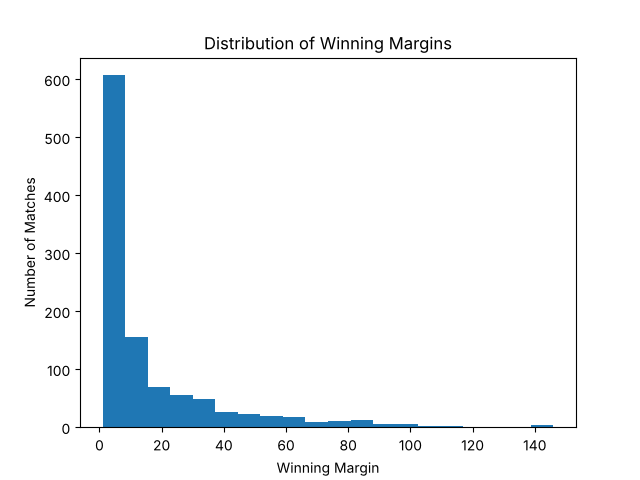

In [31]:
import matplotlib.pyplot as plt

matches_df['result_margin'].dropna().plot(
    kind='hist',
    bins=20
)

plt.title('Distribution of Winning Margins')
plt.xlabel('Winning Margin')
plt.ylabel('Number of Matches')
plt.show()

### Runs and wickets, separately

**Result (as saved):** run victories: 498 matches, mean 30.10, median 22. Wicket victories: 578 matches, mean 6.19, median 6, range 1 to 10.

**Insight:** run victories have larger and more spread-out margins. Wicket victories cluster at small values, and they are also the more common result type.

**Analyst lesson:** when two groups measure different things, analyse each group on its own scale. Averaging across units gives a number with no clear meaning.


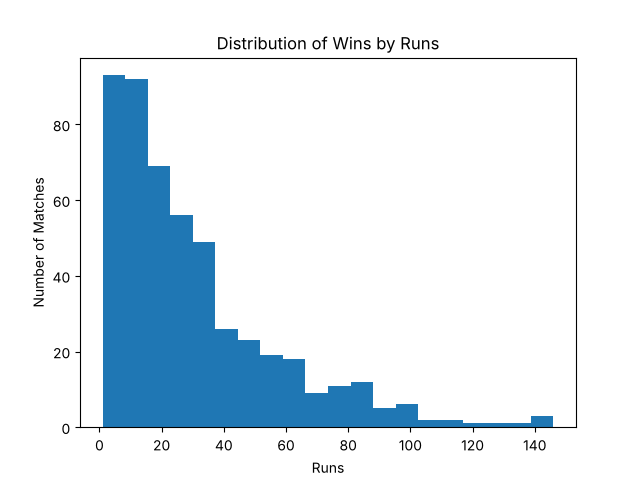

In [32]:
runs_margin = matches_df.loc[
    matches_df['result'] == 'runs',
    'result_margin'
].dropna()

runs_margin.plot(kind='hist', bins=20)

plt.title('Distribution of Wins by Runs')
plt.xlabel('Runs')
plt.ylabel('Number of Matches')
plt.show()

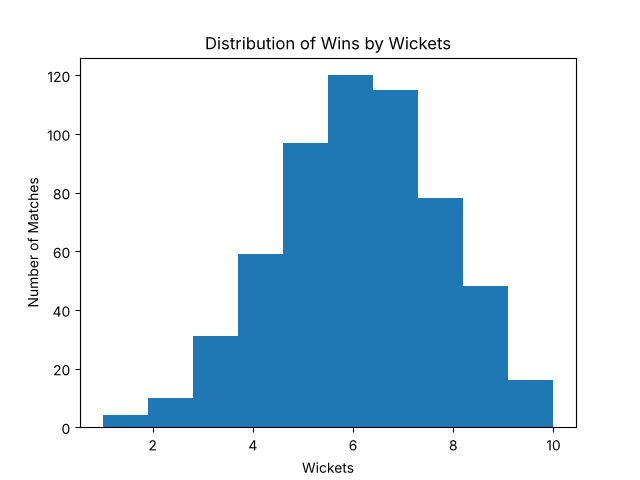

In [33]:
wicket_margin = matches_df.loc[
    matches_df['result'] == 'wickets',
    'result_margin'
].dropna()

wicket_margin.plot(kind='hist', bins=10)

plt.title('Distribution of Wins by Wickets')
plt.xlabel('Wickets')
plt.ylabel('Number of Matches')
plt.show()

## 3.6 Season Trends (Q10, Q11, Q28, Q29)

### Q10 — How many matches were played in each season?

Question:
How many matches were played in each season?

Method:
Count season values and sort chronologically.

Insight:
The number of matches varied by season.
2013 had the highest number in this dataset (76).
2022 and 2023 had 74 matches each.

Analyst thinking:
First identify the pattern.
Then investigate the reason behind the pattern.
Don't assume the cause from the count alone.

In [34]:
season_matches = matches_df['season'].value_counts().sort_index()

season_matches

season2007/08    582009       572009/10    602011       732012       742013       762014       602015       592016       602017       592018       602019       602020/21    602021       602022       742023       742024       71Name: count, dtype: int64

### Q11 — Which season had the most matches?

Code:
series.idxmax() → category with highest value
series.max()    → highest value

Result:
2013 → 76 matches

Insight:
2013 had the highest number of matches in the dataset.

In [35]:
season_matches.idxmax(), season_matches.max()

('2013', np.int64(76))

### Q28 — How did match types vary across seasons?

Question:
How did match types vary across IPL seasons?

Method:
pd.crosstab(season, match_type)

Rows:
season

Columns:
match_type

Insight:
League matches dominate every season, while playoff
match types vary according to the tournament structure.

Important:
Crosstab is useful for studying relationships between
two categorical variables.

In [36]:
season_match_type = pd.crosstab(
    matches_df['season'],
    matches_df['match_type']
)

season_match_type

match_type  3rd Place Play-Off  Elimination Final  ...  Qualifier 2  Semi Finalseason                                             ...                         2007/08                      0                  0  ...            0           22009                         0                  0  ...            0           22009/10                      1                  0  ...            0           22011                         0                  1  ...            1           02012                         0                  1  ...            1           02013                         0                  0  ...            1           02014                         0                  0  ...            1           02015                         0                  0  ...            1           02016                         0                  1  ...            1           02017                         0                  0  ...            1           02018                         0                  0  .

### Q29 — How did result types vary across seasons?

**Method:** `pd.crosstab(season, result)`.

**Result (as saved):** across the 17 season labels, wicket wins were more common than run wins in 12 seasons. Run wins were more common in three seasons: 2009/10, 2015 and 2023. The two were equal in 2013 and 2022. Ties never exceeded 4 in a single season.

**Insight:** the balance between runs and wickets shifts from season to season, and some seasons are close to even. Ties and no-results are rare in every season.


In [37]:
result_by_season = pd.crosstab(
    matches_df['season'],
    matches_df['result']
)

result_by_season

result   no result  runs  tie  wicketsseason                                2007/08          0    24    0       342009             0    27    1       292009/10          0    31    1       282011             1    33    0       392012             0    34    0       402013             0    37    2       372014             0    22    1       372015             2    32    1       242016             0    21    0       392017             0    26    1       322018             0    28    0       322019             1    22    2       352020/21          0    27    4       292021             0    22    1       372022             0    37    0       372023             1    40    0       332024             0    35    0       36

## 3.7 Players and Umpires (Q18, Q21, Q22)

### Q18 — Which players received the most Player of the Match awards?

Question:
Which players received the most Player of the Match awards?

Column:
player_of_match

Method:
value_counts()

Top player:
AB de Villiers → 25 awards

Insight:
AB de Villiers has the highest number of Player of the Match
awards in this dataset.

Important:
Awards ≠ overall player quality.
Players have different careers and numbers of matches.

In [38]:
player_awards = matches_df['player_of_match'].value_counts()

player_awards.head(10)

player_of_matchAB de Villiers    25CH Gayle          22RG Sharma         19DA Warner         18V Kohli           18MS Dhoni          17SR Watson         16YK Pathan         16RA Jadeja         16SP Narine         15Name: count, dtype: int64

### Q21 — Which umpires stood as umpire1 most often?

Question:
Which umpires officiated the most matches as umpire1?

Column:
umpire1

Method:
value_counts()

Result:
AK Chaudhary → 115 matches

Insight:
AK Chaudhary had the most umpire1 appearances.

Important:
Frequency ≠ performance or quality.

In [39]:
umpire1_matches = matches_df['umpire1'].value_counts()

umpire1_matches.head(10)

umpire1AK Chaudhary             115HDPK Dharmasena           79KN Ananthapadmanabhan     59CB Gaffaney               53Asad Rauf                 51Nitin Menon               50S Ravi                    48M Erasmus                 42Aleem Dar                 38BF Bowden                 36Name: count, dtype: int64

### Q22 — Who officiated the most matches across both positions?

Question:
Who officiated the most matches across both umpire positions?

Columns:
umpire1 + umpire2

Method:
pd.concat() → combine both columns
value_counts() → count appearances

Result:
AK Chaudhary → 131
S Ravi → 131

Insight:
AK Chaudhary and S Ravi have the highest total appearances,
with 131 each.

Important:
This measures appearances, not umpire performance.

In [40]:
all_umpires = pd.concat([
    matches_df['umpire1'],
    matches_df['umpire2']
])

all_umpires.value_counts().head(10)

S Ravi                   131AK Chaudhary             131Nitin Menon              104HDPK Dharmasena           98C Shamshuddin             88CB Gaffaney               77KN Ananthapadmanabhan     72M Erasmus                 67VK Sharma                 65BNJ Oxenford              64Name: count, dtype: int64

## 3.8 Toss Decision and Result Type (Q19)

### Q19 — How does the toss decision relate to the result type?

Question:
How does toss decision relate to match result type?

Method:
pd.crosstab(toss_decision, result)

Result:
Bat:
  Wickets → 207
  Runs    → 177
  Tie     → 6
  No result → 1

Field:
  Wickets → 371
  Runs    → 321
  Tie     → 8
  No result → 4

Important:
These are raw counts. Field was chosen more often,
so counts alone are not a fair comparison.

Analyst rule:
When group sizes differ, use percentages/rates for comparison.

In [41]:
pd.crosstab(
    matches_df['toss_decision'],
    matches_df['result']
)

result         no result  runs  tie  wicketstoss_decision                               bat                    1   177    6      207field                  4   321    8      371

## 3.9 Match Types, Super Overs and D/L (Q23–Q25)

### Q23 — What types of matches are in the dataset?

Question:
What types of matches are present in the dataset?

Column:
match_type

Method:
value_counts()

Result:
League → 1029 matches (~94%)
Final → 17
Qualifier 1 → 14
Qualifier 2 → 14
Eliminator → 11
Others → small numbers

Insight:
The dataset is dominated by League matches.
Only a small portion consists of playoff/final matches.

Analyst thinking:
Understand the composition of the dataset before comparing
different groups.

In [42]:
matches_df['match_type'].value_counts()

match_typeLeague                1029Final                   17Qualifier 1             14Qualifier 2             14Eliminator              11Semi Final               6Elimination Final        33rd Place Play-Off       1Name: count, dtype: int64

### Q24 — How common are Super Overs?

N → 98.72%
Y → 1.28%

Insight:
Super Overs were very rare, occurring in only about 1.28%
of matches in this dataset.

Code pattern:
value_counts() → count
normalize=True → proportion
* 100 → percentage

In [43]:
super_over_percentage = (
    matches_df['super_over'].value_counts(normalize=True) * 100
)

super_over_percentage

super_overN    98.721461Y     1.278539Name: proportion, dtype: float64

### Q25 — How common is the Duckworth-Lewis method?

D/L matches = 21
Total matches = 1095

D/L percentage = 1.92%

Insight:
Only about 1.92% of matches used the D/L method,
so rain-affected/D/L matches were relatively rare.

Important:
NaN in method means D/L was not recorded.
It should not automatically be treated as bad data.

**Note on `value_counts(normalize=True)`:** the next cell shows 100% for D/L. `value_counts()` ignores missing values by default, so that proportion is calculated only over the 21 matches where D/L was recorded. The share of all matches is 21 ÷ 1,095 = 1.92%, computed in the cell after.

In [44]:
method_percentage = (
    matches_df['method'].value_counts(normalize=True) * 100
)

method_percentage

methodD/L    100.0Name: proportion, dtype: float64

In [45]:
dl_percentage = (
    matches_df['method'].eq('D/L').sum()
    / len(matches_df)
) * 100

dl_percentage

np.float64(1.9178082191780823)

## 3.10 Target Runs and Overs (Q26–Q27)

### Q26 — What is the typical target score?

Question:
What is the typical target score?

Column:
target_runs

Method:
describe()

Result:
Mean   → 165.68
Median → 166
Min    → 43
Max    → 288
Count  → 1092

Insight:
The typical target was around 166 runs.
Mean and median are almost identical.

Data observation:
3 matches have no target_runs value.

Analyst mindset:
Compare mean and median to understand the distribution.

In [46]:
matches_df['target_runs'].describe()

count    1092.000000mean      165.684066std        33.427048min        43.00000025%       146.00000050%       166.00000075%       187.000000max       288.000000Name: target_runs, dtype: float64

### Q27 — How many overs were usually available?

Question:
How many overs were normally available when a target was set?

Column:
target_overs

Result:
Mean   → 19.76
Median → 20
Min    → 5
Max    → 20

Insight:
Most targets were based on the normal 20-over format.
Lower values indicate matches with reduced overs.

Data observation:
3 matches have no target_overs value.

Analyst mindset:
Minimum/maximum can reveal unusual or special cases
that need further investigation.

In [47]:
matches_df['target_overs'].describe()

count    1092.000000mean       19.759341std         1.581108min         5.00000025%        20.00000050%        20.00000075%        20.000000max        20.000000Name: target_overs, dtype: float64

## 3.11 Ball-by-Ball Analysis

The matches file answers questions about results. The deliveries file answers questions about how the runs were scored. We use the cleaned deliveries file from Module 2, so the analysis below uses the derived columns (`legal_ball`, `counts_as_wicket`, `phase`).

Run rates use legal balls only, and a run rate is runs per over (runs ÷ legal balls × 6). Run totals include extras, which is how a scorecard counts them.

### 3.12 Load the Cleaned Deliveries File

The next cell reloads the cleaned deliveries file saved in section 2.31.


In [48]:
# 3.12 Load the cleaned deliveries file
deliveries_df = pd.read_csv(DELIVERIES_CLEAN_PATH)
print("Deliveries loaded:", deliveries_df.shape)
print(deliveries_df[['batting_team', 'over', 'phase', 'legal_ball', 'counts_as_wicket']].head(3).to_string(index=False))


Deliveries loaded: (260920, 21)
         batting_team  over                 phase  legal_ball  counts_as_wicket
Kolkata Knight Riders     0 Powerplay (overs 1-6)        True             False
Kolkata Knight Riders     0 Powerplay (overs 1-6)        True             False
Kolkata Knight Riders     0 Powerplay (overs 1-6)       False             False


### 3.13 First-Innings Totals by Season

**Question:** has the typical first-innings total changed?

**Method:** sum `total_runs` for each innings, then summarise by season.

**Result:** the mean first-innings total rose from 161.0 in 2008 to 189.6 in 2024. The median rose from 160 to 185. The lowest mean was 150.3 in 2009. The highest first-innings total in the data is 287, by Sunrisers Hyderabad in 2024. Five of the top five first-innings totals were scored in 2013 or later.

**Insight:** scores have risen steadily since about 2018, and the 2022 to 2024 seasons are the highest. Averages describe the typical innings; the maximum shows what is possible.


             count   mean  median  max
season_year                           
2008            58  161.0   160.0  240
2009            57  150.3   149.0  211
2010            60  164.8   169.0  246
2011            73  152.4   156.0  232
2012            74  157.5   159.0  222
2013            76  155.9   158.0  263
2014            60  163.1   160.0  231
2015            59  166.3   167.0  235
2016            60  162.6   162.0  248
2017            59  165.8   163.0  230
2018            60  172.5   174.0  245
2019            60  166.7   169.0  232
2020            60  169.5   167.0  228
2021            60  159.3   157.5  235
2022            74  171.1   169.5  222
2023            74  182.7   183.5  257
2024            71  189.6   185.0  287

Highest first-innings totals:
 match_id  season_year                batting_team  total
  1426268         2024         Sunrisers Hyderabad    287
  1422126         2024         Sunrisers Hyderabad    277
  1422134         2024       Kolkata Knight Riders    

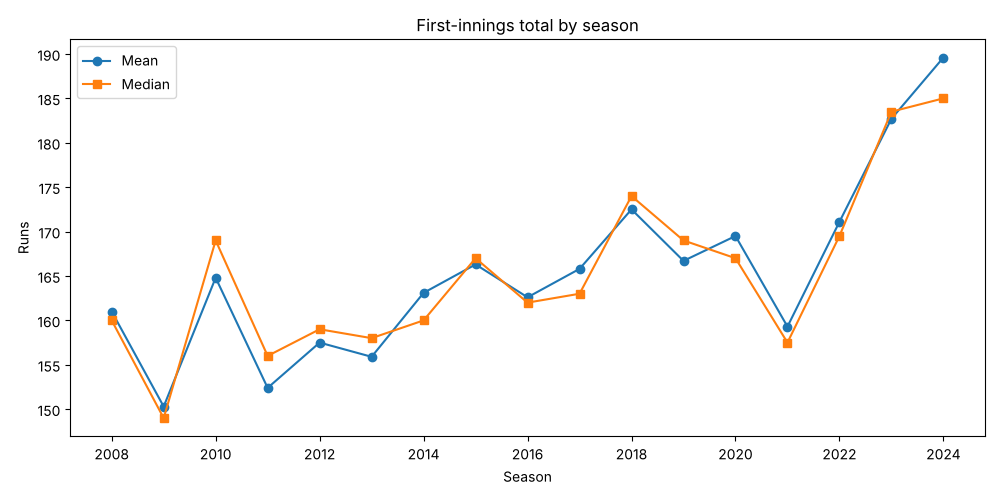

In [49]:
# 3.13 First-innings totals by season
innings_totals = (deliveries_df.groupby(['season_year', 'match_id', 'inning'])
                  .agg(total=('total_runs', 'sum'),
                       wickets=('counts_as_wicket', 'sum'),
                       batting_team=('batting_team', 'first'))
                  .reset_index())

first_innings = innings_totals[innings_totals['inning'] == 1]
season_scores = (first_innings.groupby('season_year')['total']
                 .agg(['count', 'mean', 'median', 'max']).round(1))
print(season_scores.to_string())

print("\nHighest first-innings totals:")
print(first_innings.nlargest(5, 'total')[['match_id', 'season_year', 'batting_team', 'total']].to_string(index=False))

plt.figure(figsize=(10, 5))
plt.plot(season_scores.index, season_scores['mean'], marker='o', label='Mean')
plt.plot(season_scores.index, season_scores['median'], marker='s', label='Median')
plt.title('First-innings total by season')
plt.xlabel('Season')
plt.ylabel('Runs')
plt.legend()
plt.tight_layout()
plt.show()


### 3.14 Run Rate by Phase of the Innings

**Question:** how has scoring changed in each phase of the innings?

**Method:** runs per over for the powerplay, middle overs and death overs, season by season.

**Result (runs per over, first and last season):**

| Phase | 2008 | 2024 |
|---|---|---|
| Powerplay (overs 1 to 6) | 7.28 | 9.11 |
| Middle (overs 7 to 15) | 7.68 | 8.53 |
| Death (overs 16 to 20) | 9.54 | 10.59 |

**Insight:** all three phases scored faster in 2024 than in 2008. The death-over rate was highest in 2024, and it dipped in 2021 (8.93) before rising again. The powerplay shows the largest relative increase: from 7.28 to 9.11 runs per over.


phase        Death (overs 16-20)  Middle (overs 7-15)  Powerplay (overs 1-6)
season_year                                                                 
2008                        9.54                 7.68                   7.28
2009                        8.74                 6.63                   6.86
2010                        9.23                 7.29                   7.48
2011                        8.76                 7.21                   6.83
2012                        9.18                 7.17                   6.95
2013                        9.24                 7.06                   6.68
2014                        9.68                 7.57                   7.22
2015                        9.94                 7.60                   7.43
2016                        9.77                 7.64                   7.39
2017                        9.29                 7.67                   8.05
2018                        9.75                 7.87                   8.20

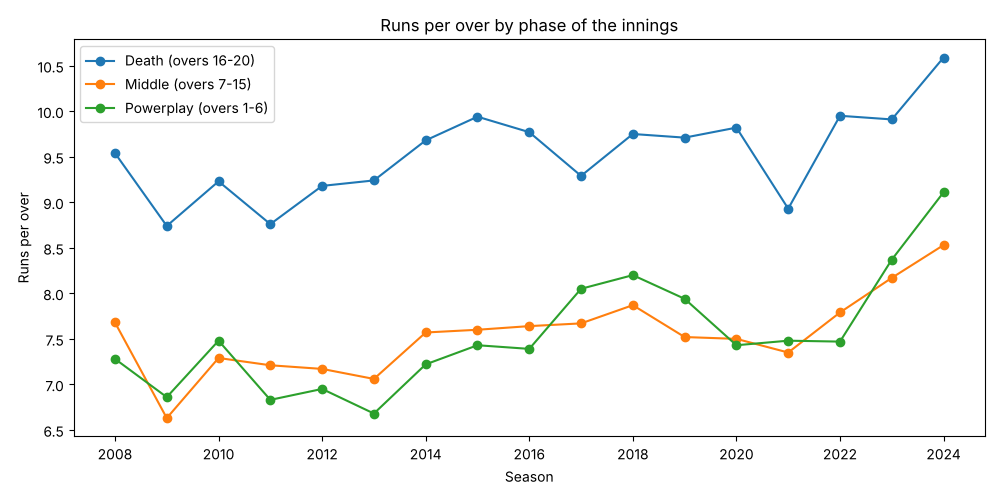

In [50]:
# 3.14 Run rate by phase of the innings, season by season
legal = deliveries_df[deliveries_df['legal_ball']]
phase_table = (legal.groupby(['season_year', 'phase'])
               .agg(runs=('total_runs', 'sum'), balls=('ball', 'size')))
phase_table['runs_per_over'] = phase_table['runs'] / phase_table['balls'] * 6
rate_table = phase_table['runs_per_over'].unstack('phase').round(2)
print(rate_table.to_string())

plt.figure(figsize=(10, 5))
for col in rate_table.columns:
    plt.plot(rate_table.index, rate_table[col], marker='o', label=col)
plt.title('Runs per over by phase of the innings')
plt.xlabel('Season')
plt.ylabel('Runs per over')
plt.legend()
plt.tight_layout()
plt.show()


### 3.15 Boundaries per Match

**Question:** are there more fours and sixes than before?

**Method:** count batter fours (4 runs off the bat) and sixes (6 runs off the bat), then divide by the number of matches in each season.

**Result:** boundaries per match rose from 40.1 in 2008 to 48.4 in 2024. In 2024 the data records 2,175 fours and 1,261 sixes in 71 matches, which is about 17.8 sixes per match. In 2008 it was about 10.7 sixes per match.

**Insight:** the rise in boundaries comes mainly from sixes. Fours per match barely changed, from about 29 in 2008 to about 31 in 2024 (1,703 fours in 58 matches, against 2,175 in 71).


In [51]:
# 3.15 Boundaries per match, season by season
# A four is a batter's 4 runs and a six is a batter's 6 runs (extras are not counted).
bounds = deliveries_df.assign(
    fours=(deliveries_df['batsman_runs'] == 4).astype(int),
    sixes=(deliveries_df['batsman_runs'] == 6).astype(int))

boundary_table = bounds.groupby('season_year').agg(
    matches=('match_id', 'nunique'), fours=('fours', 'sum'), sixes=('sixes', 'sum'))
boundary_table['boundaries_per_match'] = (boundary_table['fours'] + boundary_table['sixes']) / boundary_table['matches']
print(boundary_table.round(1).to_string())


             matches  fours  sixes  boundaries_per_match
season_year                                             
2008              58   1703    623                  40.1
2009              57   1321    508                  32.1
2010              60   1709    587                  38.3
2011              73   1916    639                  35.0
2012              74   1911    733                  35.7
2013              76   2054    681                  36.0
2014              60   1563    715                  38.0
2015              59   1611    692                  39.0
2016              60   1633    639                  37.9
2017              59   1612    706                  39.3
2018              60   1652    872                  42.1
2019              60   1655    786                  40.7
2020              60   1589    736                  38.8
2021              60   1551    687                  37.3
2022              74   2020   1062                  41.6
2023              74   2175   1

### 3.16 Leading Run-Scorers

**Question:** who scored the most runs across the seasons in the data?

**Method:** sum `batsman_runs` by batter. Strike rate is runs ÷ legal balls faced × 100. Wides are not counted as balls faced.

**Result:** Virat Kohli 8,014 runs (strike rate 132.4), Shikhar Dhawan 6,769 (127.6), Rohit Sharma 6,630 (131.6), David Warner 6,567 (140.3), Suresh Raina 5,536 (137.5), MS Dhoni 5,243 (138.3), AB de Villiers 5,181 (152.4), Chris Gayle 4,997 (150.0), Robin Uthappa 4,954 (130.9), Dinesh Karthik 4,843 (135.7).

**Note:** each strike rate is an average across all the seasons a batter played. Batter names are as recorded in the data.


In [52]:
# 3.16 Leading run-scorers
# Balls faced = legal deliveries faced by the batter (wides are not counted as balls faced).
batting = deliveries_df.groupby('batter').agg(
    runs=('batsman_runs', 'sum'),
    balls_faced=('legal_ball', 'sum'),
    matches=('match_id', 'nunique'))
batting['strike_rate'] = (batting['runs'] / batting['balls_faced'] * 100).round(1)
top_batters = batting.sort_values('runs', ascending=False).head(10)
print(top_batters.to_string())


                runs  balls_faced  matches  strike_rate
batter                                                 
V Kohli         8014         6051      244        132.4
S Dhawan        6769         5304      221        127.6
RG Sharma       6630         5039      251        131.6
DA Warner       6567         4682      184        140.3
SK Raina        5536         4025      200        137.5
MS Dhoni        5243         3790      228        138.3
AB de Villiers  5181         3400      170        152.4
CH Gayle        4997         3331      141        150.0
RV Uthappa      4954         3784      197        130.9
KD Karthik      4843         3570      233        135.7


### 3.17 Leading Wicket-Takers

**Question:** who took the most wickets?

**Method:** count dismissals credited to the bowler: caught, bowled, LBW, stumped, caught and bowled, and hit wicket. Run outs and retirements are not credited to the bowler.

**Result:** YS Chahal 205, PP Chawla 192, DJ Bravo 183, B Kumar 181, SP Narine 180, R Ashwin 180, A Mishra 174, SL Malinga 170, JJ Bumrah 168, RA Jadeja 160.

**Insight:** the list mixes spinners (Chahal, Chawla, Narine, Ashwin, Mishra, Jadeja) and pace or all-round bowlers (Bravo, Kumar, Malinga, Bumrah). The totals depend on career length, so comparing bowlers fairly needs rates, which this analysis does not give.


In [53]:
# 3.17 Leading wicket-takers
# Only dismissals credited to the bowler count here. Run outs and retirements are not credited.
BOWLER_CREDIT = ['caught', 'bowled', 'lbw', 'stumped', 'caught and bowled', 'hit wicket']
bowler_wickets = (deliveries_df[deliveries_df['counts_as_wicket'] &
                                deliveries_df['dismissal_kind'].isin(BOWLER_CREDIT)]
                  .groupby('bowler').size().sort_values(ascending=False).head(10))
print(bowler_wickets.to_string())


bowler
YS Chahal     205
PP Chawla     192
DJ Bravo      183
B Kumar       181
SP Narine     180
R Ashwin      180
A Mishra      174
SL Malinga    170
JJ Bumrah     168
RA Jadeja     160


### 3.18 Does the Side That Chases Win More Often?

**Question:** when a side chases a target, how often does it win?

**Method:** a wicket victory can only be won by the side that batted second, so the share of wicket victories among decided matches is the chasing side's win rate. Ties and no-results are excluded.

**Result:** the chasing side won 53.72% of decided matches (578 of 1,076). The rate varies by season: 42.9% in 2015 and 65.0% in 2016. Changes from season to season are based on about 60 matches each, so single seasons should not be over-read.


In [54]:
# 3.18 Does the side that chases win more often?
# A wicket victory can only happen to the side that batted second (the chasing side).
decided = matches_df[matches_df['result'].isin(['runs', 'wickets'])]
chase_by_season = (decided.assign(chaser_won=(decided['result'] == 'wickets'))
                   .groupby('season_year')['chaser_won']
                   .agg(['count', 'sum', 'mean']))
chase_by_season['chase_win_pct'] = (chase_by_season['mean'] * 100).round(1)
print(chase_by_season[['count', 'sum', 'chase_win_pct']].rename(columns={'sum': 'chaser_wins'}).to_string())
print("\nOverall chasing-side win rate:", round(decided['result'].eq('wickets').mean() * 100, 2), "%")


             count  chaser_wins  chase_win_pct
season_year                                   
2008            58           34           58.6
2009            56           29           51.8
2010            59           28           47.5
2011            72           39           54.2
2012            74           40           54.1
2013            74           37           50.0
2014            59           37           62.7
2015            56           24           42.9
2016            60           39           65.0
2017            58           32           55.2
2018            60           32           53.3
2019            57           35           61.4
2020            56           29           51.8
2021            59           37           62.7
2022            74           37           50.0
2023            73           33           45.2
2024            71           36           50.7

Overall chasing-side win rate: 53.72 %


## 3.19 Ball-by-Ball Findings

- Scoring rates rose in every phase of the innings between 2008 and 2024. The death overs and the powerplay both showed large increases.
- Sixes per match rose from about 11 in 2008 to about 18 in 2024. Fours per match barely changed.
- The first-innings average has risen since about 2018, and the highest totals have come in the last three seasons.
- The chasing side's win rate has moved between about 43% and 65% by season. Across all seasons, chasing won slightly more often than not.


## 3.20 Module 3 Summary

| Theme | Key finding (from the run) |
|---|---|
| Teams | Mumbai Indians has the most wins (144). Gujarat Titans has the highest win rate (62.22%), but from only 45 matches. |
| Toss | Toss winners won 554 of 1,095 matches (50.59%). The effect is small. |
| Toss decision | Toss winners who chose to field won 53.55% of their matches, against 45.27% for those who chose to bat. This is an association, not proof of cause. |
| Results | Wickets decided 578 matches and runs decided 498. |
| Margins | The median margin is 8. The mean (17.26) is pulled up by large run victories. The largest run margin (146) is verified in section 2.30. |
| Seasons | 2013 had the most matches (76). |
| Venues | Wankhede Stadium (118) after standardisation. |
| Cities | Mumbai (173), then Bangalore (94). |
| Players | AB de Villiers has the most Player of the Match awards (25). |
| Targets | The median target is 166 runs and the mean is 165.7. |
| Scoring (deliveries) | First-innings average rose from 161 runs in 2008 to 190 in 2024. Death-over run rate rose from 9.5 to 10.6. |
| Boundaries (deliveries) | Boundaries per match rose from 40 in 2008 to 48 in 2024. |
| Chasing (matches) | The chasing side won 53.72% of decided matches. |


# Module 4 — Data Visualisation

Charts make patterns easy to see, but only when they answer a question. Choose the chart from the data type and the question you are asking.

| Question | Data type | Chart | Why this chart |
|---|---|---|---|
| Which teams have the most wins? | Category against a count | Bar chart | Bar lengths are easy to compare |
| Which teams win the highest share of matches? | Category against a rate | Bar chart | Rates adjust for different numbers of matches |
| How are target scores spread out? | One numeric variable | Histogram | Shows shape, centre and spread |
| Are there unusually high or low targets? | One numeric variable | Box plot | Shows median, quartiles and outliers together |
| Which numeric variables move together? | Several numeric variables | Correlation heatmap | Shows every pairwise relationship at once |

Pie charts are hard to read with many categories, and 3D charts distort values, so this module avoids both.

**Improving any chart:** give it a title, label both axes with units, and keep tick labels readable (`plt.xticks(rotation=45, ha='right')` helps). Remove decoration that adds no information.


### Matplotlib basic pattern

import matplotlib.pyplot as plt
→ Import chart library

.head(10)
→ Select first 10 rows

.plot(kind='bar')
→ Create bar chart

plt.title()
→ Chart title

plt.xlabel()
→ X-axis name

plt.ylabel()
→ Y-axis name

plt.xticks(rotation=45)
→ Rotate category labels

plt.tight_layout()
→ Fix spacing

plt.show()
→ Display chart

## 4.1 Bar Chart — Total Wins by Team

Question:
Which IPL teams have won the most matches?

Data:
Categorical → winner
Numerical → number of wins

Chart:
Bar chart

Why?
Bar charts are useful for comparing different categories.

Code pattern:

value_counts()
        ↓
count categories
        ↓
plot(kind='bar')
        ↓
visual comparison

Important:
Choose the chart based on the question and data type.

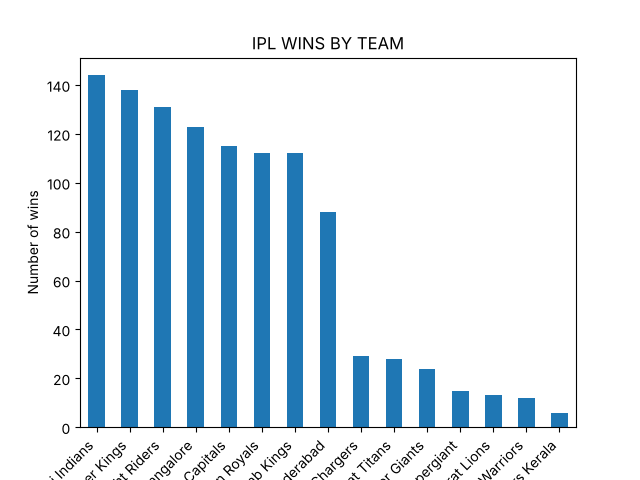

In [55]:
import matplotlib.pyplot as plt

winner_counts = matches_df['winner'].value_counts()

winner_counts.plot(kind='bar')

plt.title("IPL WINS BY TEAM")
plt.xlabel('Team')
plt.ylabel("Number of wins")
plt.xticks(rotation=45,ha="right")
plt.show()

INSIGHT:

Mumbai Indians have the highest number of wins in the dataset,
followed by Chennai Super Kings and Kolkata Knight Riders.

However, total wins alone cannot determine which team performed
best, because teams have played different numbers of matches.

Therefore, win percentage is a better metric for comparing
performance across teams.

## 4.2 Win Percentage by Team

Question:
Which teams have the highest win percentage?

Why:
Win percentage is more useful than total wins when comparing
teams that played different numbers of matches.

Formula:

Win Percentage = (Total Wins / Total Matches Played) × 100

Insight:
Win percentage gives a fairer comparison of team performance
than total win count alone.

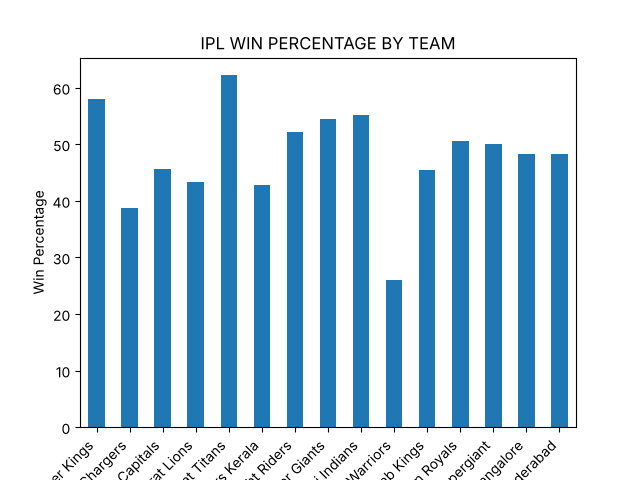

In [56]:
team_matches = pd.concat([
    matches_df['team1'],
    matches_df['team2']]).value_counts()

team_wins = matches_df['winner'].value_counts()

team_win_percentage = (team_wins / team_matches) * 100

team_win_percentage.sort_values(ascending=False)

team_win_percentage.plot(kind='bar')
plt.title("IPL WIN PERCENTAGE BY TEAM")
plt.xlabel('Team')
plt.ylabel("Win Percentage")
plt.xticks(rotation=45,ha="right")
plt.show()

INSIGHT:

Win percentage provides a fairer comparison than total wins
because teams have played different numbers of matches.

Gujarat Titans have the highest win percentage at approximately
62.2%.

However, Gujarat Titans have played fewer matches than several
long-established teams. Therefore, win percentage alone should
not be used to declare the overall best team.

Analyst lesson:
Always consider both the metric and the amount of data behind it.

## 4.3 Histogram — Distribution of Target Runs

Question:
How are target runs distributed across IPL matches?

Variable:
target_runs

Data type:
Numerical

Chart:
Histogram

Why?
A histogram shows the distribution of numerical data.

It helps us identify:
• Where values are concentrated
• Whether the distribution is symmetric or skewed
• The spread of the data
• Unusually low or high values

**Observation (from the chart):** most matches have targets between about 130 and 200 runs. The tallest bars sit around 150 to 180 runs. Very low targets (below about 100) and very high targets (above about 240) are rare. The overall shape is roughly bell-shaped.

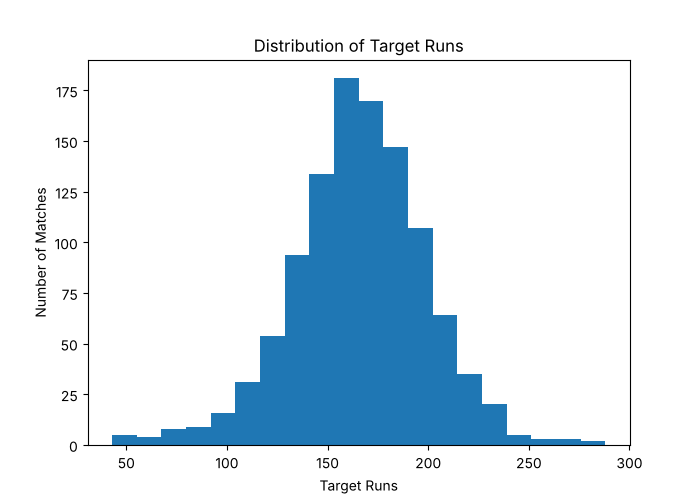

In [57]:
plt.figure(figsize=(7, 5))

plt.hist(
    matches_df['target_runs'].dropna(),
    bins=20
)

plt.title('Distribution of Target Runs')
plt.xlabel('Target Runs')
plt.ylabel('Number of Matches')

plt.show()

**Insight:** most IPL targets fall between roughly 130 and 200 runs. The mean (165.7) and the median (166) are almost identical, which suggests a roughly symmetric distribution centred near 166 runs.

**Analyst lesson:** a histogram answers four questions at once: where values cluster, whether the shape is symmetric or skewed, how spread out the values are, and whether unusual values exist. The number of bins changes how the chart looks, so try a few values before drawing conclusions.


## 4.4 Box Plot — Checking for Unusual Targets

Question:
Are there unusually low or high target scores?

Variable:
target_runs

Chart:
Box plot

Why?
A box plot shows the median, spread, and potential outliers.

Analyst lesson:
Outliers should not automatically be deleted.
First investigate whether they are genuine observations.

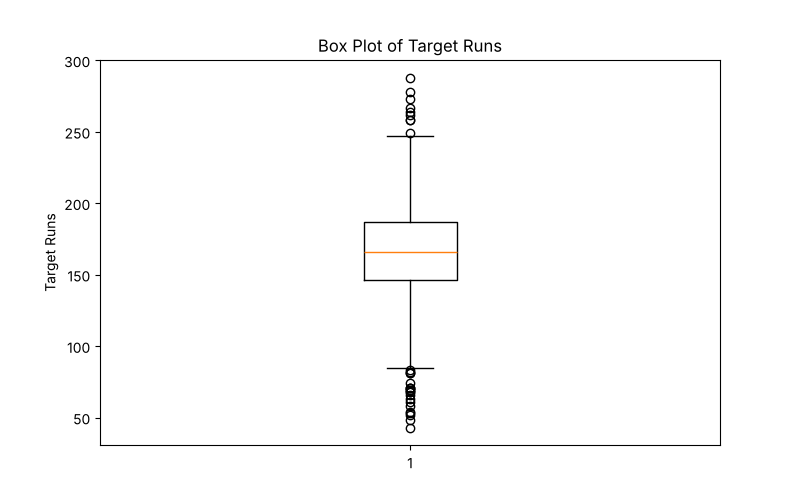

In [58]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    matches_df['target_runs'].dropna()
)

plt.title('Box Plot of Target Runs')
plt.ylabel('Target Runs')

plt.show()

### 4.5 Average Target Runs by Winning Team

**Question:** do teams that win tend to face higher or lower targets?

**Method:** `groupby('winner')['target_runs'].mean()`, then a bar chart.

**Result (as saved):** the highest averages are Lucknow Super Giants (183.8), Gujarat Titans (175.0) and Chennai Super Kings (168.9). The lowest in the output is Kochi Tuskers Kerala (141.2).

**Important caution:**
- `target_runs` is the score the chasing side had to reach. In a match won by chasing, the target is the score the winner chased. In a match won by defending, the target is the score the winner defended. The average therefore mixes two different situations.
- Sample sizes differ widely. Lucknow has 24 wins and Kochi has 6. A bar chart does not show this, so check the win counts (section 3.2) before reading too much into a single bar.

**Analyst lesson:** before comparing averages, ask what the number is actually measuring.


In [59]:
team_target_runs = matches_df.groupby('winner')['target_runs'].mean().sort_values(ascending=False)

team_target_runs

winnerLucknow Super Giants           183.833333Gujarat Titans                 174.964286Chennai Super Kings            168.855072Mumbai Indians                 167.756944Rajasthan Royals               167.267857Punjab Kings                   167.160714Royal Challengers Bangalore    167.089431Gujarat Lions                  166.307692Delhi Capitals                 165.208696Sunrisers Hyderabad            163.920455Kolkata Knight Riders          159.763359Deccan Chargers                158.517241Pune Warriors                  151.250000Rising Pune Supergiant         141.600000Kochi Tuskers Kerala           141.166667Name: target_runs, dtype: float64

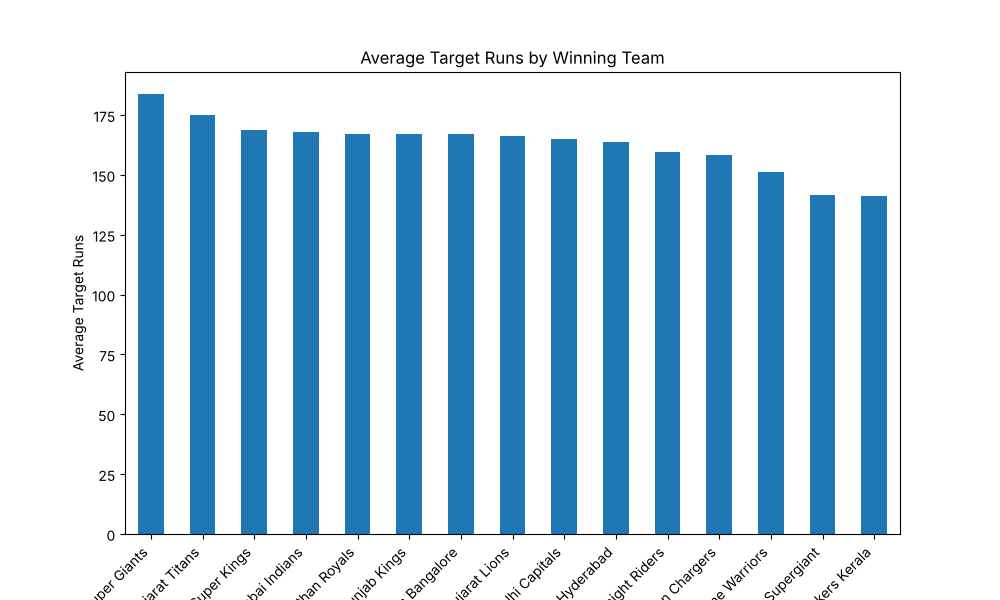

In [60]:
plt.figure(figsize=(10, 6))

team_target_runs.plot(kind='bar')

plt.title('Average Target Runs by Winning Team')
plt.xlabel('Team')
plt.ylabel('Average Target Runs')

plt.xticks(rotation=45,ha='right')
plt.show()

### 4.6 Correlation Heatmap

**What it shows:** correlation measures how strongly two numeric variables move together, from −1 (move in opposite directions) to +1 (move together). A value near 0 means there is no linear relationship.

**Results (as shown in the chart):**
- `target_runs` and `result_margin`: 0.40 (moderate positive)
- `target_runs` and `target_overs`: 0.35 (moderate positive)
- `result_margin` and `target_overs`: 0.03 (essentially none)

**Change in this revision:** the `id` column is now excluded. It is an identifier, so its correlations have no meaning. The code was changed, and the chart was re-drawn. The three values above are unchanged, because they do not involve `id`.

**Caveats**
1. **Correlation is not causation.** A moderate link does not show that one column causes the other.
2. **`result_margin` mixes units** (runs and wickets), so its correlations are hard to interpret. Analyse run margins and wicket margins separately.
3. **The `team1` convention changed in 2018** (section 2.30b), which affects any analysis of team order.

**Analyst lesson:** a heatmap is a quick screening tool. It tells you where to look, not what is true.


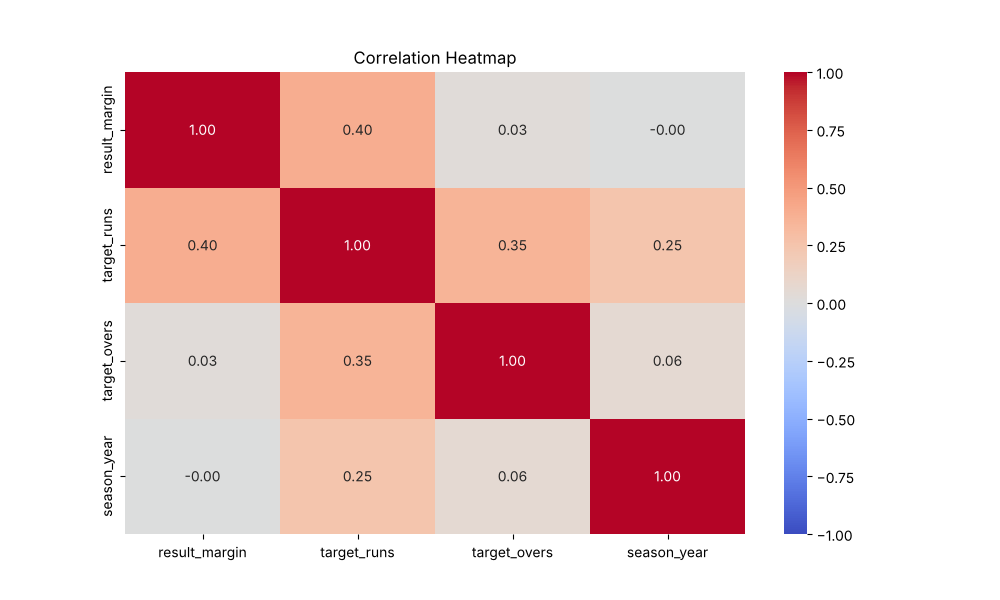

In [61]:
numeric_cols = matches_df.select_dtypes(include='number').drop(columns='id')

correlation = numeric_cols.corr()

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

## 4.7 Module 4 Summary

- Win percentage gives a fairer picture than raw wins, because teams played different numbers of matches.
- Target runs cluster in the middle of the range (about 130 to 200), with few very low or very high targets.
- Correlations are modest. The strongest one in the heatmap is between target runs and result margin (0.40), and it needs careful reading because the margin mixes units.
- Charts show patterns. They do not prove causes.


# Module 5 — Feature Engineering and Preparation

**Objective:** turn cleaned match information into *inputs* (features) and an *output* (target) that a model can learn from, without giving the model the answer.

**Key terms**
- **Feature:** an input column the model uses, such as `venue` or `toss_decision`.
- **Target:** the value the model predicts. In this project, the target is `winner`.
- **Categorical feature:** a category, such as a team name. It must be encoded as numbers.
- **Numerical feature:** a number, such as the 0/1 flag `toss_winner_is_team1`. It can usually be used as it is.
- **Encoding:** converting categories to numbers. One-hot encoding creates one 0/1 column per category.
- **Train–test split:** the model learns from one part of the data and is evaluated on another.
- **Pipeline:** a chain of preprocessing and modelling steps that is applied the same way every time.
- **Data leakage:** using information that would not be known when the prediction is made.

**Prediction timing (very important):** this model predicts the winner **after the toss but before the match result is known**. It uses toss information, so it cannot be used before the toss.


## 5.1 What Is Feature Engineering?

Feature = a useful input/column that helps us understand or predict something.

Feature engineering means:

Taking existing data and creating new useful columns from it.

Simple example

Suppose we have:

toss_winner = Mumbai Indians
winner      = Mumbai Indians

We can create:

toss_winner_won = 1

## 5.2 Target-Derived Features: A Warning

Several features below are built from the `winner` column. They are useful for learning how the data is constructed, but they would reveal the answer to the model. The model in Module 6 does not use them.

| Feature | Built from | Type | Used in the final model? | Reason |
|---|---|---|---|---|
| `toss_winner_won` | `toss_winner`, `winner` | Target-derived | No | Uses the answer |
| `team1_won`, `team2_won` | `team1`, `team2`, `winner` | Target-derived | No | Uses the answer |
| `is_tie` | `result` | Outcome-derived | No | Known only after the match |
| `toss_winner_is_team1` | `toss_winner`, `team1` | Pre-result | **Yes** | Known after the toss |
| `toss_decision_encoded` | `toss_decision` | Pre-result | No | The model uses `toss_decision` directly, one-hot encoded |
| `team1_batting_first` | `toss_winner`, `toss_decision`, teams | Pre-result | **Yes** | Known after the toss |
| `match_year`, `match_month`, `match_day`, `match_day_of_week` | `date` | Date parts | No | `season` already carries the timing |
| `season_number` | `match_year` | Duplicate | No | Same values as `match_year` |

The final model uses seven inputs: `season`, `team1`, `team2`, `venue` and `toss_decision` (categorical), plus `toss_winner_is_team1` and `team1_batting_first` (numerical).


## 5.3 Feature 1 — Toss Winner Won (target-derived)

**Concept:** a feature is a new column built from existing columns.

**Code idea:** compare two columns row by row. `==` returns True or False for each row, and `.astype(int)` converts True to 1 and False to 0.

**Why it matters:** this is a simple example of feature engineering, but it uses `winner`. Use it to learn the technique, not as a model input.

**Expected output:** a column of 0s and 1s. In the first rows, the toss winner did not always win (row 0 shows 0).


In [62]:
# ==========================================
# MODULE 4: FEATURE ENGINEERING
# Feature 1: Did the toss winner win?
# ==========================================

matches_df['toss_winner_won'] = (
    matches_df['toss_winner'] == matches_df['winner']
).astype(int)

# View the new feature
matches_df[
    ['toss_winner', 'winner', 'toss_winner_won']
].head(10)

                   toss_winner                       winner  toss_winner_won0  Royal Challengers Bangalore        Kolkata Knight Riders                01          Chennai Super Kings          Chennai Super Kings                12             Rajasthan Royals               Delhi Capitals                03               Mumbai Indians  Royal Challengers Bangalore                04              Deccan Chargers        Kolkata Knight Riders                05                 Punjab Kings             Rajasthan Royals                06              Deccan Chargers               Delhi Capitals                07               Mumbai Indians          Chennai Super Kings                08             Rajasthan Royals             Rajasthan Royals                19               Mumbai Indians                 Punjab Kings                0

## 5.4 Feature 2 — Team 1 Won (target-derived)

The same technique applied to `team1`. It uses `winner`, so it is excluded from the model. Note that `team1` is a label in the data, not a batting order.


In [63]:
# 4.3 Team Performance Features
# Feature 2: Did Team 1 win?
# ==========================================

matches_df['team1_won'] = (
    matches_df['team1'] == matches_df['winner']
).astype(int)

# Check the result
matches_df[
    ['team1', 'winner', 'team1_won']
].head(10)

                         team1                       winner  team1_won0  Royal Challengers Bangalore        Kolkata Knight Riders          01                 Punjab Kings          Chennai Super Kings          02               Delhi Capitals               Delhi Capitals          13               Mumbai Indians  Royal Challengers Bangalore          04        Kolkata Knight Riders        Kolkata Knight Riders          15             Rajasthan Royals             Rajasthan Royals          16              Deccan Chargers               Delhi Capitals          07          Chennai Super Kings          Chennai Super Kings          18              Deccan Chargers             Rajasthan Royals          09                 Punjab Kings                 Punjab Kings          1

## 5.5 Feature 3 — Team 2 Won (target-derived)

The same logic applied to `team2`. It is excluded from the model for the same reason as Feature 2.


In [64]:
# ==========================================
# Feature 3: Did Team 2 win?
# ==========================================

matches_df['team2_won'] = (
    matches_df['team2'] == matches_df['winner']
).astype(int)

# Check the result
matches_df[
    ['team2', 'winner', 'team2_won']
].head(10)

                         team2                       winner  team2_won0        Kolkata Knight Riders        Kolkata Knight Riders          11          Chennai Super Kings          Chennai Super Kings          12             Rajasthan Royals               Delhi Capitals          03  Royal Challengers Bangalore  Royal Challengers Bangalore          14              Deccan Chargers        Kolkata Knight Riders          05                 Punjab Kings             Rajasthan Royals          06               Delhi Capitals               Delhi Capitals          17               Mumbai Indians          Chennai Super Kings          08             Rajasthan Royals             Rajasthan Royals          19               Mumbai Indians                 Punjab Kings          0

## 5.6 Feature 4 — Toss Winner Is Team 1 (pre-result)

**Concept:** a yes/no flag built from the toss. `toss_winner_is_team1` is 1 if team 1 won the toss, and 0 otherwise.

**Why it is allowed:** the toss happens before the match, so the flag is known when the prediction is made. The feature does not use `winner` at all.


In [65]:
# ==========================================
# Feature 4: Was Team 1 the toss winner?
# ==========================================

matches_df['toss_winner_is_team1'] = (
    matches_df['toss_winner'] == matches_df['team1']
).astype(int)

# Check the result
matches_df[
    ['team1', 'team2', 'toss_winner', 'toss_winner_is_team1']
].head(10)

                         team1  ... toss_winner_is_team10  Royal Challengers Bangalore  ...                    11                 Punjab Kings  ...                    02               Delhi Capitals  ...                    03               Mumbai Indians  ...                    14        Kolkata Knight Riders  ...                    05             Rajasthan Royals  ...                    06              Deccan Chargers  ...                    17          Chennai Super Kings  ...                    08              Deccan Chargers  ...                    09                 Punjab Kings  ...                    0[10 rows x 4 columns]

## 5.7 Feature 5 — Encoding the Toss Decision

Categorical variables may need to be converted into numerical
representation before being used in machine learning.

For toss_decision:
bat   → 0
field → 1

This process is called categorical encoding.

In [66]:
# ==========================================
# Feature 5: Encode toss decision
# ==========================================

matches_df['toss_decision_encoded'] = (
    matches_df['toss_decision']
    .map({'bat': 0, 'field': 1})
)

# Check the result
matches_df[
    ['toss_decision', 'toss_decision_encoded']
].head(10)

  toss_decision  toss_decision_encoded0         field                      11           bat                      02           bat                      03           bat                      04           bat                      05           bat                      06           bat                      07         field                      18         field                      19         field                      1

## 5.8 Feature 6 — Date Features

From a datetime column, pandas can extract parts with `.dt.year`, `.dt.month`, `.dt.day` and `.dt.day_name()`. These can reveal seasonal patterns.

In this project, we create them for exploration. The model uses `season` instead, because the season label describes the tournament edition more directly.

**Expected output:** the first match is listed as 18 April 2008, a Friday.


In [67]:
# Convert date column to datetime
matches_df['date'] = pd.to_datetime(matches_df['date'])

# Check the data type
matches_df['date'].dtype

dtype('<M8[us]')

In [68]:
# ==========================================
# Feature 6: Date Features
# ==========================================

matches_df['match_year'] = matches_df['date'].dt.year
matches_df['match_month'] = matches_df['date'].dt.month
matches_df['match_day'] = matches_df['date'].dt.day
matches_df['match_day_of_week'] = matches_df['date'].dt.day_name()

# Check the new features
matches_df[
    ['date', 'match_year', 'match_month',
     'match_day', 'match_day_of_week']
].head(10)

        date  match_year  match_month  match_day match_day_of_week0 2008-04-18        2008            4         18            Friday1 2008-04-19        2008            4         19          Saturday2 2008-04-19        2008            4         19          Saturday3 2008-04-20        2008            4         20            Sunday4 2008-04-20        2008            4         20            Sunday5 2008-04-21        2008            4         21            Monday6 2008-04-22        2008            4         22           Tuesday7 2008-04-23        2008            4         23         Wednesday8 2008-04-24        2008            4         24          Thursday9 2008-04-25        2008            4         25            Friday

## 5.9 Season Number: A Check, Not a New Signal

`season_number` copies `match_year` into a new column. The printed rows confirm the copy.

Two observations:
1. The season label `2007/08` corresponds to the 2008 calendar year, as the `match_year` column shows. The label follows the source data's convention, so the label and the year describe the same tournament but are written in different formats.
2. Because `season_number` duplicates `match_year`, it adds no information. We do not use it.

**Analyst lesson:** before creating a feature, check whether a column with the same meaning already exists.


In [69]:
# Create a numerical season feature
matches_df['season_number'] = matches_df['match_year']

# Check
matches_df[
    ['season', 'date', 'season_number']
].head(10)

    season       date  season_number0  2007/08 2008-04-18           20081  2007/08 2008-04-19           20082  2007/08 2008-04-19           20083  2007/08 2008-04-20           20084  2007/08 2008-04-20           20085  2007/08 2008-04-21           20086  2007/08 2008-04-22           20087  2007/08 2008-04-23           20088  2007/08 2008-04-24           20089  2007/08 2008-04-25           2008

## 5.10 Feature 7 — Is Tie (outcome-derived)

`is_tie` is 1 when `result` is `tie`, and 0 otherwise. It describes the outcome, so it is known only after the match. It is therefore excluded. This is the same point as section 5.2: a feature is allowed only if the information exists before the prediction is made.


In [70]:
matches_df['is_tie'] = (
    matches_df['result'] == 'tie'
).astype(int)

matches_df[
    ['result', 'is_tie']
].head(10)

    result  is_tie0     runs       01     runs       02  wickets       03  wickets       04  wickets       05  wickets       06  wickets       07     runs       08  wickets       09     runs       0

## 5.11 Feature 8 — Team 1 Batting First (pre-result)

**Concept:** the batting order follows from the toss. If the toss winner chose to bat, the toss winner batted first. If the toss winner chose to field, the other team batted first.

**Logic in the code:** team 1 batted first if either
- team 1 won the toss and chose to bat, or
- team 2 won the toss and chose to field.

Otherwise, team 1 batted second.

**Why it matters:** this is known after the toss, so it is allowed. Check the logic by hand on a few rows: find the toss winner, the decision, and then the batting order.

**Caution (from section 2.30b):** from 2018 onwards the `team1` label is always the side that batted first, so this feature is always 1 in those seasons. Before 2018 it varies. In the test set (2022 to 2024) it is therefore constant, and it can have no effect on the test predictions.


In [71]:
# ==========================================
# Feature 8: Did Team 1 bat first?
# ==========================================

matches_df['team1_batting_first'] = (
    ((matches_df['toss_winner'] == matches_df['team1']) &
     (matches_df['toss_decision'] == 'bat'))
    |
    ((matches_df['toss_winner'] == matches_df['team2']) &
     (matches_df['toss_decision'] == 'field'))
).astype(int)

# Check the result
matches_df[
    ['team1', 'team2', 'toss_winner',
     'toss_decision', 'team1_batting_first']
].head(10)

                         team1  ... team1_batting_first0  Royal Challengers Bangalore  ...                   01                 Punjab Kings  ...                   02               Delhi Capitals  ...                   03               Mumbai Indians  ...                   14        Kolkata Knight Riders  ...                   05             Rajasthan Royals  ...                   06              Deccan Chargers  ...                   17          Chennai Super Kings  ...                   18              Deccan Chargers  ...                   19                 Punjab Kings  ...                   1[10 rows x 5 columns]

## 5.12 Data Leakage Check

DATA LEAKAGE

Data leakage occurs when information that would not be available
at prediction time is used as a model feature.

It can produce unrealistically high model performance because
the model has indirectly received information about the answer.

Golden rule:
Only use information that would genuinely be available at the
time the prediction is made.

## 5.13 Feature Selection

FEATURE SELECTION

Feature selection means choosing the most useful features for
the analysis or machine-learning problem.

We should consider:
1. Is the feature useful?
2. Is it available at prediction time?
3. Does it duplicate another feature?
4. Does it introduce data leakage?

More features do not automatically mean a better model.

Good feature engineering focuses on useful, meaningful and
leakage-free features.

In [72]:

# MODULE 4: FINAL FEATURE CHECK

# Features created during our learning
learning_features = [
    'toss_winner_won',
    'team1_won',
    'team2_won',
    'toss_winner_is_team1',
    'toss_decision_encoded',
    'team1_batting_first',
    'match_year',
    'match_month',
    'match_day',
    'match_day_of_week',
    'season_number',
    'is_tie'
]

# Display which created features exist
for feature in learning_features:
    if feature in matches_df.columns:
        print(f"Created: {feature}")

print("\nTotal match records:", len(matches_df))


Created: toss_winner_won
Created: team1_won
Created: team2_won
Created: toss_winner_is_team1
Created: toss_decision_encoded
Created: team1_batting_first
Created: match_year
Created: match_month
Created: match_day
Created: match_day_of_week
Created: season_number
Created: is_tie

Total match records: 1095


## 5.14 Preparing the Modelling Dataset

## 🎯 Objective
The goal of this module is to prepare our IPL dataset for machine learning. We select useful columns, remove incomplete records, convert dates into the correct format, and arrange matches chronologically before training our model.

## 💡 Why is data preparation important?
Machine-learning models need suitable, clean data to learn patterns. If the dataset contains missing values or unsuitable columns, the model may produce unreliable predictions or encounter errors.

## 📝 Code Explanation

**1. Selecting useful columns**

We select columns such as `season`, `team1`, `team2`, `venue`, and toss information because these may help predict the winning team.

- `model_columns` stores the names of the columns we want.
- `available_columns` checks which of those columns actually exist in our dataset.
- `.copy()` creates a separate DataFrame named `model_df`, keeping the original `matches_df` unchanged.

**2. Removing missing values**

`dropna(subset=required_columns)` removes rows where essential information is missing.

We require `team1`, `team2`, `winner`, and `date` because we need both teams, a known match winner for training, and a valid date for chronological splitting.

**3. Converting dates**

`pd.to_datetime()` converts the date column into Python's datetime format. This allows us to sort the matches correctly by date.

**4. Sorting the dataset**

`sort_values('date')` arranges matches from oldest to newest. `reset_index(drop=True)` creates a fresh sequential index after sorting.

Chronological ordering helps us train on earlier matches and evaluate the model on later matches, which better represents real-world prediction.

**5. Checking the prepared dataset**

- `len(model_df)` displays the number of rows remaining after cleaning.
- `model_df.columns.tolist()` displays the selected columns.
- `value_counts()` counts the number of wins for each team.
- `.head(10)` displays the ten teams with the highest win counts.

## 📚 Important Machine-Learning Terms

**Features (X):** Input information used by the model, such as team names, venue, and toss details.

**Target (y):** The outcome we want the model to predict. In this project, the target is `winner`.

**Data cleaning:** Removing or handling incomplete or unsuitable data.

**Chronological split:** Using older matches for training and newer matches for testing.

**Data leakage:** When information that reveals the answer is accidentally included in the model's inputs. We must not use `winner`, `result`, or `result_margin` as prediction features.

## ✅ Expected Outcome
After executing the code cell, we should have a cleaner DataFrame named `model_df`, ready for the next stage: preparing the input features and target for machine learning.

**Note:** Because this model uses toss information, it predicts the winner after the toss but before the match result is known.

In [73]:

# MODULE 5: DATA PREPARATION FOR MACHINE LEARNING

# Step 1: Select useful columns
model_columns = [
    'season',
    'team1',
    'team2',
    'venue',
    'toss_winner_is_team1',
    'toss_decision',
    'team1_batting_first',
    'winner',
    'date'
]

# Step 2: Keep only columns available in the dataset
available_columns = [
    col for col in model_columns
    if col in matches_df.columns
]

# Step 3: Create a separate DataFrame
model_df = matches_df[available_columns].copy()

# Step 4: Remove rows with missing essential values
required_columns = ['team1', 'team2', 'winner', 'date']
model_df = model_df.dropna(subset=required_columns)

# Step 5: Convert date column to datetime format
model_df['date'] = pd.to_datetime(model_df['date'])

# Step 6: Sort matches chronologically
model_df = (
    model_df.sort_values('date')
    .reset_index(drop=True)
)

# Step 7: Display the prepared dataset summary
print("MODULE 5: DATA PREPARATION COMPLETE")
print("-" * 40)

print("Rows available:", len(model_df))
print("Columns:", model_df.columns.tolist())

print("\nMissing values:")
print(model_df.isnull().sum())

print("\nTop 10 teams by match wins:")
print(model_df['winner'].value_counts().head(10))


MODULE 5: DATA PREPARATION COMPLETE
----------------------------------------
Rows available: 1090
Columns: ['season', 'team1', 'team2', 'venue', 'toss_winner_is_team1', 'toss_decision', 'team1_batting_first', 'winner', 'date']

Missing values:
season                  0
team1                   0
team2                   0
venue                   0
toss_winner_is_team1    0
toss_decision           0
team1_batting_first     0
winner                  0
date                    0
dtype: int64

Top 10 teams by match wins:
winner
Mumbai Indians                 144
Chennai Super Kings            138
Kolkata Knight Riders          131
Royal Challengers Bangalore    123
Delhi Capitals                 115
Rajasthan Royals               112
Punjab Kings                   112
Sunrisers Hyderabad             88
Deccan Chargers                 29
Gujarat Titans                  28
Name: count, dtype: int64


# Module 6 — Building and Training the Machine-Learning Model

## 🎯 Objective
In this module, we train a machine-learning model to predict the IPL match-winning team using selected match information available before the result is known. Because toss information is included among the features, this is a post-toss prediction setup, not a prediction made before the toss.

## 💡 Why are we doing this?
Preparing data alone is not enough. We must train a model to learn patterns from historical IPL matches and evaluate its predictions on matches it has not seen before.

## 📝 Code Explanation

**1. Selecting features and target**

- `X` contains input features such as the two teams, venue, season, and toss information. Since toss details are used, predictions assume the toss has already taken place.
- `y` contains the actual winning team, which the model learns to predict.
- We exclude `winner`, `result`, and `result_margin` from the input features to prevent data leakage.

**2. Splitting the data chronologically**

We use approximately 80% of the earlier matches for training and 20% of the later matches for testing. This simulates predicting future matches using historical data.

**3. Encoding categorical features**

Machine-learning models generally need numerical inputs. `OneHotEncoder` converts categories such as team names, venues, and toss decisions into numerical representations.

`handle_unknown='ignore'` allows the model to handle categories it did not encounter during training.

**4. Creating the pipeline**

A pipeline combines feature preprocessing and model training into one workflow, helping us apply the same transformations consistently.

**5. Training the Random Forest model**

`RandomForestClassifier` combines predictions from multiple decision trees to classify the winning team. The model learns patterns from the training data.

**6. Evaluating the model**

- **Accuracy:** The proportion of test matches for which the predicted winner matches the actual winner.
- **Classification report:** Shows precision, recall, and F1-score for each winning-team category.

## 📚 Important Terms

- **Training data:** Historical matches used to learn patterns.
- **Testing data:** Later matches used to evaluate predictions.
- **Classification:** Predicting a category, such as a team's name.
- **Accuracy:** Correct predictions divided by total test predictions.
- **Overfitting:** When a model learns the training data too closely and performs poorly on unseen matches.

## ✅ Expected Outcome
We will obtain a trained model and an initial evaluation of its predictive performance. The results are a starting point, not a guarantee of future match outcomes.

## 6.1 Why a Random Forest?

A **decision tree** asks a sequence of yes/no questions, such as "was team 1 the toss winner?", and ends in a prediction. One tree can be unstable: a small change in the data can change its questions.

A **Random Forest** builds many trees (here, 200). Each tree is trained on a random sample of the data and considers a random subset of features. The trees vote, and the majority becomes the prediction. Averaging many trees makes the result more stable.

**Why it suits this project**
- It handles a mix of encoded categorical and numerical inputs.
- It gives a sensible first result with little manual tuning.
- It provides feature-importance scores (section 7.3), which help explain the model.
- It is a standard baseline in machine-learning courses and interviews.

**Trade-off:** a forest is harder to explain than a single tree, and its importance scores need careful reading.


## 6.2 Hyperparameters in Plain Language

Hyperparameters are settings you choose before training. The model does not learn them from the data.

| Setting | Value here | Beginner explanation |
|---|---|---|
| `n_estimators` | 200 | Number of trees. More trees give more stable results, but take longer to train. |
| `random_state` | 42 | Fixes the random choices, so re-running gives the same result. The number itself is arbitrary. |
| `class_weight` | `'balanced'` | Gives teams with fewer wins more weight, so frequent winners such as Mumbai Indians do not dominate. |
| `OneHotEncoder(handle_unknown='ignore')` | — | Creates a 0/1 column per category. A category not seen in training becomes all zeros, instead of causing an error. |
| All other settings | Defaults | For example, the trees are not depth-limited. Tuning could test this. |


## 6.3 The Pipeline, Step by Step

```text
Input columns (7 features)
   │
   ├── categorical columns → OneHotEncoder → many 0/1 columns
   └── numerical columns   → passed through unchanged
                 │
                 ▼
        RandomForestClassifier (200 trees)
                 │
                 ▼
        Predicted winning team
```

A `Pipeline` bundles these steps into one object, so the same preprocessing is applied during training and during prediction. Preprocessing new data differently from the training data would produce unreliable predictions.

**Why the split is chronological:** a random split could train on 2024 matches and test on 2008 matches. That is unrealistic, because real prediction uses the past to predict the future. The code sorts matches by date, uses the first 80% for training, and the last 20% for testing. The test set holds every match with a winner from the 2022, 2023 and 2024 seasons (218 matches). The training set holds the 2007/08 to 2021 seasons. No season in the test set appears in the training set, so the one-hot `season` columns are all zeros for test matches.

### 6.4 Run the training code

The next cell splits the data, builds the pipeline, trains the model, makes predictions, and prints the results.


In [74]:

# MODULE 6: BUILDING AND EVALUATING THE MODEL

import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Step 1: Select input features (X) and target (y)
feature_columns = [
    'season',
    'team1',
    'team2',
    'venue',
    'toss_winner_is_team1',
    'toss_decision',
    'team1_batting_first'
]

X = model_df[feature_columns].copy()
y = model_df['winner'].copy()

# Step 2: Split chronologically: first 80% for training, last 20% for testing
split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training matches:", len(X_train))
print("Testing matches:", len(X_test))

# Step 3: Identify categorical and numerical features
categorical_features = [
    'season', 'team1', 'team2', 'venue', 'toss_decision'
]

numerical_features = [
    'toss_winner_is_team1', 'team1_batting_first'
]

# Step 4: Convert categorical values into numerical features
preprocessor = ColumnTransformer(
    transformers=[
        ('categorical',
         OneHotEncoder(handle_unknown='ignore'),
         categorical_features),
        ('numerical', 'passthrough', numerical_features)
    ]
)

# Step 5: Create the machine-learning pipeline
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced'
    ))
])

# Step 6: Train the model
model.fit(X_train, y_train)

# Step 7: Predict winners for the test matches
y_pred = model.predict(X_test)

# Step 8: Evaluate model performance
accuracy = accuracy_score(y_test, y_pred)

print("\nMODULE 6: MODEL EVALUATION")
print("-" * 40)
print(f"Test Accuracy: {accuracy:.2%}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))


Training matches: 872
Testing matches: 218

MODULE 6: MODEL EVALUATION
----------------------------------------
Test Accuracy: 43.12%

Classification Report:
                             precision    recall  f1-score   support

        Chennai Super Kings       0.44      0.67      0.53        21
             Delhi Capitals       0.38      0.47      0.42        19
             Gujarat Titans       0.00      0.00      0.00        28
      Kolkata Knight Riders       0.57      0.57      0.57        23
       Lucknow Super Giants       0.00      0.00      0.00        24
             Mumbai Indians       0.31      0.59      0.41        17
               Punjab Kings       0.26      0.33      0.29        18
           Rajasthan Royals       0.52      0.65      0.58        26
Royal Challengers Bangalore       0.61      0.48      0.54        23
        Sunrisers Hyderabad       0.42      0.74      0.54        19

                   accuracy                           0.43       218
            

## 6.5 Baselines: What Would a Simple Rule Achieve?

A model's accuracy means little on its own. We compare it with two simple rules that anyone could apply:

- **Baseline 1:** always predict the team with the most wins in the training period (Mumbai Indians).
- **Baseline 2:** predict that the toss winner wins. This uses only information available after the toss, the same as the model.

The cell below calculates both rules on the same test matches.


In [75]:
# 6.5 Baselines: how good is 'simple rule' prediction?
# Baseline 1: always predict the team with the most wins in the training period.
majority_team = y_train.value_counts().idxmax()
baseline_majority = (y_test == majority_team).mean()

# Baseline 2: predict that the toss winner wins. This uses only information available after the toss.
test_rows = model_df.loc[X_test.index]
toss_winner_pred = np.where(test_rows['toss_winner_is_team1'] == 1, test_rows['team1'], test_rows['team2'])
baseline_toss = (y_test.values == toss_winner_pred).mean()

print(f"Baseline 1, most-wins team ({majority_team}): {baseline_majority:.2%}")
print(f"Baseline 2, toss winner wins:               {baseline_toss:.2%}")
print(f"Random Forest model:                        {accuracy:.2%}")


Baseline 1, most-wins team (Mumbai Indians): 7.80%
Baseline 2, toss winner wins:               46.33%
Random Forest model:                        43.12%


## 6.6 Initial Results

**Overall:** the model predicted the winner correctly for 94 of 218 test matches, an accuracy of 43.12%. This is an experiment, not a reliable prediction system.

**It does not beat the toss rule.** The toss-winner rule scores 46.33% (101 of 218), higher than the model. The most-wins rule scores only 7.80%. Any model should be compared with the toss rule before its accuracy is reported.

**Team-level recall (from the classification report):**
- Chennai Super Kings: 0.67 (14 of 21 wins found).
- Sunrisers Hyderabad: 0.74 (14 of 19), the highest recall.
- Mumbai Indians: 0.59 (10 of 17).
- Gujarat Titans and Lucknow Super Giants: 0.00. The model never predicted either team.

**Why Gujarat Titans and Lucknow Super Giants score zero:** a model can only predict a team it has seen winning in the training data. Their entire win records fall inside the test period. Gujarat Titans has 28 wins in total, and all 28 are in the test set. Lucknow has 24 wins in total, and all 24 are in the test set.

**The arithmetic:** 52 test matches (23.85% of the test set) have a winner the model never saw during training, so those matches are wrong by construction. On the other 166 matches, the model is correct 94 times, which is 56.63%. Even a perfect model on those 166 matches would reach 166 ÷ 218 = 76.15% overall. Section 7.6 shows this in the confusion matrix.


# Module 7 — Model Evaluation

**Why evaluate?** A model can look good on the data it was trained on and still fail on new data. Evaluation asks two questions: how often is the model right on matches it has never seen, and where does it go wrong?

## 7.1 Metric Definitions with Examples from This Notebook

| Metric | Question it answers | Example from this notebook |
|---|---|---|
| **Accuracy** | Out of all test matches, how many predicted winners were correct? | 94 of 218 = 43.12% |
| **Precision** | When the model predicts team X, how often is it right? | Chennai Super Kings: 0.44. When the model picked CSK, it was right 44% of the time. |
| **Recall** | Of the matches team X actually won, how many did the model find? | Chennai Super Kings: 0.67. Of CSK's 21 test-set wins, the model identified 14 (67%). |
| **F1-score** | One number that balances precision and recall | Chennai Super Kings: 0.53 |
| **Support** | How many actual test matches the team won | Chennai Super Kings: 21 |
| **Macro average** | Simple average across teams; each team counts equally | F1 0.39 |
| **Weighted average** | Average weighted by support; teams with more test matches count more | F1 0.38 |

**Precision versus recall:** precision is about how trustworthy a prediction is. Recall is about how many real wins you catch. A model can raise recall by predicting one team very often, which lowers precision, so read them together.

**Why accuracy alone is not enough:** accuracy hides which teams are predicted well, and it does not show whether a simple rule would do as well. The classification report, the confusion matrix and the baselines in section 6.5 give the detail.


## 7.2 Confusion Matrix and Feature Importance

## 🎯 Objective
Visualize how well our IPL winner prediction model performs and identify which input features the model relies on most.

## 💡 Why are we doing this?
Accuracy gives us one overall score, but it does not tell us which teams the model predicts correctly or where it makes mistakes. Visualizations make the results easier to understand and explain during a project presentation.

## 📝 Code Explanation

**1. Confusion matrix**

A confusion matrix compares the actual winning teams with the teams predicted by the model.

- Rows represent actual teams.
- Columns represent predicted teams.
- The diagonal cells show correct predictions.
- Other cells show incorrect predictions.

**2. Feature importance**

Random Forest estimates how useful each feature was for making predictions.

We extract feature names from the preprocessing pipeline and match them with their importance scores. This helps us identify which features the model relied on most.

**3. Displaying the results**

Matplotlib creates the charts, while pandas organizes the feature-importance values into a readable table.

## 📚 Important Terms

- **Confusion matrix:** A table showing correct and incorrect classifications.
- **Feature importance:** An estimate of how much a feature contributes to the model's decisions.
- **Model interpretation:** Understanding how a model behaves rather than looking only at its accuracy.

## ⚠️ Important Note
Feature importance does not prove that a feature causes a team to win. Results can also be affected by historical data, team changes, and features that are missing from our dataset.

## ✅ Expected Outcome
We will obtain a confusion matrix and a ranked list of important features to help explain our model's performance.

TOP 15 IMPORTANT FEATURES
----------------------------------------
                                       Feature  Importance
              categorical__team2_Gujarat Lions    0.032361
            categorical__team2_Deccan Chargers    0.029906
                      categorical__season_2011    0.028612
               numerical__toss_winner_is_team1    0.028512
                numerical__team1_batting_first    0.028416
     categorical__team2_Rising Pune Supergiant    0.026125
              categorical__team2_Pune Warriors    0.024285
               categorical__team2_Punjab Kings    0.023913
      categorical__team2_Kolkata Knight Riders    0.022836
                categorical__toss_decision_bat    0.022602
              categorical__toss_decision_field    0.022344
categorical__team2_Royal Challengers Bangalore    0.021732
        categorical__team2_Chennai Super Kings    0.021636
           categorical__team2_Rajasthan Royals    0.021602
             categorical__team2_Mumbai Indians  

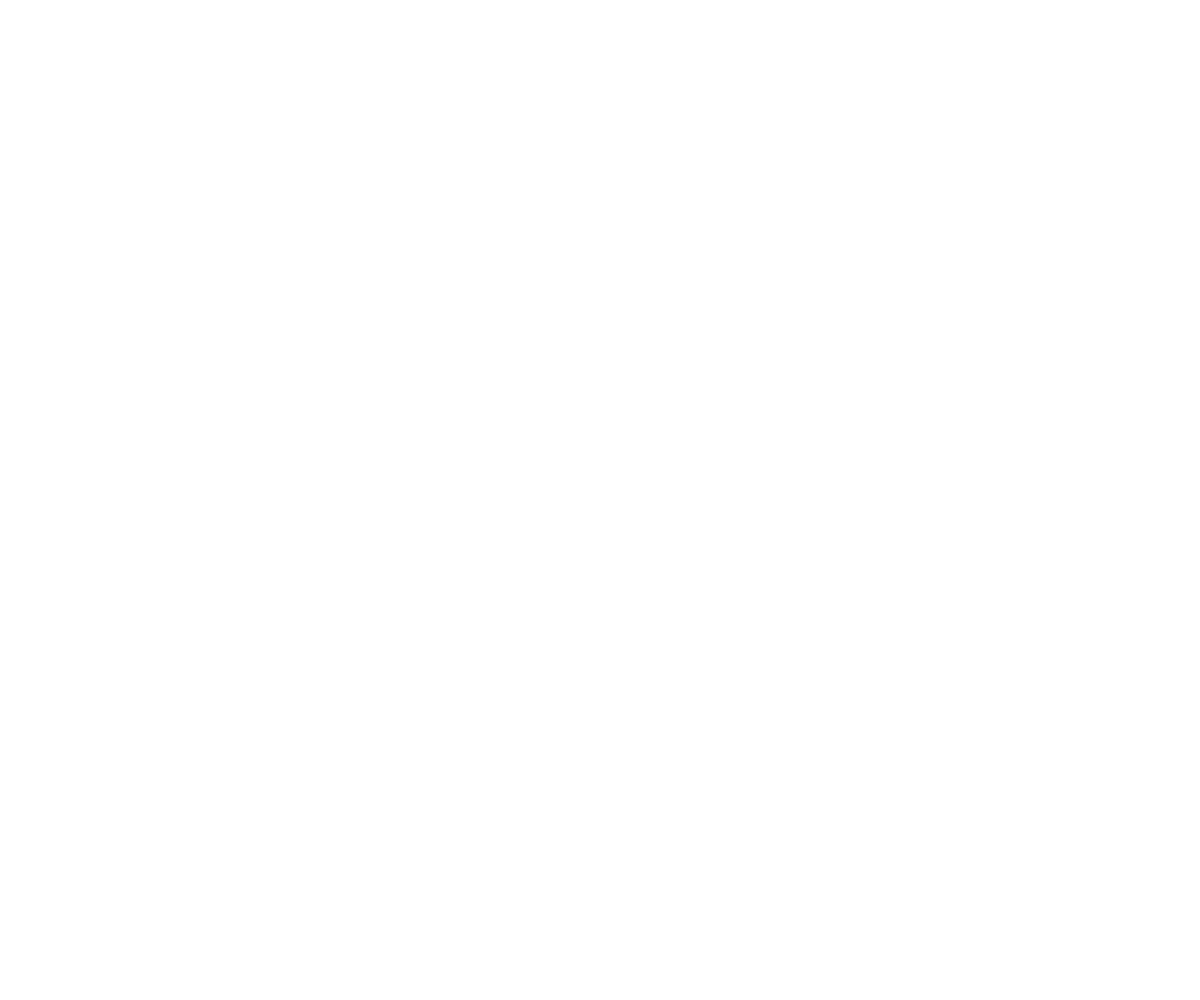

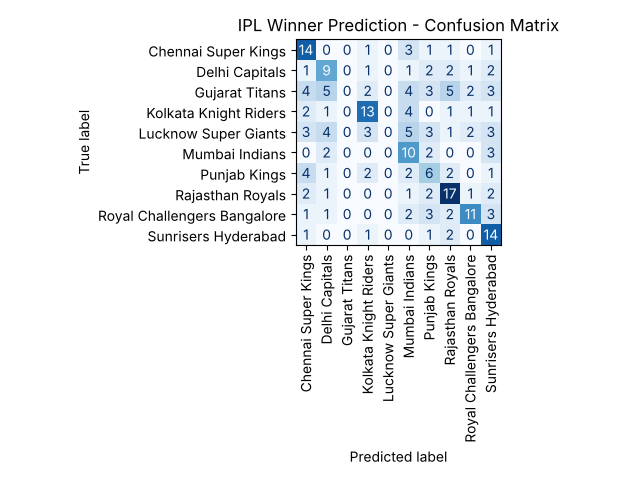

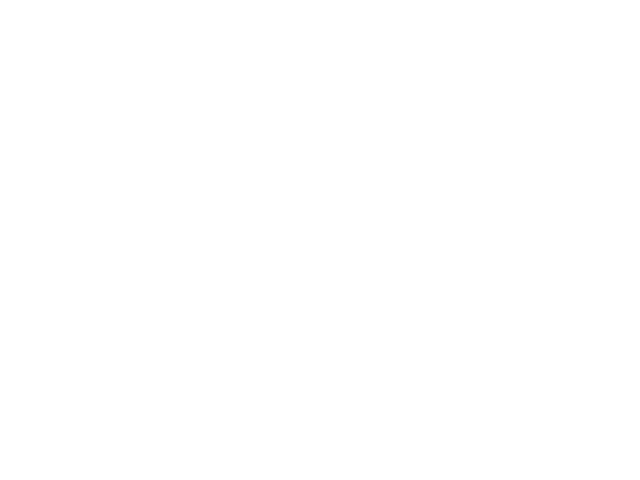

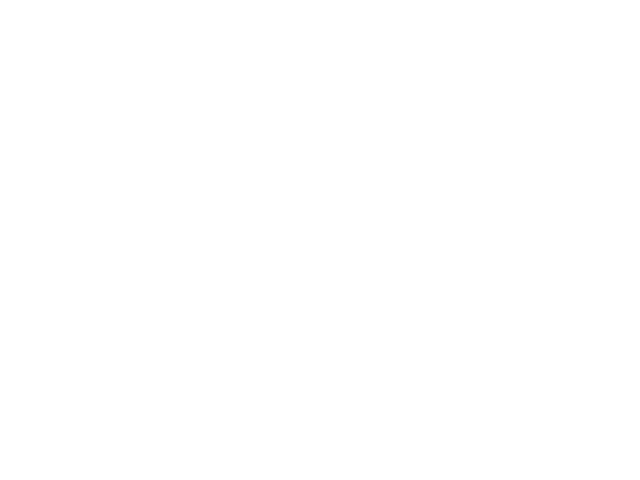

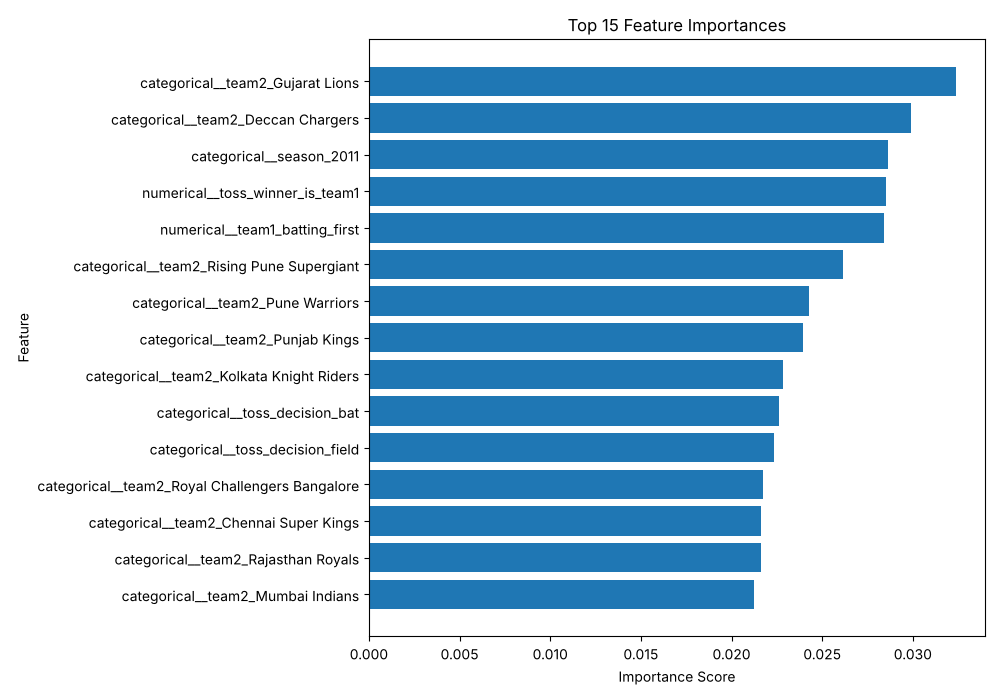

In [76]:

# MODULE 7: VISUALIZING MODEL PERFORMANCE

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Step 1: Plot the confusion matrix
plt.figure(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=90,
    cmap='Blues',
    colorbar=False
)

plt.title("IPL Winner Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()

# Step 2: Extract feature names after preprocessing
feature_names = (
    model.named_steps['preprocessor']
    .get_feature_names_out()
)

# Step 3: Get Random Forest feature importance scores
importance_scores = (
    model.named_steps['classifier'].feature_importances_
)

# Step 4: Create and sort the feature-importance table
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance_scores
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

# Step 5: Display the top 15 features
print("TOP 15 IMPORTANT FEATURES")
print("-" * 40)
print(importance_df.head(15).to_string(index=False))

# Step 6: Plot the top 15 features
top_features = importance_df.head(15).sort_values(
    by='Importance'
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.title("Top 15 Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


## 7.3 Feature Importance: Impurity-Based

The table ranks features by how much each one reduces impurity inside the trees during training. The top scores are close together (about 0.021 to 0.032), so no single feature dominates.

- **Top three:** `team2_Gujarat Lions` (0.0324), `team2_Deccan Chargers` (0.0299), `season_2011` (0.0286).
- **Toss information:** `toss_winner_is_team1` (0.0285) and `team1_batting_first` (0.0284) both appear in the top five. `toss_decision` appears twice, as `bat` (0.0226) and `field` (0.0223).
- **Team identities** make up most of the remaining top-15 features.

**Cautions**
1. **These scores describe the training period, not the test predictions.** The test seasons (2022 to 2024) do not appear in training, so the `season_*` columns contribute nothing to test predictions, even though `season_2011` ranks high here. Section 7.4 checks what the model actually uses on the test set.
2. **Importance is not causation.** A high rank for `team2_Gujarat Lions` does not mean that team caused wins. It has 13 wins in total.
3. **One-hot encoding spreads importance.** Each team has its own column, so a team's influence is shared across many columns.
4. **Impurity measures have a known bias.** They can overvalue features with many possible values. The permutation method in section 7.4 is a fairer check.


## 7.4 Permutation Importance: What the Model Uses on New Data

**Method:** on the test set, shuffle one input column at a time and measure how much accuracy falls. A large fall means the model depends on that column for test predictions. The method works on the original input columns and uses data the model did not train on, so it reflects what matters for prediction.

**Result (accuracy lost when the column is shuffled):**
- `team2`: 0.179 (± 0.023). The largest effect.
- `team1`: 0.122 (± 0.016).
- `venue`: −0.011 and `toss_decision`: −0.010. Shuffling these did not hurt accuracy.
- `toss_winner_is_team1`: −0.001.
- `season` and `team1_batting_first`: 0.000. **Both are constant on the test set.** Every test season is absent from training, and `team1_batting_first` is always 1 from 2018 onwards (section 2.30b). Shuffling a constant column changes nothing.

**Reading the result:** on new seasons, the model relies on the team identities, and the toss features add little. This matches the toss-rule result in section 6.6: the toss helps only a little, and the model does not use it well.


In [77]:
# 7.3 Permutation importance
# Shuffle one input column at a time in the test set, and measure how much accuracy drops.
# A large drop means the model relies on that column. Works on the original input columns.
from sklearn.inspection import permutation_importance

perm = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=42, scoring='accuracy')
perm_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Mean drop in accuracy': perm.importances_mean,
    'Std': perm.importances_std,
}).sort_values('Mean drop in accuracy', ascending=False)
print(perm_df.round(4).to_string(index=False))


             Feature  Mean drop in accuracy    Std
               team2                 0.1789 0.0234
               team1                 0.1216 0.0157
              season                 0.0000 0.0000
 team1_batting_first                 0.0000 0.0000
toss_winner_is_team1                -0.0009 0.0067
       toss_decision                -0.0096 0.0170
               venue                -0.0110 0.0147


## 7.5 Correct and Incorrect Predictions

The next cell compares the actual and predicted winner for every test match, prints the confusion matrix, and counts correct and incorrect predictions.

**How to read the matrix**
- Rows are actual winners. Columns are predicted winners.
- The diagonal (top-left to bottom-right) holds the correct predictions.
- Off-diagonal numbers are mistakes: the row is the actual winner, and the column is what the model predicted.
- Gujarat Titans and Lucknow Super Giants do not appear as rows or columns, because the model never learned them as winners (section 6.6).

**Note on the output:** the matrix is wide, and the notebook display may hide some columns. The full matrix is reproduced by the team-by-team figures in section 7.6.


In [78]:

# CHECK MODULE 7: CONFUSION MATRIX AND PREDICTIONS

from sklearn.metrics import confusion_matrix, accuracy_score
import pandas as pd

# 1. Compare actual winners with predicted winners
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

confusion_df = pd.DataFrame(
    cm,
    index=model.classes_,
    columns=model.classes_
)

print("CONFUSION MATRIX")
print("Rows = Actual winners | Columns = Predicted winners")
display(confusion_df)

# 2. Count correct and incorrect predictions
correct = (y_test == y_pred).sum()
incorrect = len(y_test) - correct

print("\nPREDICTION SUMMARY")
print("Total test matches:", len(y_test))
print("Correct predictions:", correct)
print("Incorrect predictions:", incorrect)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")

# 3. Show a sample of actual and predicted winners
comparison_df = pd.DataFrame({
    "Actual Winner": y_test,
    "Predicted Winner": y_pred
})

comparison_df["Correct"] = (
    comparison_df["Actual Winner"]
    == comparison_df["Predicted Winner"]
)

display(comparison_df.head(15))


CONFUSION MATRIX
Rows = Actual winners | Columns = Predicted winners

PREDICTION SUMMARY
Total test matches: 218
Correct predictions: 94
Incorrect predictions: 124
Accuracy: 43.12%


                             Chennai Super Kings  ...  Sunrisers HyderabadChennai Super Kings                           14  ...                    1Deccan Chargers                                0  ...                    0Delhi Capitals                                 1  ...                    2Gujarat Lions                                  0  ...                    0Kochi Tuskers Kerala                           0  ...                    0Kolkata Knight Riders                          2  ...                    1Mumbai Indians                                 0  ...                    3Pune Warriors                                  0  ...                    0Punjab Kings                                   4  ...                    1Rajasthan Royals                               2  ...                    2Rising Pune Supergiant                         0  ...                    0Royal Challengers Bangalore                    1  ...                    3Sunrisers Hyderabad                   

                   Actual Winner             Predicted Winner  Correct872        Kolkata Knight Riders          Chennai Super Kings    False873               Delhi Capitals               Mumbai Indians    False874                 Punjab Kings                 Punjab Kings     True875               Gujarat Titans               Mumbai Indians    False876             Rajasthan Royals          Sunrisers Hyderabad    False877  Royal Challengers Bangalore  Royal Challengers Bangalore     True878         Lucknow Super Giants          Chennai Super Kings    False879        Kolkata Knight Riders        Kolkata Knight Riders     True880             Rajasthan Royals               Mumbai Indians    False881               Gujarat Titans               Delhi Capitals    False882                 Punjab Kings          Chennai Super Kings    False883         Lucknow Super Giants          Sunrisers Hyderabad    False884  Royal Challengers Bangalore  Royal Challengers Bangalore     True885        Kolkata K

## 7.6 Confusion Matrix Insights

**Diagonal check:** the diagonal adds up to 94 (14 + 9 + 13 + 10 + 6 + 17 + 11 + 14). That matches the reported number of correct predictions. Use this kind of check whenever you read a confusion matrix.

**Team by team (correct predictions out of actual wins)**
- **Chennai Super Kings:** 14 of 21. Three misses went to Mumbai Indians.
- **Delhi Capitals:** 9 of 19. The misses are spread across several teams.
- **Kolkata Knight Riders:** 13 of 23. Four misses went to Mumbai Indians.
- **Mumbai Indians:** 10 of 17.
- **Punjab Kings:** 6 of 18. Four misses went to Chennai Super Kings. This is the weakest recall of the teams shown.
- **Rajasthan Royals:** 17 of 26.
- **Royal Challengers Bangalore:** 11 of 23.
- **Sunrisers Hyderabad:** 14 of 19.

**Structural limit:** the 52 wins by Gujarat Titans (28) and Lucknow Super Giants (24) can never be predicted correctly by this model, because the model has no training examples of them winning. Even a perfect model on the other 166 matches would reach 166 ÷ 218 = 76.15%. The actual model reaches 94 ÷ 218 = 43.12%.

**What this means:** the model identifies some teams' wins, but often confuses several teams with one another. It does not beat the toss rule. Treat its predictions as an experiment, not a forecast.


## 7.7 Model Limitations

| Limitation | Effect on results |
|---|---|
| Only seven inputs, all about teams, season, venue and toss | The model cannot see form, injuries, squad changes, the playing XI, pitch conditions or weather |
| No test season appears in training | The `season` inputs are zeros for every test match. The model cannot use season information for 2022 to 2024. |
| `team1_batting_first` is constant from 2018 | Its information disappears in the test set, because `team1` now records the batting side (section 2.30b) |
| Teams with no training-period wins | Gujarat Titans and Lucknow wins (52 test matches, 23.85%) are always predicted wrong |
| Does not beat the toss rule | The toss-winner rule scores 46.33% against the model's 43.12% (section 6.6) |
| Small test set (218 matches) | Accuracy depends on a small sample. For a sample of this size, a rough 95% margin is about ±6.5 percentage points (normal approximation). Small differences are not meaningful. |
| Impurity-based importance | Feature rankings describe training, not the test predictions (section 7.3) |

**Interpretation:** the 43.12% result is a baseline to learn from. It is below a simple toss rule, and it should not be reported as the expected accuracy for future IPL seasons.


# Module 8 — Final Insights and Conclusion

This module summarises what the project found. It separates the data-analytics findings from the machine-learning findings, and it lists limitations and next steps.

## 8.1 Saving the Trained Model

Training takes time, and we may want to use the model later without retraining it. `joblib.dump` saves the whole pipeline, including the encoder and the forest. `joblib.load` reloads it.

**Important:** the file is saved to the Colab session's local storage (`ipl_project_output/`). Colab deletes this storage when the session ends. To keep the model, copy the file to Google Drive. Loading it also requires the same libraries and a compatible scikit-learn version.


In [79]:

# MODULE 8: SAVE THE TRAINED MODEL

import joblib
import os

# Step 1: Create a folder for the project model
os.makedirs("ipl_project_output", exist_ok=True)

# Step 2: Save the complete trained pipeline
model_path = "ipl_project_output/ipl_winner_model.pkl"
joblib.dump(model, model_path)

# Step 3: Confirm that the model was saved
print("Model saved successfully!")
print("File path:", model_path)
print("File exists:", os.path.exists(model_path))

# Step 4: Load the saved model to verify it works
loaded_model = joblib.load(model_path)

print("Model loaded successfully!")

# Step 5: Make a sample prediction using test data
sample_prediction = loaded_model.predict(X_test.iloc[[0]])

print("Sample input:")
display(X_test.iloc[[0]])

print("Predicted winner:", sample_prediction[0])
print("Actual winner:", y_test.iloc[0])


Model saved successfully!
File path: ipl_project_output/ipl_winner_model.pkl
File exists: True
Model loaded successfully!
Sample input:
Predicted winner: Chennai Super Kings
Actual winner: Kolkata Knight Riders


    season                team1  ... toss_decision team1_batting_first872   2022  Chennai Super Kings  ...         field                   1[1 rows x 7 columns]

## 8.2 Data-Analytics Findings

| Topic | Finding (from the run) | Caution |
|---|---|---|
| Team wins | Mumbai Indians 144, Chennai Super Kings 138, Kolkata Knight Riders 131 | Teams played different numbers of matches |
| Win rate | Gujarat Titans 62.22% (28 of 45), Chennai 57.98%, Mumbai 55.17% | Gujarat Titans has few matches |
| Toss | Toss winners won 554 of 1,095 matches (50.59%) | Very small difference |
| Toss decision | Toss winners who fielded won 53.55%; those who batted won 45.27% | Association, not cause |
| Result type | Wickets 578, runs 498, ties 14, no result 5 | Describes how, not who |
| Margins | Median 8, mean 17.26 | Right-skewed; mixed units |
| Largest margin | 146 runs, verified against the deliveries file | Verified against ball-by-ball totals (section 2.30) |
| Seasons | 2013 had the most matches (76) | Season labels now have one year each |
| Venues | Wankhede Stadium 118, Eden Gardens 93 | After merging spellings and renames |
| Cities | Mumbai 173, Bangalore 94 | Bangalore and Bengaluru merged |
| Players | AB de Villiers 25 Player of the Match awards | Awards are not a measure of overall quality |
| Targets | Median 166 runs, mean 165.7 | Target is the score the chasing side had to reach |
| First innings | Mean 161 in 2008, 190 in 2024 | Averages for each season |
| Scoring phases | Death-over rate 9.5 to 10.6; powerplay 7.3 to 9.1 | Run rates include extras |
| Boundaries | About 40 per match in 2008, 48 in 2024 | Fours and sixes off the bat |
| Chasing | Chasing side won 53.72% of decided matches | Varies from 43% to 65% by season |
| Team order | Before 2018 `team1` was not always the batting side; from 2018 it always was | Data convention change |


## 8.3 Machine-Learning Findings

- The Random Forest model predicts the winning team after the toss, using teams, season, venue and toss information.
- Test accuracy is 43.12% (94 of 218 matches), on a chronological split with 872 training matches and 218 test matches.
- The simple toss-winner rule scores 46.33% on the same matches. **The model does not beat this rule.**
- 52 of the 218 test matches involve winners the model never saw in training, so they cannot be predicted correctly. On the other 166, accuracy is 56.63%.
- On the test set, the model's use of inputs is concentrated in the team identities. Permutation importance gives 0.18 for `team2` and 0.12 for `team1`; the toss features contribute little.
- No test season appears in the training data. The season inputs and `team1_batting_first` have no effect on test predictions.


## 8.4 Project Achievements

- An end-to-end workflow: loading, inspecting, cleaning, exploring, visualising, engineering features, training, evaluating and saving a model.
- A cleaned deliveries file with checks, derived columns, and a cross-check against the matches table. Every run margin and target in the matches file was tested against the ball-by-ball totals.
- Documented data-quality decisions: 51 cities recovered, city, venue and team names standardised, a single-year season column added, and legitimate missing values kept.
- A leakage-aware design: target-derived features excluded, and a chronological split used.
- Honest reporting: a baseline comparison that exposed the model's weakness, and limits stated with numbers.
- Reusable habits: a column dictionary, validation after each step, and charts that each answer a named question.

## 8.5 Limitations

The model's limitations are listed in section 7.7. The data and project limitations are listed in section 8.6, with each item's status.


## 8.6 Known Issues and Remaining Technical Work

Items marked **resolved** were found in the earlier review and fixed in this revision.

| # | Issue | Status | Evidence or action |
|---|---|---|---|
| 1 | City labels `Bangalore` and `Bengaluru` | Resolved | Section 2.20 |
| 2 | Venue labels split by suffixes and renames | Resolved (judgement on renames) | Section 2.21 lists the merges. The three renames are knowledge-based. |
| 3 | Season labels in mixed formats | Resolved | Section 2.22 adds `season_year`, checked against match dates |
| 4 | Deliveries file loaded but not analysed | Resolved | Sections 2.25 to 2.31 and 3.11 to 3.18 |
| 5 | `inning` goes up to 6 | Resolved | Section 2.30(e): innings 3 and above appear only in the 14 Super Over matches |
| 6 | Heatmap includes `id` | Resolved | Cell excludes `id` (section 4.6) |
| 7 | No baseline model | Resolved | Section 6.5. The toss rule beats the model. |
| 8 | Feature importance uses the impurity measure | Partly resolved | Permutation importance added (section 7.4). The impurity table is kept for comparison. |
| 9 | 146-run margin not checked | Resolved | Verified against the deliveries file, section 2.30(f) |
| 10 | Gujarat Titans and Lucknow winners never predicted (52 test matches) | Open | A structural limit of a chronological split. Possible approach: evaluate season by season, and use team features that include earlier seasons. |
| 11 | No test season appears in training | Open | The season inputs have no effect on test predictions. Possible approach: a split where each test season also appears in training. |
| 12 | `team1` batting order changed in 2018 | Open | Section 2.30b. Use a batting-order feature derived from the deliveries file, which is valid for every season. |
| 13 | 21 Duckworth-Lewis matches differ from the simple totals | Documented | Section 2.30. The D/L method recalculates the target, so these matches are expected to differ. |
| 14 | Overs with seven legal deliveries (29 overs, 19 innings with 121 legal balls) | Documented | Section 2.28. Likely a recording issue; run totals unaffected. |
| 15 | Heatmap mixes run and wicket margins | Documented | Analyse the two margin types separately |
| 16 | Saved model lives in the Colab session | Documented | Section 8.1. Copy the file to Drive to keep it. |
| 17 | Raw matches cleaning (sections 2.1 to 2.19) not re-run | Documented | The raw matches file was not supplied. Those outputs come from the original run. |


## 8.7 Realistic Future Improvements

1. Replace `team1_batting_first` with a batting-order feature from the deliveries file, which is valid for every season, and re-run the model.
2. Change the split so that each test season also appears in training, or evaluate season by season. This lets the season inputs carry information.
3. Build on the toss-rule baseline: a model should beat the simple toss rule before its accuracy is reported as useful.
4. Add pre-match team strength, such as recent form over the previous five matches, calculated only from earlier matches.
5. Use the deliveries data for team-level features, such as each team's average first-innings total in the previous season.
6. Compare the Random Forest with logistic regression and gradient boosting, using the same split.
7. Build a small interface (for example, with Streamlit) to demonstrate predictions, once the model beats the simple rules.


## 8.8 Conclusion

This project demonstrates an end-to-end analytics workflow on IPL match data. The descriptive analysis gives findings about team performance, toss effects, victory margins and scoring over time, and each number is tied to a run of the notebook. The deliveries analysis shows that scoring rates have risen in every phase of the innings, and that boundaries have increased sharply.

The predictive part is honest about its limits. The Random Forest reaches 43.12% accuracy, which is below a simple toss-winner rule (46.33%). Two teams never appear as winners in the training data, and no test season appears in training. Those are the lessons the notebook records.

The most important lesson is not the accuracy figure. It is the habit of checking, explaining and stating limits. The checks in this revision found a data convention change, a model that does not beat a simple rule, and a verified margin. Each is stated plainly.


# Module 9 — Fresher Interview Preparation

This module helps you explain the project clearly under pressure. Practise saying each answer out loud. Use your own words, but keep the numbers accurate.


## 9.1 Project Explanation in 30 Seconds

"I built an end-to-end IPL analytics project in Python and Google Colab. I cleaned 1,095 matches and 260,920 deliveries, standardised franchise, city and venue names, and checked the ball-by-ball data against the match results. I analysed win rates, toss effects, victory margins and scoring trends, then trained a Random Forest to predict the winner after the toss. It reached 43.12%, which is below a simple toss-winner rule of 46.33%, so I present it as a learning baseline, not a predictor."


## 9.2 Project Explanation in 2 Minutes

"The project starts with 1,095 IPL matches and 260,920 ball-by-ball deliveries. Before analysis, I checked the structure, missing values and duplicates. Most missing values had a real meaning, such as no-result matches, so I kept them. Team, city and venue names had changed over time, so I standardised them. Team names went from 19 labels to 15 franchises, and 58 venue labels became 39 grounds. A single-year season column was added, and I checked it against the match dates.

I cross-checked the deliveries against the match results. Targets, run margins and wicket margins agree with the ball-by-ball totals, apart from Duckworth-Lewis matches, which the method recalculates. The 146-run margin, the largest in the data, is confirmed by the ball-by-ball totals (212 minus 66).

For the analysis, I found that scoring rates rose in every phase of the innings between 2008 and 2024, and boundaries per match rose from about 40 to about 48. Raw wins were misleading because teams played different numbers of matches, so I used win percentage. Toss winners won 50.59% of matches, a very small edge.

For the model, I used only inputs available after the toss, and I excluded anything derived from the winner, to avoid data leakage. I split the data by date. A Random Forest reached 43.12%, but a simple rule, the toss winner wins, scores 46.33%. So the model does not yet beat a simple rule. I can explain why: two teams never appear as winners in the training data, no test season appears in training, and the batting-order feature is constant after 2018. Those are the next things to fix.


## 9.3 Detailed Technical Explanation

- **Data.** `matches.csv` has one row per match (1,095 rows). `deliveries.csv` has one row per ball (260,920 rows). Both are cleaned in Module 2.
- **Cleaning.** 51 missing `city` values recovered from `venue`. `Bengaluru` merged into `Bangalore`. Venue labels reduced from 58 to 39 by removing suffixes and merging three renamed grounds. Four renamed teams standardised (19 labels became 15), and the same mapping is applied to the deliveries. Legitimate missing values kept. `date` converted to datetime. A single-year `season_year` column added and checked against the dates.
- **Deliveries.** Derived columns `legal_ball`, `counts_as_wicket` and `phase`. A cross-check of innings totals against the matches file: targets, run margins and wicket margins agree except for Duckworth-Lewis matches.
- **EDA.** Win percentage = wins ÷ matches played, where matches played counts appearances in `team1` and `team2`. Toss association measured with a crosstab. Margins analysed by result type, because runs and wickets are different units.
- **Features.** Target-derived features excluded (`toss_winner_won`, `team1_won`, `team2_won`, `is_tie`). Model inputs: `season`, `team1`, `team2`, `venue` and `toss_decision` (one-hot encoded), plus `toss_winner_is_team1` and `team1_batting_first` (passed through).
- **Pipeline.** A `ColumnTransformer` applies `OneHotEncoder(handle_unknown='ignore')` to categorical columns. A `RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')` follows, inside a `Pipeline`.
- **Split.** Rows sorted by date. The first 80% (872 matches) train the model, and the last 20% (218 matches, the 2022 to 2024 seasons) test it.
- **Evaluation.** Accuracy 43.12%. Classification report with macro F1 0.39 and weighted F1 0.38. The confusion matrix diagonal sums to 94 correct predictions. Baselines: the most-wins team 7.80%, and the toss winner 46.33%.
- **Limits.** Two winning teams are absent from training (52 test matches). No test season appears in training. `team1_batting_first` is constant from 2018. Small test set, with a rough 95% margin of ±6.5 percentage points.


## 9.4 Twenty Likely Interview Questions

### Python and pandas

**1. What is a DataFrame, and how is it different from a list?**
A DataFrame is a two-dimensional table with labelled columns, and each column has its own data type. A list is a single sequence of values. `matches_df` has 1,095 rows and 22 columns in the cleaned file.

**2. What is the difference between `loc` and `iloc`?**
`loc` selects by label (column names or index labels). `iloc` selects by integer position. In Module 2 we used `loc` with a condition to fill missing cities. In Module 6 we used `iloc` to split the data by position.

**3. What does `value_counts()` do, and why did the D/L percentage show 100%?**
It counts how often each distinct value occurs. With `normalize=True` it returns proportions. By default it ignores missing values, so the 100% refers only to the 21 matches where D/L was recorded. Divide by the total number of matches to get the share of all matches: 21 ÷ 1,095 = 1.92%.

**4. Why use `.copy()` when creating `model_df`?**
It creates an independent DataFrame. Changes to `model_df` will not alter `matches_df`, and pandas will not warn that you are modifying a view of another DataFrame.

**5. Why keep NaN instead of filling missing values with 0?**
NaN means the value is missing or not applicable. Zero is a real value. Filling `target_runs` with 0 for no-result matches would falsely claim a target of zero.

### Data cleaning

**6. How did you handle the 51 missing city values?**
I used the venue. Two UAE stadiums map to Dubai (33 matches) and Sharjah (18). After filling, no city was missing, and I did not delete any rows.

**7. How did you handle team and venue renames?**
I mapped four historical team names to current franchise names, reducing 19 labels to 15. I merged a venue's suffix variants, and three renamed grounds, reducing 58 labels to 39. I did not merge genuinely different franchises, such as Deccan Chargers and Sunrisers Hyderabad.

**8. Why not delete the rows with no winner?**
Those five rows are no-result matches. They remain in the cleaned data for descriptive questions. They are excluded only when training the model, because the model needs a winner for every training row.

### Exploratory analysis and visualisation

**9. Why is win percentage better than total wins?**
Teams played different numbers of matches. Mumbai Indians has 144 wins from 261 matches (55.17%), while Gujarat Titans has 28 wins from 45 matches (62.22%). Win percentage puts them on the same scale.

**10. What does a large gap between mean and median tell you?**
The distribution is skewed. For victory margins, the mean (17.26) is more than double the median (8), so a few large wins pull the average up. The median is the better description of a typical margin here.

**11. Your toss analysis shows an association. Can you say that choosing to field causes wins?**
No. Toss winners who fielded won 53.55% of their matches, against 45.27% for those who batted. That is an association in historical data. Venue, team strength or conditions could explain some or all of it.

**12. Why use a histogram for target runs and a box plot for outliers?**
A histogram shows the shape and where values cluster. A box plot shows the median, quartiles and potential outliers in one compact view. Together they answer different questions about the same variable.

**13. What are the caveats of your correlation heatmap?**
The `id` column is an identifier, so it is now excluded. `result_margin` still mixes run and wicket margins, which have different units, so its correlations are hard to interpret.

### Feature engineering and machine learning

**14. What is data leakage? Give an example from this project.**
Leakage means using information that would not be available when the prediction is made. `toss_winner_won`, `team1_won` and `team2_won` are built from `winner`, so they reveal the answer. They are excluded from the model.

**15. Why did you use a chronological split?**
Real prediction uses past data to predict future matches. A random split could train on later seasons and test on earlier ones, which overstates how well the model would work in practice. Here, the training set covers 2007/08 to 2021 and the test set covers 2022 to 2024.

**16. When is this prediction made, and is `team1` a batting order?**
After the toss, but before the result. The model uses toss information, so it cannot run before the toss. `team1` is only a label before 2018. From 2018 onwards it is always the side that batted first, which makes `team1_batting_first` constant in the test set.

**17. What is one-hot encoding, and what does `handle_unknown='ignore'` do?**
One-hot encoding turns each category into its own 0/1 column. With `handle_unknown='ignore'`, a category not seen in training becomes all zeros, instead of raising an error. This is why the season inputs are zero for the 2022 to 2024 test matches.

**18. Why a Random Forest, and what does `class_weight='balanced'` do?**
A Random Forest combines 200 decision trees. It is a robust baseline that handles mixed inputs with little tuning. `class_weight='balanced'` gives teams with fewer wins more weight, so frequent winners do not dominate training.

### Model evaluation

**19. What are precision and recall? Give an example from your results.**
Precision is how often the model is right when it predicts a team. Recall is how many of a team's actual wins the model finds. For Chennai Super Kings, precision was 0.44 and recall 0.67. The model found 14 of their 21 test-set wins, but when it picked them it was right only 44% of the time.

**20. Is 43.12% accuracy good, and how do you know?**
It is above a rough reference of about 10%, which is what guessing uniformly among the ten test-set teams would give. But it is below the toss-winner rule (46.33%), so it is not yet useful. Gujarat Titans and Lucknow Super Giants account for 52 of the 218 test matches, and the model cannot predict those winners because it never saw them win in training. On the other 166 matches, accuracy is 56.63%. Always compare a model with a simple rule before reporting it.


## 9.5 Challenges Faced and How to Explain Them

These are challenges the notebook itself shows. Describe them honestly. Interviewers value problem-solving more than a perfect result.

1. **Inconsistent team, city and venue names.** Franchises changed names and some grounds appeared under several spellings. I listed the unique values, merged the variants, and checked the totals afterwards.
2. **Missing values with different meanings.** A blank winner or margin was not an error. The key step was telling "not recorded" from "not applicable".
3. **Missing cities.** I recovered them from venue names, after checking that each venue maps to one city.
4. **A model that does not beat a simple rule.** Instead of tuning until the number looked better, I added a baseline and found that the toss rule scores higher. I then traced the causes: no test season in training, and a batting-order feature that changed meaning in 2018.
5. **A data convention change.** I found that `team1` changed meaning in 2018, by comparing it with the ball-by-ball data. I stated the change, and the effect on the model, rather than hiding it.


## 9.6 Explaining the Model's Limitations Honestly

Use a short, calm script like this:

> "The model reaches 43% on a time-based test set, and I don't present it as a prediction tool. A simple rule, the toss winner wins, does a bit better at 46%. Two of the teams in the test set never appear as winners in the training data, so about a quarter of the test matches cannot be predicted by this approach. On the matches where that is not a problem, accuracy is about 57%. With only 218 test matches, the uncertainty is roughly ±6.5 percentage points. The next steps would be to fix the batting-order feature, change the split so that test seasons appear in training, and beat the toss rule before claiming anything."

**Rules for honest limitations**
- State the number first, then the condition under which it holds.
- Compare with a simple rule before claiming the model is useful.
- Name the specific cause, not a vague "the data is limited".
- Say what you would do next.


# Module 10 — Practical Revision and Learning Checklist

Use this module to revise before a review, a viva, or an interview.


## 10.1 Python and pandas Concepts and Functions

| Concept or function | Purpose | Where it is used |
|---|---|---|
| `pd.read_csv()` | Load a CSV file into a DataFrame | Section 1.5 |
| `head()`, `info()`, `describe()`, `dtypes` | Preview rows, see types, summarise numbers | Sections 1.7 to 1.9 |
| `isnull().sum()`, `isna()` | Count missing values | Section 2.1 |
| `duplicated()` | Find duplicate rows | Section 2.2 |
| `astype()`, `pd.to_datetime()` | Convert data types | Sections 2.11 and 2.12 |
| `value_counts()` | Count categories; `normalize=True` gives proportions | Module 3 |
| `groupby().agg()` | Summarise by group | Sections 3.5 and 4.5 |
| `pd.concat()` | Stack columns or tables | Section 3.2 |
| `pd.crosstab()` | Compare two categorical columns | Sections 3.3 and 3.6 |
| `loc[condition, column]` | Select or set rows and columns by label | Section 2.8 |
| `replace()`, `map()` | Replace values using a dictionary | Sections 2.6 and 5.7 |
| `dropna()`, `sort_values()`, `reset_index()` | Remove missing values, sort, reset the index | Sections 5.14 |
| `select_dtypes()`, `corr()` | Select numeric columns; compute correlations | Section 4.6 |
| `.copy()` | Create an independent DataFrame | Section 5.14 |
| `.dt.year`, `.dt.day_name()` | Extract parts of a date | Section 5.8 |
| `to_csv(index=False)` | Save without the row index | Section 2.23 |
| `plt.hist`, `plot(kind='bar')`, `plt.boxplot`, `sns.heatmap` | Charts | Module 4 |


## 10.2 Machine-Learning Concepts

| Concept | One-line explanation |
|---|---|
| Feature and target | The inputs the model uses, and the output it predicts |
| Categorical and numerical | Categories need encoding; numbers can usually be used directly |
| One-hot encoding | One 0/1 column per category |
| Pipeline | Preprocessing and model bundled into one object |
| Train–test split | Learn on one part of the data, evaluate on another |
| Chronological split | Train on earlier matches, test on later ones |
| Data leakage | Using information that is not available at prediction time |
| Random Forest | Many decision trees whose votes are combined |
| Hyperparameter | A setting chosen before training, such as `n_estimators` |
| Accuracy | Share of correct predictions |
| Precision, recall, F1 | How trustworthy a prediction is, how many real wins are caught, and their balance |
| Confusion matrix | Actual versus predicted counts for each class |
| Baseline | A simple reference model to compare against |
| Overfitting | Learning the training data too closely, so the model fails on new data |


## 10.3 Common Beginner Mistakes

| Mistake | Why it hurts | Fix |
|---|---|---|
| Running cells out of order | Variables are missing or stale, causing errors or wrong results | Run the notebook from the top after any change |
| Filling missing values with 0 | A real zero is invented | Ask what the blank means first |
| Deleting rows silently | Results change without a record | Count rows before and after every deletion |
| Comparing raw totals | Teams with more matches look better | Use rates such as win percentage |
| Reading percentages without checking NaN handling | `value_counts(normalize=True)` ignores missing values | Check the denominator |
| Using target-derived columns as inputs | The model appears to be accurate because it sees the answer | Exclude anything built from the target |
| Splitting time-ordered data randomly | Overstates performance | Split by date |
| Reporting accuracy alone | Hides which classes fail | Report the classification report and the confusion matrix |
| Treating correlation or importance as causation | Leads to false business advice | Say "associated with" and test further |
| Mixing units in one chart or average | The number has no meaning | Analyse each unit on its own scale |
| Renaming without checking | Two names for one entity split the statistics | Standardise and verify the totals |


## 10.4 Project Execution Checklist

Work through this list before you call the project finished.

☐ Google Drive contains `IPL_Data_Analytics/Data/raw/matches.csv` and `deliveries.csv`.
☐ Drive is mounted when prompted.
☐ The notebook runs from the top with no errors.
☐ `matches_df` is 1,095 × 20 and `deliveries_df` is 260,920 × 17 when first loaded.
☐ After cleaning, no duplicate rows, no missing cities, and 39 venue labels.
☐ `matches_cleaned.csv` (1,095 × 22) and `deliveries_cleaned.csv` (260,920 × 21) are saved to Drive.
☐ The 2.30 cross-check shows 146 verified and only Duckworth-Lewis mismatches.
☐ `model_df` has 1,090 rows, and the split is 872 training and 218 test.
☐ If the data is identical to the supplied files, accuracy is 43.12% and the toss-winner baseline is 46.33%.
☐ The model is saved, and you have copied it to Drive if you want to keep it.
☐ Known issues in section 8.6 are understood, not hidden.


## 10.5 Final Self-Assessment

Answer each question without looking at the notebook. If you cannot, revisit that module.

☐ Can I say what one row of `matches.csv` and one row of `deliveries.csv` represents?
☐ Can I explain why I kept some missing values and filled others?
☐ Can I explain why win percentage is fairer than total wins?
☐ Can I explain why the toss result is an association, not a cause?
☐ Can I name three target-derived features and explain why they are excluded?
☐ Can I explain why the split is chronological, and what it means that no test season is in training?
☐ Can I explain precision and recall with an example from the results?
☐ Can I explain why Gujarat Titans and Lucknow Super Giants score zero?
☐ Can I say whether the model beats the simple toss rule, and why that matters?
☐ Can I explain the team1 change in 2018 and its effect on the model?
☐ Can I give the 30-second and 2-minute project explanations?
☐ Can I state the model's limitations honestly, with numbers?


# Appendix — Reference Material

The three sections below are general reference notes. They are kept here so the main modules stay focused on this project.


# Appendix A — Data Cleaning: Analyst Mindset

## Goal

Data cleaning does NOT mean removing all missing values or changing everything.

The goal is:

> Make the data reliable for analysis without destroying meaningful information.

---

## 1. First understand the dataset

Before cleaning, ask:

- What does each column mean?
- Which columns are important?
- What type of data is each column?
- What problems exist?

I should NOT start changing data blindly.

---

## 2. Missing Values

First check:

`df.isnull().sum()`

Then ask:

> Why is this value missing?

A missing value can mean:
- Data was not collected
- Information is not applicable
- Event did not happen
- Data is genuinely missing

### Decision pattern

Missing value
↓
Investigate the row/context
↓
Understand WHY it is missing
↓
Choose the correct action

Possible actions:
- Fill it
- Keep it as NaN
- Recover it from another column
- Remove it only when justified

### IPL examples

`city` missing:
→ Venue gave us enough information
→ Recover city

`winner` missing:
→ Match had no result
→ Keep NaN

`method` missing:
→ No D/L method was applicable
→ Keep NaN

IMPORTANT:
Never replace meaningful NaN with 0 just to remove missing values.

---

## 3. Duplicate Rows

Check:

`df.duplicated().sum()`

Question:

> Is the same record appearing more than once?

If duplicates exist:
→ investigate first
→ remove only if they are genuinely duplicate records.

Our result:
0 duplicates.

---

## 4. Data Types

Check:

`df.dtypes`

Ask:

> Is each column stored in a type suitable for its meaning?

Examples:

ID → integer
Name/team → text
Measurement → numeric
Date → datetime

IPL example:

`date` was object/text
↓
converted to datetime

Why?
Because later we can:
- sort by date
- extract year/month
- perform time analysis

---

## 5. Categorical Consistency

For categorical columns, inspect:

`df['column'].value_counts()`

Ask:

> Are the values consistent?

Look for:
- spelling differences
- capitalization differences
- unexpected categories
- old/new names

IPL example:

Royal Challengers Bengaluru
→ Royal Challengers Bangalore

Kings XI Punjab
→ Punjab Kings

These were standardized because they represent the same franchise for our analysis.

IMPORTANT:

Rare does NOT mean wrong.

A value appearing only once can still be valid.

---

## 6. Numeric Validation

For important numeric columns:

`df[['columns']].describe()`

Don't blindly focus on mean/std.

For cleaning, first ask:

> Are the minimum and maximum values realistic?

Example:

`target_overs`
→ minimum 5
→ maximum 20
→ reasonable

If we found:
`target_overs = -5`
or
`target_overs = 500`

→ investigate.

---

# THE MOST IMPORTANT CLEANING MINDSET

For EVERY dataset:

        PROFILE
           ↓
    FIND POTENTIAL PROBLEMS
           ↓
       INVESTIGATE
           ↓
    UNDERSTAND THE MEANING
           ↓
     MAKE A DECISION
           ↓
       VALIDATE AGAIN
           ↓
       SAVE CLEAN DATA

Never:

        Find NaN
           ↓
      Fill everything

Never:

        Find unusual value
           ↓
         Delete it

Always ask:

> "What does this value mean in the real world?"

---

# WHY DID WE SELECT THESE COLUMNS?

We did NOT randomly choose columns.

We prioritized columns where data-quality problems could affect analysis:

### Missing-value columns

We selected them because they actually had missing values:

- city
- player_of_match
- winner
- result_margin
- target_runs
- target_overs
- method

### Categorical columns

We inspected them because inconsistent categories can create incorrect groups:

- team1
- team2
- toss_winner
- winner
- toss_decision
- result
- super_over
- match_type
- season
- method

### Numeric columns

We checked them because impossible numbers can damage calculations:

- result_margin
- target_runs
- target_overs

### Date

We checked `date` because time-based analysis requires a proper datetime type.

---

# THE 7 QUESTIONS I SHOULD ASK IN ANY NEW DATASET

Before analyzing a new dataset, ask:

1. **What does each important column mean?**
2. **How many rows and columns do I have?**
3. **Where are the missing values?**
4. **Are there duplicate records?**
5. **Are data types appropriate?**
6. **Are categories consistent?**
7. **Are numeric values realistic?**

Then:

> **Validate → Save → Start EDA**

---

# ⭐ One sentence to remember

> **A Data Analyst doesn't clean data to make it look perfect; they clean data to make it trustworthy for the question they want to answer.**

# Appendix B — Data Cleaning: Reusable Code Patterns

## 1. Check missing values

# Missing values in every column
df.isnull().sum()

# Missing-value percentage
df.isnull().mean() * 100

# Find rows where a specific column is missing
df[df['column'].isna()]


## 2. Check duplicates

# Count duplicate rows
df.duplicated().sum()

# Display duplicate rows
df[df.duplicated()]


## 3. Check data types

# Data type of every column
df.dtypes

# Complete DataFrame information
df.info()


## 4. Check categorical values

# Count each unique value
df['column'].value_counts()

# Include missing values
df['column'].value_counts(dropna=False)


## 5. Check unique values

# See all unique values
df['column'].unique()

# Count number of unique values
df['column'].nunique()


## 6. Check numeric columns

# Statistical summary
df[['column1', 'column2']].describe()

# Minimum
df['column'].min()

# Maximum
df['column'].max()


## 7. Convert dates

# Convert a column to datetime
df['date'] = pd.to_datetime(df['date'])


## 8. Replace inconsistent values

# Replace one or more incorrect/inconsistent values
df['column'] = df['column'].replace({
    'old_value': 'new_value'
})


## 9. Fill missing values

# Only use after understanding WHY the value is missing
df['column'] = df['column'].fillna(value)


## 10. Filter rows

# One condition
df[df['column'] == 'value']

# Multiple conditions — AND
df[(df['column1'] == 'A') & (df['column2'] > 10)]

# Multiple conditions — OR
df[(df['column1'] == 'A') | (df['column1'] == 'B')]


## 11. Save cleaned dataset

df.to_csv('cleaned_data.csv', index=False)


# IMPORTANT ANALYST RULE

Do not memorize every line.

Remember what question each pattern answers:

isnull()      → What is missing?
duplicated()  → Are records repeated?
dtypes/info() → Are data types appropriate?
value_counts()→ What categories exist?
unique()      → What values exist?
describe()    → Are numeric values reasonable?
to_datetime() → Is the date stored correctly?
replace()     → Are categories inconsistent?
fillna()      → How should justified missing values be handled?
to_csv()      → How do I save my cleaned data?

# REUSABLE WORKFLOW

1. df.info()
2. df.isnull().sum()
3. df.duplicated().sum()
4. Check categorical values
5. Check numeric values
6. Investigate problems
7. Clean only when justified
8. Validate again
9. Save cleaned dataset

# Appendix C — EDA: Analyst Mindset

PURPOSE:
EDA means understanding the data before making conclusions,
building models, or making decisions.

EDA is NOT about making as many graphs as possible.

--------------------------------------------------

EDA MINDSET

1. UNDERSTAND
   ↓
   What does one row represent?
   What does each column mean?
   What is the target/outcome?
   Which columns are numerical, categorical, or dates?

2. CHECK DATA QUALITY
   ↓
   Missing values
   Duplicates
   Wrong data types
   Invalid values
   Inconsistent categories
   Outliers

3. EXPLORE DISTRIBUTIONS
   ↓
   Numerical:
   Mean, Median, Spread, Shape, Outliers

   Categorical:
   Frequency, Dominant categories, Rare categories,
   Unexpected categories

4. FIND RELATIONSHIPS
   ↓
   Ask:
   "Does one variable change when another variable changes?"

   Examples:
   Team → Wins
   Toss decision → Result
   Season → Result
   Target runs → Result
   Venue → Performance

5. INVESTIGATE ANOMALIES
   ↓
   Unexpected result
        ↓
   Check the data
        ↓
   Data error?
      ↙    ↘
    YES     NO
     ↓       ↓
   Fix it   Explain/Keep it

6. EXTRACT INSIGHTS
   ↓
   Convert numbers and graphs into meaningful findings.

--------------------------------------------------

WHEN TO STOP EDA

Ask these 5 questions:

☑ Do I understand what the rows and columns represent?

☑ Have I checked the data quality?

☑ Do I understand the important variable distributions?

☑ Have I investigated the important relationships
  relevant to the project objective?

☑ Have I investigated unusual/anomalous findings?

If ALL 5 are YES:

→ STOP EDA.

Do not continue just because another graph can be made.

--------------------------------------------------

BIGGEST BEGINNER MISTAKES

❌ More EDA = Better project
   → Useful EDA is better than large EDA.

❌ Running value_counts() on every column
   → Choose analysis based on the question.

❌ Making graphs without a question
   → Question → Analysis → Visualization → Insight

❌ Repeating the same analysis
   → If a question is already answered, move on.

❌ Treating every outlier as an error
   → Unusual does not automatically mean incorrect.

❌ Confusing cleaning with EDA
   → Cleaning = Is the data trustworthy?
   → EDA = What does the trustworthy data tell us?

❌ Reporting numbers without meaning
   → Number → Meaning → Insight

❌ Assuming correlation means causation
   → EDA usually identifies relationships, not causation.

--------------------------------------------------

GOLDEN EDA FORMULA

QUESTION
   ↓
ANALYZE DATA
   ↓
VISUALIZE
   ↓
INTERPRET
   ↓
INSIGHT
   ↓
Important question still unanswered?
      ↓
   YES → Continue
   NO  → STOP

--------------------------------------------------

FINAL RULE

EDA is complete when I understand the dataset's structure,
quality, distributions, important relationships, and unusual
patterns relevant to the project objective.

I should stop when additional analysis is no longer producing
meaningful new insights.

--------------------------------------------------

PROFESSIONAL MINDSET

Don't ask:
"What else can I calculate?"

Ask:
"What important thing do I still not understand?"

If nothing important remains unanswered → EDA is finished.